# Download and prepare `RH` (2004-2026.09)

**notebook version**: `5` (22 Oct 2026)


## ℹ️ About this notebook

Downloads screened relative humidity `RH` from InfluxDB, merges the sources, corrects the August
2012 clock shift, removes the three damaged 2012 periods and the two probe half-hours of 2025 and
2026, applies the `RH > 100%` offset correction, identifies the instrument behind the column and
the effect of its probe changes, fills every gap from NABEL and then MeteoSwiss Lägern, and writes
the product to the external data folder. Up to the corrections it follows notebooks `01`
(`SW_IN`), `02` (`TA`) and `03` (`PPFD_IN`). It reads `02`'s product for the vapour pressure of
steps 1️⃣1️⃣ and 1️⃣2️⃣, so `02` runs before this notebook.

::: {.callout-important title="The measured series is not homogeneous across 21 January 2016 or 5 June 2026"}
`RH_T1_47_1` comes from **the same probe as `TA_T1_47_1`**: a Rotronic MP101A (analog) until
**21 January 2016**, a Campbell CS215 (SDI-12) until **5 June 2026**, then a Campbell HygroVUE10
(SDI-12). The 2016 change moved `TA` by about 1.3 °C (notebook `02`) and `RH` by **+2.1 to +3.3
percentage points**, **+3.9 to +4.1** away from the 100 % ceiling, a step attributed to the tower
probe in the section *Which sensor this is, and what the hardware change did to it*. The 2026
change makes the series drier against MeteoSwiss Lägern, by an amount that grows with the
humidity. In between, the CS215 heated abnormally in sun from 22 October 2024 (source code `7`)
and lost its daytime excess when it was handled on 16 May 2025 (code `6`); in `RH` both are
effects of the probe temperature (step 1️⃣1️⃣).

`RH_T1_47_1_HOMOGENIZED` puts the other probes on the **CS215 level**: the MP101A era is raised by
a humidity-dependent transfer fitted against NABEL (same tower, 49 m) on the three years before the
2016 break and the CS215 record to July 2018, and scored against MeteoSwiss Lägern (step 🔟); the
HygroVUE10 era is transferred in vapour pressure and converted back with `02`'s homogenised
temperature (step 1️⃣2️⃣). The CS215 is unchanged in all its states, codes `6` and `7` included.
`RH_T1_47_1` keeps every era as measured.

**The 2016 correction depends on the reference.** Fitted against Lägern instead of NABEL, it
would raise the MP101A era by several tenths of a percentage point more on average and by up to
about two percentage points more just below saturation (step 🔟). That difference is the
uncertainty of the homogenised column across 2016.

**The homogenised column removes the steps, not the drift or the probe heating.** Against Lägern
the MP101A era drifts downwards and the CS215 era upwards, each by a few tenths of a percentage
point a year (computed in step 🔟); neither drift is corrected, so a multi-year trend carries it.
Codes `7` and `6` keep their sun-dependent `RH` errors, and from June 2026 the homogenised `RH`
refers to `02`'s homogenised temperature, so in sun it lies above what a CS215 would read.
:::

::: {.callout-important title="What this notebook does and does not do"}
Gaps are **reconstructed** from another measurement of the same quantity, offset-corrected month
by month within the sensor era; nothing is modelled. **NABEL at 49 m** (same tower, 2004-2018)
fills first (flag `3`), **MeteoSwiss Lägern** (2.5 km, 2004-2026) the rest, chiefly after 2018
(flag `4`, larger uncertainty). The exported series is **complete**.
:::

**Output columns**

- `RH_T1_47_1`: corrected, gap-free series (%), every era as measured
- `FLAG_RH_T1_47_1_MISSING`: `0` measured at 47 m, `3` from NABEL (49 m), `4` from MeteoSwiss
  Lägern (2.5 km); `1` (never measured) and `2` (removed as faulty) are in `FLAG_LEGEND` but do not
  occur
- `RH_T1_47_1_HOMOGENIZED`: the same series on the CS215 level (%): records before 21 January 2016
  raised by the 2016 transfer, records from 5 June 2026 by the vapour pressure transfer relative to
  `02`'s homogenised temperature, the CS215 (codes `0`, `6`, `7`) and the probe half-hours
  unchanged; drift within each era and the probe heating of codes `6` and `7` are not corrected
- `FLAG_RH_T1_47_1_SOURCE`: probe generation and state, the codes of `02`: `0` Campbell CS215,
  `1` Rotronic MP101A, `2` changeover outage, era undetermined, `3` before the tower record begins,
  `4` Campbell HygroVUE10, `5` the probe half-hours of 16 May 2025 and 5 June 2026, reconstructed
  with the era before each, `6` the CS215 after 16 May 2025, `7` the CS215 with excess daytime
  heating from 22 October 2024

Unlike the `ISFILLED` flag of `01`-`03`, the provenance codes name no model. Filter
`FLAG_RH_T1_47_1_MISSING == 0` for genuine 47 m measurements. Use `RH_T1_47_1_HOMOGENIZED` for
statistics across 2016 or June 2026, and read `FLAG_RH_T1_47_1_SOURCE` to tell the eras and probe
states apart.

`InfluxIO` needs `influxdb-client`, installed by `uv sync` through the `diive[db]` extra.


***

## 📇 Data sources

**Series**

- `RH_T1_47_1`: ETH, 47 m, the product series. `mst` 2004-2021, `diive` 2022-2026. Three probes
  under one name (Rotronic MP101A, Campbell CS215, Campbell HygroVUE10), see the sensor-identity
  section.
- `RH_NABEL_T1_49_1`: NABEL, 49 m, same tower, separate acquisition system, 2004-2018;
  independent until August 2018 (derived below). Reference for the 2012 diagnostics and the
  sensor-identity section, and first reconstruction source. Not exported.
- `RH_LAE_MS`: MeteoSwiss Lägern, 2.5 km, 845 m, 2004-2026, from
  `10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb`. Third series of the sensor-identity section,
  and second reconstruction source. With `TA_LAE_MS` and `VP_LAE_MS` from the same file, the
  reference vapour pressure of steps 1️⃣1️⃣ and 1️⃣2️⃣. Not exported.
- `02_METEO_TA_GAPFILLED_2004-2026.09` (`TA_PRODUCT`): notebook `02`'s product, measured and
  homogenised `TA` and its source flag, for the tower vapour pressure, the conversion of the
  homogenised HygroVUE10 `RH` and the source-flag check. `02` runs before this notebook.

**Files beside the workflow folder**: the GIN fieldbook export, and the CR10X (2004-2006) and
CR1000 (2016) logger programs, which name each era's probe and its signal conversion.

**Legend**

- NABEL ... Data from [NABEL](https://www.bafu.admin.ch/bafu/en/home/topics/air/luftbelastung/national-air-pollution-monitoring-network--nabel-.html), meteoscreening with [diive](https://github.com/holukas/diive)
- mst ... Data from ETH, meteoscreening with the deprecated MeteoscreeningTool
- diive ... Data from ETH, meteoscreening with diive


## ⏱️ Timestamp convention

The database stores timestamps in **UTC** as **`TIMESTAMP_END`**. `InfluxIO` shifts them by
`TIMEZONE_OFFSET_TO_UTC_HOURS` to **local time** (still `TIMESTAMP_END`), and
`TimestampSanitizer(output_middle_timestamp=True)` converts them to `TIMESTAMP_MID`, which the rest
of the notebook uses. `START` and `STOP` are in the same local time.

***

## ⚙️ Settings


### Data settings


In [1]:
DIRCONF = r'F:\dev\poet\configs'  # database connection configs
# DIRCONF = r'P:\Flux\RDS_calculations\_scripts\_configs\configs'  # alternative location
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # local time UTC+01:00 (CET)
REQUIRED_TIME_RESOLUTION = '30min'  # TimestampSanitizer raises if the data disagree
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389  # CH-LAE

TARGET = 'RH_T1_47_1'           # exported variable
REFERENCE = 'RH_NABEL_T1_49_1'  # independent sensor: 2012 diagnostics + reconstruction source

# Last record (TIMESTAMP_MID). The file names say 2026.09; the export check asserts it.
PERIOD_END = '2026-09-30 23:45:00'
# 2026 ends in September, so statistics that compare calendar years use years up to this one only.
LAST_FULL_YEAR = 2025

# Reconstruction from a reference: additive offset per month, fitted on the overlap within
# +/- OFFSET_WINDOW_YEARS calendar years, because the offset drifts over the record. A month with
# fewer than OFFSET_MIN_SAMPLES local samples falls back to the offset pooled over the overlap.
OFFSET_WINDOW_YEARS = 2
OFFSET_MIN_SAMPLES = 500

# Output, in the external data folder, same numeric prefix as this notebook
OUTNAME = "04_METEO_RH_CORRECTED_2004-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# Second reconstruction source, MeteoSwiss Lägern, for the post-2018 gaps. Written by
# 10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb and addressed by path.
REFPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet")
REFCOL = "RH_LAE_MS"

# Site maintenance record (GIN export), stored beside the workflow folder
FIELDBOOK = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\fieldbook_gin\CH-LAE-laegeren-export_20261022.csv")

# Every surviving logger program that measures RH at 47 m, read rather than quoted: the six CR10X
# programs (2004-2006, Rotronic MP101A) and the CR1000 program of the January 2016 changeover
# (Campbell CS215). None survives from May 2006 to January 2016; the data cover that interval.
_CSI = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
        r"\csi_loggerscripts")
PROGRAMS_CR10X = [_CSI + r"\LAEGEREN.20040526.CSI",
                  _CSI + r"\LAEGEREN.20040810.CSI",
                  _CSI + r"\LAEGEREN.20041228.CSI",
                  _CSI + r"\LAEGEREN.20050818.CSI",
                  _CSI + r"\LAEGEREN.20050914.CSI",
                  _CSI + r"\LAEGEREN.20060524.csi"]
PROGRAM_CR1000 = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                  r"\logger_scripts\ch-lae_idl_t1_47_1-Version_20160118\CH-LAE_iDL_T1_47_1.CR1")


### Imports


In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import html
import re
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme('notebook')

import diive as dv
from diive.core.io.db.influx import InfluxIO  # diive's in-house InfluxDB engine (via the diive[db] extra)
from diive.core.times.times import TimestampSanitizer

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-22 17:43:46
diive version: v0.93.0


In [3]:
# Provenance flag. Not the ISFILLED flag of notebooks 01-03, whose codes name a model; nothing here
# is modelled. Codes 0, 3 and 4 carry a value (flag == 0: genuine 47 m measurements only). Codes 1
# and 2 are gaps, kept apart so a downstream fill can tell never-measured from removed-as-faulty.
# Both references together cover every gap, so neither occurs, but both stay in the vocabulary.
FLAG_LEGEND = {
    0: '0 = measured at 47 m (corrected)',
    1: '1 = missing, never measured',
    2: '2 = missing, removed here as faulty (2012 damaged periods, the probe half-hours of 2025 and 2026)',
    3: '3 = reconstructed from NABEL at 49 m',
    4: '4 = reconstructed from MeteoSwiss Lägern at 2.5 km',
}
PRESENT_FLAGS = (0, 3, 4)  # codes that carry a value


### The probe changes of 2024-2026: settings

Declared here because the `RH > 100%` helper below and the corrections already need them. The
dates are those notebook `02` derives for the same probe. The fieldbook date of `HV_START` is
asserted in step 9️⃣; step 1️⃣1️⃣ treats the CS215 change of May 2025 and step 1️⃣2️⃣ the HygroVUE10.
04 reads notebook `02`'s product (`TA_PRODUCT`), so `02` runs before this notebook.


In [4]:
# The CS215 changes of 2024-2025, the same dates as notebook 02 (settings cell cd010), where they are
# derived: one probe delivers TA and RH. All timestamps are TIMESTAMP_MID.
EXCESS_START = pd.Timestamp('2024-10-22 00:15')     # first record of code 7, excess daytime heating: onset rule of 02 step 11 on TA 47 m - TA 35 m
HANDLING_RECORD = pd.Timestamp('2025-05-16 09:45')  # handling half-hour 09:30-10:00: raw 1-min TA jumps by about 5 degC between 09:32 and 09:42 while TA_T1_35_1 does not
RESET_START = pd.Timestamp('2025-05-16 10:15')      # first record of code 6, the CS215 after the handling (fieldbook 16 May 2025: inlet heating disconnected)

# A Campbell HygroVUE10 (SN E6730) replaces the CS215 at 47 m under the same field name and tags.
HV_START = pd.Timestamp('2026-06-05 11:45')     # first HygroVUE10 record: raw 1-min TA_T1_47_1 gap 11:10-11:31 (TIMESTAMP_END), fieldbook ADD 05.06.2026
SWAP_RECORD = pd.Timestamp('2026-06-05 11:15')  # the half-hour 11:00-11:30 holding the swap: at most ten minutes of CS215 output (same raw gap)

PROBE_STATE_CHANGES = [EXCESS_START, RESET_START, HV_START]   # the RH > 100 % correction never spans one
CS215_LAST_NORMAL_YEAR = EXCESS_START.year - 1   # last full year of the normal CS215 (code 0)

# The HygroVUE10 transfer (step 12), in vapour pressure against MeteoSwiss Lägern, season-matched.
HV_FIT_START = pd.Timestamp('2026-06-12 00:00')  # after the SDI-12 configuration change of 11.06.2026; 5-11 June are transitional
HV_CS215_YEARS = [2022, 2023, 2024]   # the normal CS215 (code 0) summers, diive screening; same as notebook 02
HV_MIN_RECORDS = 1500   # records a fit needs (about a month of half-hours)
HV_E_BINS = np.arange(4.0, 26.0, 2.0)                          # Lägern vapour pressure bins (hPa)
HV_BINS = np.append(np.arange(10.0, 100.0, 10.0), 100.0001)   # Lägern RH bins of the RH-space residuals (%)
HV_MIN_BIN_RECORDS = 200   # records per bin and sample for a bin to be compared

# Notebook 02's product: measured and homogenised TA and its source flag, for the vapour pressure
# of steps 11 and 12 and for the source-flag check. 02 runs before this notebook.
TA_PRODUCT = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
              r"\workflow\10_METEO\30_PRODUCTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet")
TA_COL = 'TA_T1_47_1_gfXG'
TA_FLAGCOL = 'FLAG_TA_T1_47_1_ISFILLED'
TA_HOMCOL = 'TA_T1_47_1_HOMOGENIZED_gfXG'
TA_SRCCOL = 'FLAG_TA_T1_47_1_SOURCE'


### Captions


In [5]:
# Caption helpers, copied as-is from notebook 03 (its figcap() carries the PlaceHolderLayoutEngine
# fix). Defined above their first use.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


### Helper functions


The shared helpers: the `RH > 100%` correction, the offset transfer used by both reconstruction
passes, and two plotting helpers. The plot helpers of `01` and `03` split a series by a gap-filling
flag; these split by provenance. Each builds its own caption from the data it is given.


In [6]:
def remove_rh_offset_by_year(series: pd.Series, showplot: bool = False):
    """Apply diive's `RH > 100%` offset correction within each year that contains a value > 100%.

    The library function derives a daily offset from the records above 100% and interpolates and
    ffill/bfills it over the whole index. One call on the full record would also shift years that
    never exceed 100%: a flat +0.71 % over 2004-2006 (bfilled from 2007) and a flat +0.133 % from
    2016 on (ffilled from 2015). A sensor reading 102 at a true 100 is biased over its whole range,
    so the offset is subtracted from every record of an exceedance year; years without evidence of
    drift come through bit-identical.

    A year is also split at every date of PROBE_STATE_CHANGES (the CS215 changes of 2024-2025 and
    the June 2026 probe change), and each part is corrected only if it holds a value > 100% itself:
    an offset derived from one probe state is never subtracted from another's records. Years
    without such a date are corrected exactly as before.

    The library function renames the series it is given in place, so it gets a copy.

    Returns (corrected series, list of years the correction ran in).
    """
    out = series.copy()
    years = sorted({int(y) for y in series.index.year[series > 100]})
    segment = sum(np.asarray(series.index >= _d, dtype=int) for _d in PROBE_STATE_CHANGES)
    for year in years:
        for part in np.unique(segment):
            locs = (series.index.year == year) & (segment == part)
            if not (series.loc[locs] > 100).any():
                continue
            out.loc[locs] = dv.corrections.remove_relativehumidity_offset(
                series.loc[locs].copy(), showplot=showplot)
    return out, years


def monthly_offset_table(target: pd.Series, reference: pd.Series, era: pd.Series,
                         window_years: int = None, min_samples: int = None) -> pd.Series:
    """Additive offset `target - reference` per (era, year, month), fitted on a local year window.

    The offset varies seasonally (about +3.9 % RH in February, +0.4 % RH in August), drifts over
    the record (annual mean +0.08 % RH in 2006, +5.06 % RH in 2017; a pooled offset would apply
    +3.42 % RH to January 2004 where the local evidence gives +1.35 % RH), and steps by 2 to 4
    percentage points at the January 2016 probe replacement. `era` labels the sensor generation of
    every record and each era is fitted only on its own overlap, so no record is reconstructed
    with a relationship from across the break (the failure notebook 02 documents for gap-filling
    models).

    Within an era, each month of each year is fitted on the overlap within +/- `window_years`
    calendar years. A month with fewer than `min_samples` local records falls back to the era's
    pooled monthly offset, a month absent from the era's overlap to its pooled mean. An era with
    no overlap raises instead of returning a table of NaNs.

    Returns a Series indexed by (era, year, month).
    """
    window_years = OFFSET_WINDOW_YEARS if window_years is None else window_years
    min_samples = OFFSET_MIN_SAMPLES if min_samples is None else min_samples

    years = range(int(target.index.year.min()), int(target.index.year.max()) + 1)
    rows = {}
    for era_code in sorted(pd.unique(era)):
        _in_era = (era == era_code).reindex(target.index).fillna(False)
        overlap = pd.concat([target.where(_in_era).rename('t'), reference.rename('r')],
                            axis=1).dropna()
        if overlap.empty:
            raise ValueError(
                f"sensor era {era_code!r} has no overlap between the two series, so no offset can "
                f"be fitted for it. Reconstructing its records from another era's offset is "
                f"exactly what this split exists to prevent.")
        diff = overlap.t - overlap.r
        pooled_monthly = diff.groupby(diff.index.month).mean()
        pooled_mean = float(diff.mean())
        for year in years:
            near = diff[(diff.index.year >= year - window_years) &
                        (diff.index.year <= year + window_years)]
            grouped = near.groupby(near.index.month)
            local_mean, local_n = grouped.mean(), grouped.size()
            for month in range(1, 13):
                if month in local_mean.index and local_n.get(month, 0) >= min_samples:
                    rows[(era_code, year, month)] = float(local_mean[month])
                elif month in pooled_monthly.index:
                    rows[(era_code, year, month)] = float(pooled_monthly[month])
                else:
                    rows[(era_code, year, month)] = pooled_mean
    return pd.Series(rows).rename('offset')


def reconstruct_from_reference(target: pd.Series, reference: pd.Series, offsets: pd.Series,
                               era: pd.Series):
    """Fill gaps in `target` with offset-corrected `reference` values, clipped to [0, 100].

    Each record takes the offset fitted for **its own** sensor era, so a record on one side of the
    January 2016 probe replacement is never reconstructed with a relationship fitted on the other.

    Only records where `target` is missing AND `reference` has a value are touched; everything
    else comes back untouched. Returns (reconstructed series, boolean mask of what was filled).
    """
    filled = target.isna() & reference.notna()
    keys = pd.MultiIndex.from_arrays([era[filled].values,
                                      target.index[filled].year, target.index[filled].month])
    applied = offsets.reindex(keys).values
    if np.isnan(applied).any():
        raise ValueError("no offset available for some records to reconstruct")

    out = target.copy()
    out.loc[filled] = np.clip(reference.loc[filled].values + applied, 0, 100)
    return out, filled


def plot_presence_panels(series, flag, title, ylabel='RH (%)', figsize=(16, 8)):
    """Stacked panels: the exported series, then each provenance class on its own, so a block of
    reconstructed records at the wrong level, or an unexpected gap class, is visible. The caption
    is built from the data the helper is given.
    """
    _plotdf = pd.DataFrame({
        'RH (all values)': series,
        'measured at 47 m': series.where(flag == 0),
        'reconstructed from NABEL (49 m)': series.where(flag == 3),
        'reconstructed from Lägern (2.5 km)': series.where(flag == 4),
        'missing (never measured / removed)': flag.where(flag.isin([1, 2])),
    })
    axs = _plotdf.plot(subplots=True, figsize=figsize, x_compat=True, alpha=.9,
                       title=title, legend=True)
    for ax in axs[:4]:
        ax.set_ylabel(ylabel)
    axs[4].set_ylabel('flag')
    plt.tight_layout()
    figcap(axs[0].get_figure(),
           f"{title}. Top: every exported value. Below: each provenance class on its own, where a "
           f"reconstructed block at the wrong level would show: {int((flag == 0).sum()):,} "
           f"measured at 47 m, {int((flag == 3).sum()):,} reconstructed from NABEL at 49 m, "
           f"{int((flag == 4).sum()):,} reconstructed from MeteoSwiss Lägern. The bottom panel is "
           f"empty: no record is left without a value.")
    return axs


def coverage_stats_by_year(series, flag, legend=None):
    """Records per year by provenance class, with a bar chart of the reconstructed ones."""
    legend = legend or FLAG_LEGEND
    _pe = pd.Timestamp(PERIOD_END)
    tab = (pd.crosstab(flag.index.year, flag)
             .rename(columns=lambda f: legend.get(f, f))
             .rename_axis(index='year', columns=None))
    tab.insert(0, 'records', series.groupby(series.index.year).size())
    nonmeasured = tab.drop(columns=['records'] + [c for c in tab.columns
                                                  if str(c).startswith('0 =')], errors='ignore')
    if not nonmeasured.empty and nonmeasured.to_numpy().sum() > 0:
        ax = nonmeasured.plot(kind='bar', stacked=True, figsize=(14, 4),
                              title='Non-measured records per year, by provenance')
        ax.set_ylabel('records')
        ax.legend(fontsize=8)
        plt.tight_layout()
        _tot = nonmeasured.sum(axis=1)
        figcap(ax.get_figure(),
               f"reconstructed records per year and source (measured records omitted). The most "
               f"heavily reconstructed year is {int(_tot.idxmax())} with {int(_tot.max()):,} "
               f"records, almost all before the sensor was connected; "
               f"{int((_tot < 100).sum())} of the {len(_tot)} years carry fewer than a hundred "
               f"reconstructed records each. {_pe:%Y} is partial and ends in {_pe:%B}.")
    tabcap(f"records per year and provenance code. Every record carries a code and a value, so the "
           f"rows sum to the half-hours in each year; {_pe:%Y} is partial and ends in {_pe:%B}")
    return tab


### 🔌 Connect to database


In [7]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

***

## ⬇️ `NABEL` and ETH data from `diive` meteoscreening


### Download


In [8]:
%%time

BUCKET = f'ch-lae_processed'
FIELDS = ['RH_NABEL_T1_49_1', 'RH_T1_47_1']
MEASUREMENTS = ['RH']
START = '2004-01-01 00:00:01'
STOP = '2026-10-01 00:00:01'
DATA_VERSION = 'meteoscreening_diive'

nabel_eth_diive_rh, _, _ = dbc.download(
    bucket=BUCKET,
    measurements=MEASUREMENTS,
    fields=FIELDS,
    start=START,  # Download data starting with this date (the start date itself IS included),
    stop=STOP,  # Download data before this date (the stop date itself IS NOT included),
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION
)

> DOWNLOADING from bucket ch-lae_processed: variables ['RH_NABEL_T1_49_1', 'RH_T1_47_1'] from 
measurements ['RH'], data version ['meteoscreening_diive'], between 2004-01-01 00:00:01 and 
2026-10-01 00:00:01 (timezone offset to UTC 1)

> Downloaded data for 2 variables:

> <-- RH_T1_47_1: 83,116 records from 2022-01-01 00:30:00 to 2026-10-01 00:00:00, time resolution 
30min (freq tag: 30min)

> <-- RH_NABEL_T1_49_1: 262,314 records from 2004-01-01 00:30:00 to 2019-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

CPU times: total: 7.12 s
Wall time: 11.1 s


In [9]:
nabel_eth_diive_rh

,RH_T1_47_1,RH_NABEL_T1_49_1
TIMESTAMP_END,,
2004-01-01 00:30:00,NaN,96.366667
2004-01-01 01:00:00,NaN,95.566667
2004-01-01 01:30:00,NaN,92.200000
2004-01-01 02:00:00,NaN,91.300000
2004-01-01 02:30:00,NaN,92.633333
...,...,...
2026-09-30 22:00:00,54.148075,NaN
2026-09-30 22:30:00,55.498410,NaN
2026-09-30 23:00:00,56.956725,NaN


### Sanitize timestamp


In [10]:
nabel_eth_diive_rh = TimestampSanitizer(
    data=nabel_eth_diive_rh,
    output_middle_timestamp=True,
    nominal_freq=REQUIRED_TIME_RESOLUTION,  # raises ValueError if the data are not 30MIN
).get()
nabel_eth_diive_rh

,RH_T1_47_1,RH_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,96.366667
2004-01-01 00:45:00,NaN,95.566667
2004-01-01 01:15:00,NaN,92.200000
2004-01-01 01:45:00,NaN,91.300000
2004-01-01 02:15:00,NaN,92.633333
...,...,...
2026-09-30 21:45:00,54.148075,NaN
2026-09-30 22:15:00,55.498410,NaN
2026-09-30 22:45:00,56.956725,NaN


***

## ⬇️ Data from `mst` meteoscreening


### Download


In [11]:
%%time

BUCKET = f'ch-lae_processed'
FIELDS = ['RH_T1_47_1']
MEASUREMENTS = ['RH']
START = '2004-01-01 00:00:01'
STOP = '2022-01-01 00:00:01'
DATA_VERSION = 'meteoscreening_mst'

mst_rh, _, _ = dbc.download(
    bucket=BUCKET,
    measurements=MEASUREMENTS,
    fields=FIELDS,
    start=START,
    stop=STOP,
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION
)

> DOWNLOADING from bucket ch-lae_processed: variables ['RH_T1_47_1'] from measurements ['RH'], 
data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2022-01-01 00:00:01 (timezone 
offset to UTC 1)

> Downloaded data for 1 variables:

> <-- RH_T1_47_1: 300,282 records from 2004-09-20 11:00:00 to 2022-01-01 00:00:00, time resolution
30min (freq tag: 30min)

CPU times: total: 5.44 s
Wall time: 8.73 s


In [12]:
mst_rh

,RH_T1_47_1
TIMESTAMP_END,
2004-09-20 11:00:00,81.199997
2004-09-20 11:30:00,78.199997
2004-09-20 12:00:00,76.500000
2004-09-20 12:30:00,72.199997
2004-09-20 13:00:00,73.400002
...,...
2021-12-31 22:00:00,94.843261
2021-12-31 22:30:00,93.992424
2021-12-31 23:00:00,95.821067


### Sanitize timestamp


In [13]:
mst_rh = TimestampSanitizer(
    data=mst_rh,
    output_middle_timestamp=True,
    nominal_freq=REQUIRED_TIME_RESOLUTION,
).get()
mst_rh

,RH_T1_47_1
TIMESTAMP_MIDDLE,
2004-09-20 10:45:00,81.199997
2004-09-20 11:15:00,78.199997
2004-09-20 11:45:00,76.500000
2004-09-20 12:15:00,72.199997
2004-09-20 12:45:00,73.400002
...,...
2021-12-31 21:45:00,94.843261
2021-12-31 22:15:00,93.992424
2021-12-31 22:45:00,95.821067


***

## ❇️ Merge data


`diive` screening is the main source; remaining gaps are filled from `mst`. This merges two
screenings of the same measurement: no value is modelled.

### 📋 Table: the merged series

In [14]:
rh_2004_2026 = nabel_eth_diive_rh.copy()

for col in [TARGET, REFERENCE]:
    if col in mst_rh.columns:
        before = rh_2004_2026[col].notna().sum()
        rh_2004_2026[col] = rh_2004_2026[col].combine_first(mst_rh[col])
        after = rh_2004_2026[col].notna().sum()
        print(f"{col}: {before:,} -> {after:,} records ({after - before:,} added from mst)")

tabcap("the merged series on one continuous 30MIN index. `mst` covers 2004-2021 and `diive` "
       "2022-2026 and they do not overlap, so combine_first joins two screenings of one "
       "measurement")
rh_2004_2026

RH_T1_47_1: 83,116 -> 383,398 records (300,282 added from mst)
Table - the merged series on one continuous 30MIN index. `mst` covers 2004-2021 and `diive`
2022-2026 and they do not overlap, so combine_first joins two screenings of one measurement



,RH_T1_47_1,RH_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,96.366667
2004-01-01 00:45:00,NaN,95.566667
2004-01-01 01:15:00,NaN,92.200000
2004-01-01 01:45:00,NaN,91.300000
2004-01-01 02:15:00,NaN,92.633333
...,...,...
2026-09-30 21:45:00,54.148075,NaN
2026-09-30 22:15:00,55.498410,NaN
2026-09-30 22:45:00,56.956725,NaN


### Sanitize timestamp


In [15]:
rh_2004_2026 = TimestampSanitizer(data=rh_2004_2026, output_middle_timestamp=True).get()
rh_2004_2026

,RH_T1_47_1,RH_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,96.366667
2004-01-01 00:45:00,NaN,95.566667
2004-01-01 01:15:00,NaN,92.200000
2004-01-01 01:45:00,NaN,91.300000
2004-01-01 02:15:00,NaN,92.633333
...,...,...
2026-09-30 21:45:00,54.148075,NaN
2026-09-30 22:15:00,55.498410,NaN
2026-09-30 22:45:00,56.956725,NaN


### Record start


`RH_T1_47_1` starts after the beginning of 2004. The cell below reports the first and last
measured timestamp of each sensor, so the short first year is not mistaken for a data loss.

In [16]:
for col in [TARGET, REFERENCE]:
    s = rh_2004_2026[col]
    print(f"{col:20s} first {s.first_valid_index()}   last {s.last_valid_index()}   "
          f"measured {s.notna().sum():,}")

RH_T1_47_1           first 2004-09-20 10:45:00   last 2026-09-30 23:45:00   measured 383,398
RH_NABEL_T1_49_1     first 2004-01-01 00:15:00   last 2018-12-31 23:45:00   measured 262,314


### 📊 Plot: heatmap of the merged record

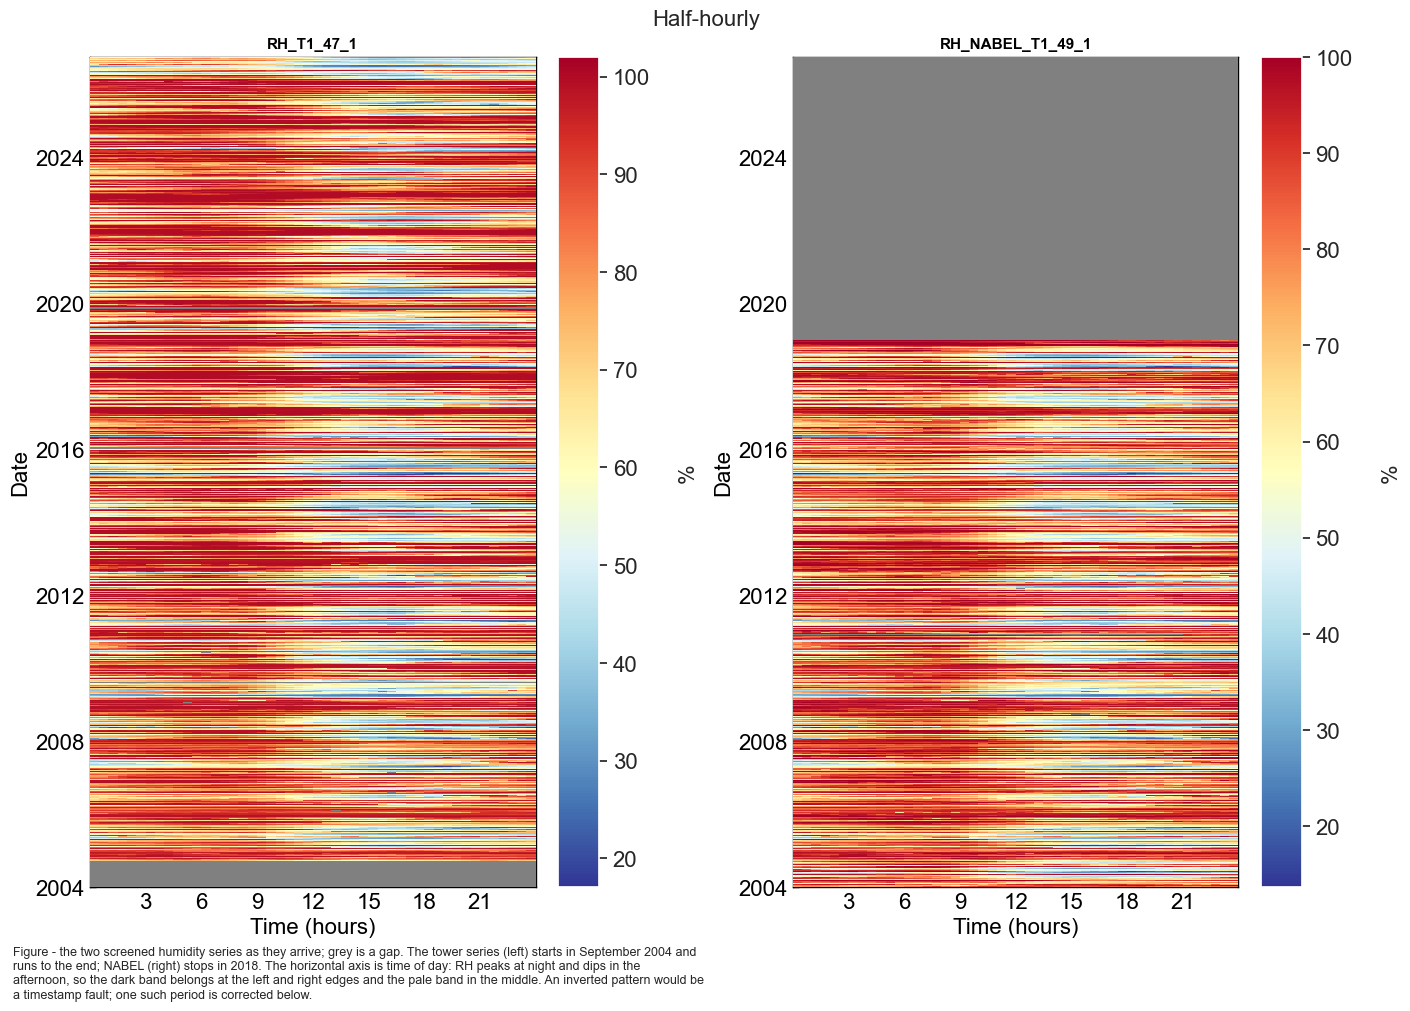

In [17]:
fig, axs = plt.subplots(ncols=2, figsize=(14, 10), dpi=100, layout="constrained")
fig.suptitle(f'Half-hourly', fontsize=16)
dv.plotting.HeatmapDateTime(series=rh_2004_2026[TARGET]).plot(
    ax=axs[0], cb_digits_after_comma=0, zlabel='%',
    format_style=dv.plotting.FormatStyle(title=TARGET, title_fontsize=11))
dv.plotting.HeatmapDateTime(series=rh_2004_2026[REFERENCE]).plot(
    ax=axs[1], cb_digits_after_comma=0, zlabel='%',
    format_style=dv.plotting.FormatStyle(title=REFERENCE, title_fontsize=11))
figcap(fig, "the two screened humidity series as they arrive; grey is a gap. The tower series "
            "(left) starts in September 2004 and runs to the end; NABEL (right) stops in 2018. "
            "The horizontal axis is time of day: RH peaks at night and dips in the afternoon, so "
            "the dark band belongs at the left and right edges and the pale band in the middle. "
            "An inverted pattern would be a timestamp fault; one such period is corrected below.")


***

## ✴️ Corrections


### Order of the correction steps

1. **Timestamp shift** (August 2012). Later windows refer to the corrected axis.
2. **Removal of the three damaged 2012 periods** and of the **two probe half-hours** of May 2025
   and June 2026.
   Some of the 2012 records read above 100%.
3. **`RH > 100%` offset correction.** Its offset is the daily mean of the records above 100%, so
   the damaged records must be gone first; otherwise they would set the offset subtracted from good
   data on neighbouring days. Step 2 reports how many removed records exceeded 100%.

The two reconstruction passes (NABEL, then MeteoSwiss Lägern) run last, so that every gap exists
and the offsets are fitted on *corrected* 47 m data. Step 2 creates gaps, so their provenance is
recorded before step 3; step 3 is checked not to write into gaps, as the correction in notebook
`03` does.

### Timestamp shift in August 2012
**Info from fieldbook entry 17 Aug 2012:**
>   adjusted the logger date and time. On Servertime (Computer System Time) 17.08.2012 12:31.42 the loggertime was 16.08.2012 08:06:00. Synchronized time at 17.08.2012 11:40:00 servertime. The logger data aquisition on the moxa embedded was restarted

A logger clock error affects every variable on that logger. The correction of notebooks `01`-`03`
is applied to `RH_T1_47_1` after a day-by-day lag search against NABEL (August baseline agreement
about 2.0 %, see the monthly table further down):

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-08-08 | -38.0 h | 16.49 | 21.78 |
| 2012-08-09 | +16.0 h | 5.61 | 13.54 |
| **2012-08-10** | **+15.5 h** | **1.13** | 11.38 |
| **2012-08-11** | **+15.5 h** | **1.56** | 13.88 |
| **2012-08-12** | **+15.5 h** | **2.23** | 26.30 |
| **2012-08-13** | **+15.5 h** | **2.13** | 25.01 |
| **2012-08-14** | **+15.5 h** | **1.20** | 18.57 |
| **2012-08-15** | **+15.5 h** | **3.37** | 37.26 |
| **2012-08-16** | **+15.5 h** | **1.68** | 21.57 |
| 2012-08-17 | 0 | 1.06 | 1.06 |

10 to 16 August lock onto `+15.5 h` and the error falls from 11-37 % to 1.1-3.4 %, the same clock
offset found for `SW_IN`, `TA` and `PPFD_IN`. After the shift, the search over 10-19 August returns
a best lag of 0 (RMSE 0.75-3.18). In the heatmaps below the *moist* band must return to the
night.

#### 📊 Plot: the August 2012 clock shift, panel by panel

RH_T1_47_1: 376 records moved +15.5 h, last shifted timestamp 2012-08-17 11:15:00


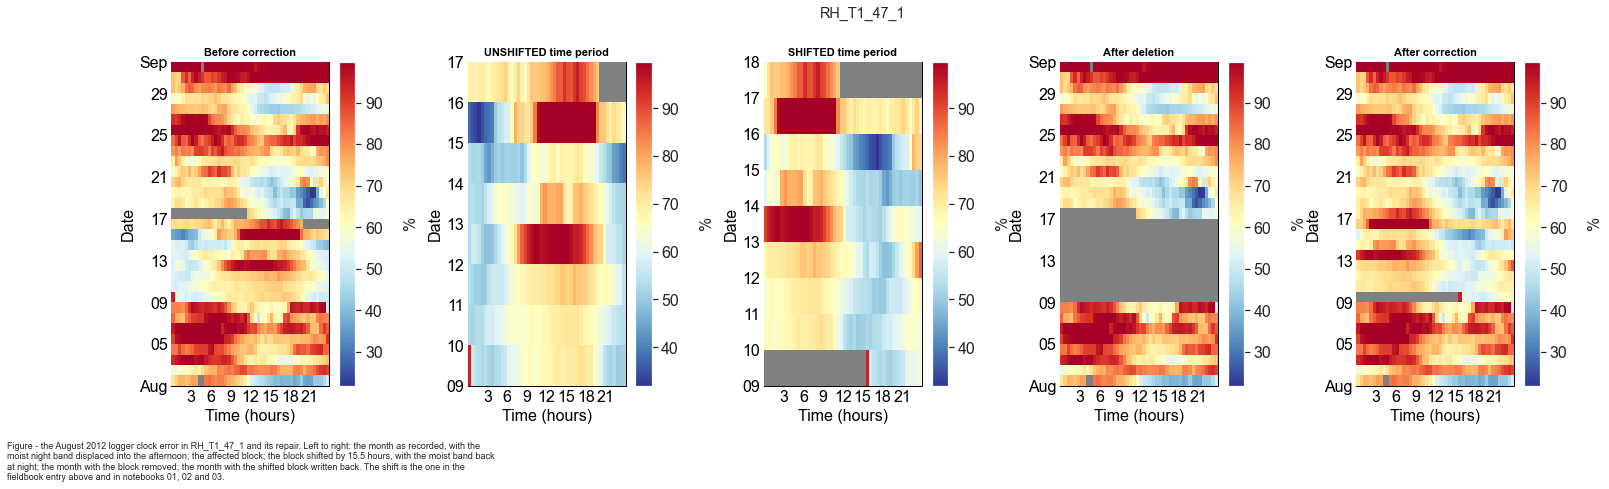

In [18]:
AFFECTED_VARS = [TARGET]
_df = rh_2004_2026.copy()

for av in AFFECTED_VARS:
    fig = plt.figure(figsize=(24, 6), dpi=72)
    fig.suptitle(f"{av}")
    gs = gridspec.GridSpec(1, 5)  # rows, cols
    gs.update(wspace=0.5, hspace=1, left=.1, right=.9, top=.85, bottom=.1)
    ax_before = fig.add_subplot(gs[0, 0])
    ax_unshifted = fig.add_subplot(gs[0, 1])
    ax_shifted = fig.add_subplot(gs[0, 2])
    ax_after = fig.add_subplot(gs[0, 3])
    ax_corrected = fig.add_subplot(gs[0, 4])

    # Show time period around issue, before correction
    _show_locs = (_df.index >= '2012-08-01 00:00') & (_df.index <= '2012-09-01 00:00')
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_before, cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title="Before correction", title_fontsize=11))

    # Get shifted time period
    _series_corrected = _df.loc[_show_locs, av].copy()
    # Identify shifted time period
    ISSUE_START = '2012-08-09 00:00'
    ISSUE_END = '2012-08-17 00:00'
    _shifted_locs = (_df.index >= ISSUE_START) & (_df.index <= ISSUE_END)
    _series_shifted = _df.loc[_shifted_locs, av].copy()
    _series_shifted = _series_shifted.dropna()
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_unshifted, cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title="UNSHIFTED time period", title_fontsize=11))

    # Shift by 15.5 hours during shifted time period, create corrected time series
    _series_shifted.index = _series_shifted.index + pd.Timedelta(hours=15.5)
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_shifted, cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title="SHIFTED time period", title_fontsize=11))

    # Delete data between start of issue and the last timestamp of shifted data
    _overwrite_locs = (_df.index >= ISSUE_START) & (_df.index <= _series_shifted.index[-1])
    _df.loc[_overwrite_locs, av] = np.nan
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_after, cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title="After deletion", title_fontsize=11))

    # Fill in corrected values
    _df.loc[_overwrite_locs, av] = _series_shifted
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_corrected, cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title="After correction", title_fontsize=11))

    figcap(fig, f"the August 2012 logger clock error in {av} and its repair. Left to right: the "
                f"month as recorded, with the moist night band displaced into the afternoon; the "
                f"affected block; the block shifted by 15.5 hours, with the moist band back at "
                f"night; the month with the block removed; the month with the shifted block "
                f"written back. The shift is the one in the fieldbook entry above and in "
                f"notebooks 01, 02 and 03.")
    print(f"{av}: {len(_series_shifted)} records moved +15.5 h, "
          f"last shifted timestamp {_series_shifted.index[-1]}")

#### 📋 Table: the series after the clock shift

In [19]:
rh_2004_2026 = _df.copy()
tabcap("the series after the August 2012 clock error has been shifted back onto the correct time axis")
rh_2004_2026

Table - the series after the August 2012 clock error has been shifted back onto the correct time
axis



,RH_T1_47_1,RH_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,96.366667
2004-01-01 00:45:00,NaN,95.566667
2004-01-01 01:15:00,NaN,92.200000
2004-01-01 01:45:00,NaN,91.300000
2004-01-01 02:15:00,NaN,92.633333
...,...,...
2026-09-30 21:45:00,54.148075,NaN
2026-09-30 22:15:00,55.498410,NaN
2026-09-30 22:45:00,56.956725,NaN


### Record the gaps that exist before any further correction

Captured before the removals and the `RH > 100%` correction, so that "never measured" means
exactly that. In notebook `03` a correction wrote `0` into missing nighttime records, and a mask
taken afterwards made 7,543 modelled values look measured.

In [20]:
never_measured = rh_2004_2026[TARGET].isna()
print(f"Never measured: {int(never_measured.sum()):,} of {len(rh_2004_2026):,} records")

Never measured: 15,434 of 398,832 records


### Power failure, late July to mid August 2012

Lag search against NABEL on the **uncorrected** axis:

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-07-27 | 0 | 1.86 | 1.86 |
| 2012-07-28 | 0 | 2.63 | 2.63 |
| 2012-07-29 | 0 | 2.31 | 2.31 |
| 2012-07-30 | 0 | 9.15 | 9.15 |
| 2012-07-31 | -25.5 h | 9.03 | 21.88 |
| 2012-08-01 | -1.0 h | 6.80 | 7.47 |
| 2012-08-03 | 0 | 6.45 | 6.45 |
| 2012-08-05 | +0.5 h | 7.86 | 7.98 |
| 2012-08-07 | -48.0 h | 12.61 | 13.82 |
| 2012-08-08 | -38.0 h | 16.49 | 21.78 |

From 30 July to 8 August the agreement is 6-16 % at any lag (normal: 2.0 %), so this is not a clock
problem; best lags near ±24 and ±48 h are aliases of the daily cycle. The fieldbook dates the
repair to the day the degradation ends:

> **09.08.2012** Fixed the power problem on the tower: replaced battery and replaced some fuses
> (there were many falsely placed or broken) and replaced the whole power supply
>
> **10.08.2012** Some problems remain with logger, maybe it's the WLAN (could not log in the last
> two weeks), restared programs

`SW_IN`, `TA` and `PPFD_IN` degrade over the same window on the same acquisition system,
consistent with one supply fault upstream of all four.

### Storm damage, late October to early November 2012

In this near-saturated period daily aliases dominate the best lag even on healthy days, so the
**zero-lag** column is the one to read:

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-10-26 | -34.0 h | 0.88 | 1.21 |
| 2012-10-27 | -27.5 h | 1.01 | 1.68 |
| 2012-10-28 | -48.0 h | 0.92 | 2.52 |
| 2012-10-29 | -47.5 h | 1.23 | 9.80 |
| 2012-10-30 | -48.0 h | 2.44 | 20.24 |
| 2012-11-01 | -48.0 h | 12.26 | 16.51 |
| 2012-11-04 | -22.0 h | 8.64 | 33.45 |
| 2012-11-07 | -34.0 h | 6.57 | 20.37 |
| 2012-11-09 | -43.5 h | 7.48 | 12.51 |
| 2012-11-10 | 0 | 4.11 | 4.11 |
| 2012-11-12 | -3.5 h | 1.38 | 1.40 |

Agreement collapses from 29 October, stays at 12-33 % through 9 November and recovers from 12
November, after the repair visit:

> **01.11.2012** Checked Forestfloor and Hut for broken sensors due to fallen trees and big branches
>
> **06.11.2012** checked all sensor cables. especialy the cables at the forest floor are sometimes
> strongly stressed. tried to unstress the cables

Both entries name *forest floor* sensors, not the 47 m instruments, so the link is circumstantial.

### Where `RH` disagrees with the shared windows

The windows are those of `SW_IN`, `TA` and `PPFD_IN`, kept **unchanged** so that all four products
exclude the same periods (notebook `07` combines `RH` with `TA` for VPD). Two are wider than the
`RH` evidence requires:

- **Window 1 starts 29 July**; `RH` is healthy that day (2.31 % against 2.0 %) and degrades from
  30 July.
- **Window 3 starts 28 October**; `RH` is acceptable that day (2.52 % at zero lag) and degrades
  from 29 October.
- **Window 2** (the tail after the last shifted value) holds 17 `RH` records that agree at 1.1 %.

About 113 good records are affected. NABEL covers all three windows, so they are reconstructed
(about 3 % uncertainty), not lost. Notebook `02` made the same trade-off for `TA`.

#### 📊 Plot: 2012 after removing the damaged periods

Removed 1215 measured records from RH_T1_47_1.
These become gaps here; the reconstruction section below fills them from NABEL.
Of these, 3 read above 100% - they would otherwise have
contributed to the offset of the RH>100% correction, which is why that step runs after this one.


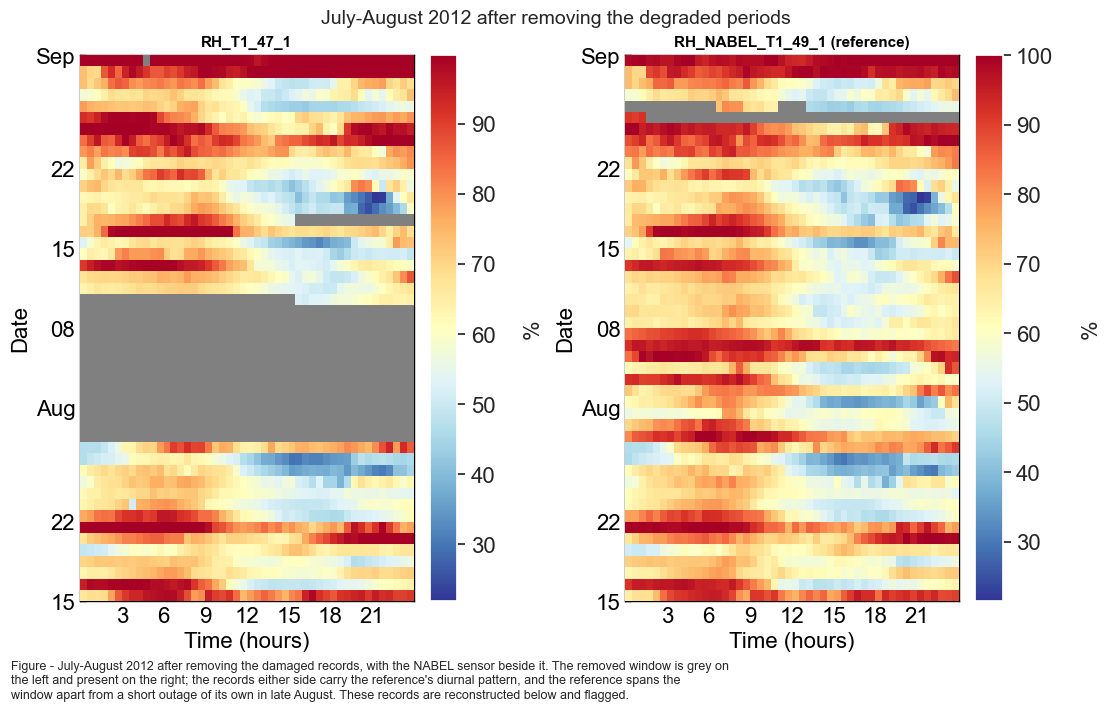

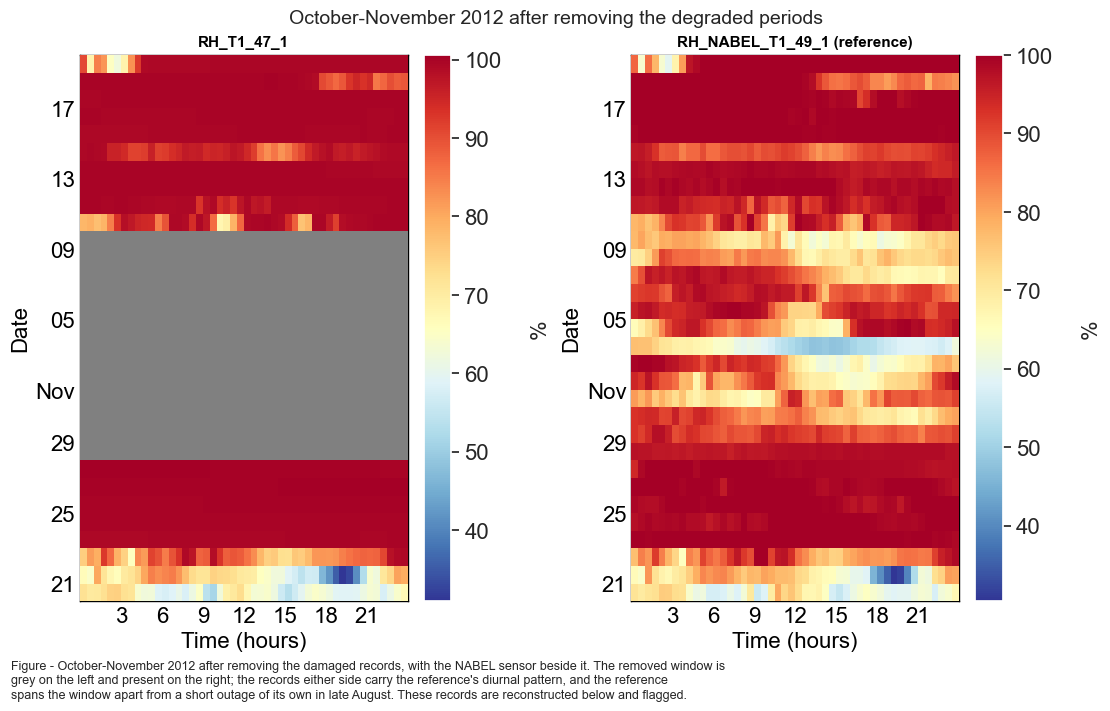

In [21]:
# Three damaged 2012 periods, documented in the fieldbook and not repairable. Windows are on the
# corrected time axis (after the +15.5 h shift) and identical to notebooks 01, 02 and 03.
BAD_WINDOWS_2012 = [
    ('2012-07-29 00:00', '2012-08-10 15:30'),  # tower power supply failure (fieldbook 09.08.2012)
    ('2012-08-17 15:30', '2012-08-18 00:00'),  # transitional tail after the last shifted value
    ('2012-10-28 00:00', '2012-11-10 00:00'),  # storm damage, stressed cables (fieldbook 01./06.11.2012)
]

# Recorded per record, not just counted: this is what separates flag 2 from flag 1 on export.
removed_here = pd.Series(False, index=rh_2004_2026.index)
_exceeded_and_removed = 0
for _start, _end in BAD_WINDOWS_2012:
    _locs = (rh_2004_2026.index >= _start) & (rh_2004_2026.index <= _end)
    _measured = _locs & rh_2004_2026[TARGET].notna()
    _exceeded_and_removed += int((rh_2004_2026.loc[_measured, TARGET] > 100).sum())
    removed_here |= _measured
    rh_2004_2026.loc[_locs, TARGET] = np.nan

print(f"Removed {int(removed_here.sum())} measured records from {TARGET}.")
print("These become gaps here; the reconstruction section below fills them from NABEL.")
print(f"Of these, {_exceeded_and_removed} read above 100% - they would otherwise have")
print(f"contributed to the offset of the RH>100% correction, which is why that step runs after this one.")

# One heatmap pair per affected period, with the NABEL sensor as the reference.
for _lo, _hi, _label in [('2012-07-15', '2012-09-01', 'July-August'),
                         ('2012-10-20', '2012-11-20', 'October-November')]:
    fig, axs = plt.subplots(ncols=2, figsize=(11, 7), dpi=100, layout="constrained")
    fig.suptitle(f'{_label} 2012 after removing the degraded periods', fontsize=14)
    _show = (rh_2004_2026.index >= _lo) & (rh_2004_2026.index <= _hi)
    dv.plotting.HeatmapDateTime(series=rh_2004_2026.loc[_show, TARGET]).plot(
        ax=axs[0], cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title=TARGET, title_fontsize=11))
    dv.plotting.HeatmapDateTime(series=rh_2004_2026.loc[_show, REFERENCE]).plot(
        ax=axs[1], cb_digits_after_comma=0, zlabel='%',
        format_style=dv.plotting.FormatStyle(title=f'{REFERENCE} (reference)', title_fontsize=11))
    figcap(fig, f"{_label} 2012 after removing the damaged records, with the NABEL sensor "
                f"beside it. The removed window is grey on the left and present on the right; the "
                f"records either side carry the reference's diurnal pattern, and the reference "
                f"spans the window apart from a short outage of its own in late August. These "
                f"records are reconstructed below and flagged.")


### The probe-handling and probe-swap half-hours

Two half-hours hold a probe being handled and represent no stable state of either probe, so both
are removed here and reconstructed with the other gaps (source code `5`, as in notebook `02`).

- **16 May 2025, 09:30-10:00 (`HANDLING_RECORD`).** The CS215 was handled between 09:32 and
  09:42, when the raw 1-min `TA_T1_47_1` jumps while the 35 m sensor does not (`02`, step 1️⃣1️⃣).
  It belongs to the period before the handling: its reconstruction offset is fitted on the code
  `7` era. Step 1️⃣1️⃣ treats this change.
- **5 June 2026, 11:00-11:30 (`SWAP_RECORD`).** The HygroVUE10 replaced the CS215: the raw 1-min
  `TA_T1_47_1`, measured by the same probe call, stops at 11:10 and resumes at 11:31, so the 30MIN
  value is a mean over at most ten minutes of CS215 output. It belongs to the period before the
  change: its offset is fitted on the code `6` era, and it receives no HygroVUE10 transfer. Step
  1️⃣2️⃣ treats this change.


#### 📋 Table: records around the probe handling and the probe swap


In [22]:
# The two probe half-hours: partial means of a probe being handled, removed so they are
# reconstructed rather than exported as measurements. Recorded in removed_here, like the 2012 windows.
assert HANDLING_RECORD + pd.Timedelta('30min') == RESET_START, (
    "the handling half-hour is no longer the record immediately before the first code-6 record")
assert SWAP_RECORD + pd.Timedelta('30min') == HV_START, (
    "the swap half-hour is no longer the record immediately before the first HygroVUE10 record")
PROBE_HALF_HOURS = [HANDLING_RECORD, SWAP_RECORD]
_values = rh_2004_2026.loc[PROBE_HALF_HOURS, TARGET]
assert _values.notna().all(), (
    "a probe half-hour is already missing, so removing it does nothing and the removal recorded "
    "below would be wrong")

tabcap("the records around the probe handling of 16 May 2025 and the probe swap of 5 June 2026 as "
       "screened, before the removal. Each half-hour removed holds a probe being handled")
_hour = pd.Timedelta('1h')
display(pd.concat([rh_2004_2026.loc[_t - _hour:_t + _hour + pd.Timedelta('30min'), [TARGET]]
                   for _t in PROBE_HALF_HOURS]))

removed_here.loc[PROBE_HALF_HOURS] = True
rh_2004_2026.loc[PROBE_HALF_HOURS, TARGET] = np.nan
for _t, _v in _values.items():
    print(f"Removed the half-hour {_t:%Y-%m-%d %H:%M} ({_v:.2f} %) from {TARGET}")
print(f"{int(removed_here.sum())} records removed in total.")


Table - the records around the probe handling of 16 May 2025 and the probe swap of 5 June 2026 as
screened, before the removal. Each half-hour removed holds a probe being handled



,RH_T1_47_1
TIMESTAMP_MIDDLE,
2025-05-16 08:45:00,49.033670
2025-05-16 09:15:00,49.191892
2025-05-16 09:45:00,47.833770
2025-05-16 10:15:00,44.936170
2025-05-16 10:45:00,41.918093
2025-05-16 11:15:00,40.410962
2026-06-05 10:15:00,94.231802
2026-06-05 10:45:00,94.438391
2026-06-05 11:15:00,88.010148


Removed the half-hour 2025-05-16 09:45 (47.83 %) from RH_T1_47_1
Removed the half-hour 2026-06-05 11:15 (88.01 %) from RH_T1_47_1
1217 records removed in total.


### December 2012 ventilation faults: checked, not applicable

The fieldbook records ventilation faults on the `RH`/`TA` units at **9 m and 27 m** in December
2012. The exported sensor is at **47 m** in its own ventilated housing, so its daily agreement with
NABEL is compared with the seasonal norm. Median daily RMSE against NABEL, 2004-2018, by month:

| month | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| median | 3.42 | 3.83 | 2.94 | 2.13 | 2.18 | 2.06 | 2.03 | 2.01 | 2.05 | 2.53 | 2.92 | 3.13 |

Agreement is about 2 % in summer and 3-4 % in winter, a known, unresolved property of this 47 m /
49 m pair and **not** a fault. December medians per year: 2010 `3.69`, 2011 `3.85`, **2012
`3.90`**, 2013 `3.53`, 2014 `3.99`, 2015 `3.93`, 2016 `7.12`, 2017 `8.72`.

December 2012 matches its neighbours and is far better than 2016 and 2017; five of its 30 days
exceed the all-year December 90th percentile, as expected by chance. **No correction is applied**,
and the December data are kept.

### `RH > 100%` correction

Values above 100% indicate sensor drift near saturation.
`dv.corrections.remove_relativehumidity_offset` derives a daily offset from the records above
100%, subtracts it from the series and clips what still exceeds 100%.

**Scope.** The library ffill/bfills the offset over the whole index, so one call on the full record
would also shift years without any exceedance: `+0.71 %` over 2004-2006 and `+0.133 %` from 2016
to the end of the record. `remove_rh_offset_by_year` runs it **per exceedance year**; other years
come through bit-identical. A year holding the June 2026 probe change is also split at
`HV_START`, so one probe's offset is never applied to the other.

**Guarantees**

- `RH <= 100` in every year: clipped where the correction runs, true by construction elsewhere.
  The export check asserts it.
- `RH >= 0` is **not** guaranteed, because the lower end is not clipped. With offsets of at most
  2.0 % it does not occur here, and the export check asserts it.
- A saturated sensor is **not** repaired: resolution lost near 100% is not recovered.

**Gap safety.** `NaN - x` is `NaN`, so gaps are retained. The cell below checks it, because the
analogous correction in notebook `03` turned 7,543 fills into apparent measurements.

#### 📋 Table: effect of the correction per year

In [23]:
# Kept for the sensor-identity section, which counts the records above 100 % before this
# correction. The pre-correction series is not recoverable after this cell.
RAW_BEFORE_CORRECTION = rh_2004_2026[TARGET].copy()
_before = RAW_BEFORE_CORRECTION.copy()
rh_2004_2026[TARGET], _exceed_years = remove_rh_offset_by_year(rh_2004_2026[TARGET])
_after = rh_2004_2026[TARGET]

_changed = (_after - _before).abs() > 1e-9
print(f"Correction applied in years: {_exceed_years}")
print(f"Records above 100%:  before {int((_before > 100).sum()):,}   after {int((_after > 100).sum()):,}")
print(f"Records changed:     {int(_changed.sum()):,} of {int(_before.notna().sum()):,} measured")
print(f"Largest change:      {float((_after - _before).abs().max()):.2f} %")
print(f"Untouched years:     {sorted(set(range(_before.index.year.min(), _before.index.year.max() + 1)) - set(_exceed_years))}")

# Gap safety: the correction must not invent a value where there was none.
_written_into_gaps = int((_before.isna() & _after.notna()).sum())
print(f"\nValues written into gaps: {_written_into_gaps}")
assert _written_into_gaps == 0, "correction wrote into gaps - the provenance flag would be wrong"

# Per-year effect, so an unexpectedly shifted year is visible rather than buried in the total.
_eff = pd.DataFrame({
    'exceeded_100_before': (_before > 100).groupby(_before.index.year).sum(),
    'records_changed': _changed.groupby(_changed.index.year).sum(),
    'mean_change': (_before - _after).groupby(_before.index.year).mean().round(3),
    'max_change': (_before - _after).groupby(_before.index.year).max().round(2),
})
_pe = pd.Timestamp(PERIOD_END)
tabcap(f"what the RH > 100 % correction did, per year. Years without an exceedance are not "
       f"touched; every year it runs in belongs to the analog probe, the evidence of drift used in "
       f"the sensor-identity section. {_pe:%Y} is partial and ends in {_pe:%B}")
_eff

Correction applied in years: [2007, 2010, 2011, 2012, 2013, 2014, 2015]
Records above 100%:  before 1,931   after 0
Records changed:     121,123 of 382,181 measured
Largest change:      2.00 %
Untouched years:     [2004, 2005, 2006, 2008, 2009, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

Values written into gaps: 0
Table - what the RH > 100 % correction did, per year. Years without an exceedance are not touched;
every year it runs in belongs to the analog probe, the evidence of drift used in the sensor-identity
section. 2026 is partial and ends in September



,exceeded_100_before,records_changed,mean_change,max_change
TIMESTAMP_MIDDLE,,,,
2004,0,0,0.000,0.0
2005,0,0,0.000,0.0
2006,0,0,0.000,0.0
2007,53,17507,0.312,1.1
2008,0,0,0.000,0.0
2009,0,0,0.000,0.0
2010,132,17351,0.140,0.3
2011,416,17499,0.454,2.0
2012,131,16308,0.108,0.6


### 📋 Table: distribution after the corrections

In [24]:
display(rh_2004_2026)
tabcap("the distribution of the two humidity series after every correction and before any reconstruction")
rh_2004_2026.describe()

,RH_T1_47_1,RH_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,96.366667
2004-01-01 00:45:00,NaN,95.566667
2004-01-01 01:15:00,NaN,92.200000
2004-01-01 01:45:00,NaN,91.300000
2004-01-01 02:15:00,NaN,92.633333
...,...,...
2026-09-30 21:45:00,54.148075,NaN
2026-09-30 22:15:00,55.498410,NaN
2026-09-30 22:45:00,56.956725,NaN


Table - the distribution of the two humidity series after every correction and before any
reconstruction



,RH_T1_47_1,RH_NABEL_T1_49_1
count,382181.000000,262314.000000
mean,79.136295,76.902333
std,19.058916,18.123961
min,16.990002,13.666667
25%,65.099386,63.900000
50%,82.750092,80.100000
75%,98.105968,92.933333
max,100.000000,100.000000


::: {.callout-note title="The NABEL series is not corrected"}
`RH_NABEL_T1_49_1` never exceeds 100% in this record, so the correction would change nothing and
is not applied. It is a reconstruction source and is not exported.
:::

***

## 🔎 Which sensor this is, and what the hardware change did to it

`RH_T1_47_1` and `TA_T1_47_1` come from **one instrument**, replaced with its logger on **21
January 2016**; in `TA` this required a two-term correction and a homogenised column (notebook
`02`). The steps below show that `RH` moved too:

1. the column holds **two probes**, a Rotronic MP101A (analog) until January 2016 and a Campbell
   CS215 (SDI-12) after, each named in the logger programs of its era;
2. the changeover is a **20-day outage** in the data, which dates the boundary;
3. NABEL **stops being independent in August 2018** and is cut there;
4. the series **steps upwards** by 2.1 to 3.3 percentage points of RH, and the pairs that move
   name the tower probe;
5. the **100 % ceiling** hides part of the step, which depends strongly on the humidity;
6. the step is present at **every hour** and larger at night, which rules out the shield
   mechanism of the `TA` step;
7. the replaced probe **had drifted**, on evidence that needs no reference;
8. there is **no step at the December 2021 screening splice**, although the median rises across
   those years;
9. the **maintenance record** identifies neither of the first two probes; it files a HygroVUE10
   here on 5 June 2026;
10. a humidity-dependent transfer across 2016 is **unstable when fitted on the era means** and
    **stable when fitted against NABEL at the break**, where it removes the step against
    Lägern; it depends on the reference, and the drift within the eras remains;
11. the CS215 **changed state in 2024-2025**, and in `RH` the change is one of the probe's
    temperature, not of its humidity element;
12. the HygroVUE10 of **June 2026** reads drier than the CS215 in vapour pressure and is
    transferred onto its level.

The consequences close the section.


### Helpers for this section

The logger programs and the fieldbook are read, not quoted, so a re-run re-derives the argument.
Both name people and this page is public, so every string taken from them is redacted as in
notebooks `01`, `02`, `03` and `08`.


In [25]:
# --- Fieldbook and logger-program redaction ----------------------------------------------------
# Both sources name people and this page is public, so every string taken from either passes
# through redact_people(). Same map and rules as notebooks 01, 02, 03 and 08; the map lives beside
# the export, outside this repository.
REDACT_MAP = Path(FIELDBOOK).with_name('redact_names.csv')
ALLOW_LIST = Path(FIELDBOOK).with_name('redact_allow.csv')


def unmapped_report_path(label: str) -> Path:
    """Where the unmapped-name candidates of one audit are written.

    Per label, because this notebook audits three sources: a single shared file would let a later
    audit overwrite an earlier one's findings.
    """
    _slug = re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')
    return Path(FIELDBOOK).with_name(f'redact_unmapped_{_slug}.txt')


def load_redactions(path=None) -> dict:
    """Load the name -> pseudonym map.

    Raises if the map is missing. That is the point: carrying on with redaction quietly disabled
    prints real names into a published page and looks exactly like success.
    """
    path = REDACT_MAP if path is None else Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"the redaction map is missing: {path}. Without it the names these files record would "
            f"print unredacted. Restore the file rather than skipping this.")
    tab = pd.read_csv(path, encoding='utf-8')
    missing = {'name', 'pseudonym'}.difference(tab.columns)
    if missing:
        raise ValueError(f"{path}: missing column(s) {sorted(missing)}.")
    pairs = {str(n).strip(): str(p).strip()
             for n, p in zip(tab['name'], tab['pseudonym']) if str(n).strip()}
    if not pairs:
        raise ValueError(f"{path}: holds no usable name -> pseudonym pairs.")
    return pairs


REDACTIONS = load_redactions()
# Longest surface form first, so a bare surname cannot corrupt a double-barrelled one that starts
# with it. Lookarounds rather than \b, because some forms end in an initial.
_REDACT_RX = re.compile(r'(?<!\w)(' + '|'.join(re.escape(n) for n in
                                               sorted(REDACTIONS, key=len, reverse=True))
                        + r')(?!\w)')


def redact_people(s) -> str:
    """Replace every mapped name with its stable pseudonym."""
    return _REDACT_RX.sub(lambda m: REDACTIONS[m.group(1)], str(s))


def strip_html(text) -> str:
    """Flatten one GIN fieldbook entry to plain text, with the people it names redacted."""
    flat = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return redact_people(re.sub(r'\s+', ' ', flat).strip())


_NAME_TOKEN = r"[A-ZÄÖÜ][\wÄÖÜäöüß'-]{1,20}"
_NAME_UNIT = _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r'){0,2}'
_NAME_SHAPES = (
    re.compile(r'\((' + _NAME_UNIT + r'(?:\s*[,+&]\s*' + _NAME_UNIT + r')*)\s*'
               r'(?:\d{1,2}\.\d{1,2}\.\d{4})?\)'),
    re.compile(r'(?:with|by|durch|von|gemaess)\s+(' + _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r')?)'),
)


def audit_unmapped_names(texts, label='fieldbook', write_report: bool = True) -> int:
    """Raise if any name-shaped token survived redaction.

    A newer export can name someone the map has never seen. Candidates are never printed - an
    exception message is stored in a notebook like any other output - so they go to a file beside
    the map and only the count is shown.
    """
    allow = set(pd.read_csv(ALLOW_LIST, encoding='utf-8')['term'].astype(str).str.strip())
    found = {}
    for _t in texts:
        for _rx in _NAME_SHAPES:
            for _m in _rx.finditer(str(_t)):
                for _tok in re.findall(_NAME_TOKEN, _m.group(1)):
                    if _tok.isupper() or any(ch.isdigit() for ch in _tok) or _tok in allow:
                        continue
                    found[_tok] = found.get(_tok, 0) + 1
    if found:
        _report = unmapped_report_path(label)
        if write_report:
            _report.write_text(
                '\n'.join(f'{n}\t{t}' for t, n in sorted(found.items(), key=lambda kv: -kv[1])),
                encoding='utf-8')
        raise ValueError(
            f"{label}: {len(found)} name-shaped token(s) survived redaction. They are deliberately "
            f"NOT shown here - see {_report}. Add the people to redact_names.csv and the "
            f"technical terms to redact_allow.csv, then re-run.")
    print(f"  {label}: no unmapped name-shaped tokens ({len(allow)} allowlisted terms)")
    return 0


def program_excerpt(path, pattern: str, before: int = 6, after: int = 4, expect: int = 1) -> str:
    """The lines of a logger program around `pattern`, redacted.

    Only the matched instruction is returned, never the file header: these programs are signed by
    their authors. Raises unless the pattern matches exactly `expect` times. Both directions
    matter: no match reads as 'the program does not measure this', and an over-broad pattern
    quietly prints the wrong instruction next to the argument it is supposed to support.
    """
    lines = Path(path).read_text(encoding='latin-1').splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.search(pattern, line):
            lo, hi = max(0, i - before), min(len(lines), i + after + 1)
            blocks.append('\n'.join(lines[lo:hi]))
    if len(blocks) != expect:
        raise ValueError(f"{Path(path).name}: {pattern!r} matched {len(blocks)} time(s), expected "
                         f"{expect}. The program layout has changed, the wrong file is configured, "
                         f"or the pattern is not specific enough.")
    return redact_people('\n\n'.join(blocks))


def calibration_constants(excerpt: str) -> dict:
    """The multiplier and offset of one measurement instruction, parsed from its own text.

    The CR10X lists the two numbers as numbered parameters of a `Volt (SE)` instruction; the
    CR1000 passes them as the last two arguments of a `VoltSe(...)` or `VoltDiff(...)` call. Both
    shapes are matched on their own terms.

    Raises if either number cannot be found. That failure path is not a defect here, it is the
    argument: the CR1000 reads this sensor over **SDI-12**, which returns finished engineering
    units, so its instruction carries no multiplier and no offset at all and this function raises
    on it. A version that returned an empty result instead would let the two eras be compared by
    having nothing to disagree about.
    """
    if 'Mult' in excerpt:                                    # CR10X parameter listing
        _m = re.search(r'^\s*\d+:\s*([\d.]+)\s+Mult', excerpt, re.M)
        _o = re.search(r'^\s*\d+:\s*([\d.]+)\s+Offset', excerpt, re.M)
        tokens = [_m.group(1) if _m else None, _o.group(1) if _o else None]
    else:                                                    # CR1000 VoltSe/VoltDiff call
        _call = re.search(r'Volt(?:Se|Diff)\s*\(([^)]*)\)', excerpt)
        _args = [a.strip() for a in _call.group(1).split(',')] if _call else []
        tokens = _args[-2:] if len(_args) >= 2 else [None, None]
    values = []
    for _tok in tokens:
        if _tok is None:
            raise ValueError("could not parse a multiplier and an offset from the instruction - "
                             "the program language or the layout has changed, or the measurement "
                             "is not an analog voltage at all")
        values.append(float(_tok))
    return {'multiplier': values[0], 'offset': values[1]}


#### Negative controls

Each helper is fed input it must refuse, before it is trusted.


In [26]:
# Every failure path is exercised before anything is read.
try:
    program_excerpt(PROGRAM_CR1000, r'ThisPatternIsNotInAnyLoggerProgram')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on a pattern that does not occur: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern that does not occur.")

# ... and on one that occurs more than once, which would print the wrong instruction.
try:
    program_excerpt(PROGRAMS_CR10X[0], r'RelHum')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on an over-broad pattern: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern matching more than once.")

# 'Ada Lovelace' is nobody at this site, so the control can spell her out without disclosing
# anything - and it writes no report, so the real one is not overwritten by a test.
try:
    audit_unmapped_names(['12.05.2019 (Ada Lovelace) replaced the logger battery'],
                         'positive control', write_report=False)
except ValueError:
    print("OK, the unknown-name net fired on a name that is not in the map")
else:
    raise AssertionError("(!) the unknown-name net did not fire on an unmapped name.")

# The constant parser must refuse an instruction it cannot read; for this variable that is the
# real SDI-12 instruction of the CR1000 program (step 1 below).
try:
    calibration_constants('SDI12Recorder(TARH_T1_47_1(),3,"0","M!",1,0)')
except ValueError as _exc:
    print(f"OK, calibration_constants raised on an instruction with no constants: {_exc}")
else:
    raise AssertionError("(!) calibration_constants accepted an instruction carrying no constants.")


OK, program_excerpt raised on a pattern that does not occur: CH-LAE_iDL_T1_47_1.CR1: 'ThisPatternIsNotInAnyLoggerProgram' matched 0 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, program_excerpt raised on an over-broad pattern: LAEGEREN.20040526.CSI: 'RelHum' matched 4 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, the unknown-name net fired on a name that is not in the map
OK, calibration_constants raised on an instruction with no constants: could not parse a multiplier and an offset from the instruction - the program language or the layout has changed, or the measurement is not an analog voltage at all


### 1️⃣ Two probes, one column

The six surviving CR10X programs (2004-2006) measure a **Rotronic MP101A**, named in their
comments, on a single-ended analog channel at multiplier `0.1` and offset `0` (0-1000 mV for
0-100 % RH). The CR1000 program of the changeover reads a **Campbell CS215** over SDI-12 and fills
`TA_T1_47_1` and `RH_T1_47_1` as one variable pair from one sensor call.

::: {.callout-note title="There is no multiplier to compare after 2016"}
SDI-12 returns engineering units, so the CR1000 instruction has no multiplier or offset; the later
calibration lives inside the probe. The two eras **cannot** be compared by their conversions, as
notebook `01` does for `SW_IN`, and the argument rests on the sensor identity and the data. The
cell below shows the constant parser raising on the SDI-12 instruction.
:::


#### 📋 Table: RH conversion per logger program

In [27]:
# Which instrument the column is, read from the logger programs. Every CR10X program is parsed: a
# multiplier changed inside that era would put a step in the record unrelated to 2016.
CR10X_RH, _cr10x_excerpts = {}, []
for _p in PROGRAMS_CR10X:
    _ex = program_excerpt(_p, r'Loc \[ RelHum', before=4, after=3)
    _cr10x_excerpts.append(_ex)
    CR10X_RH[Path(_p).name] = calibration_constants(_ex)

_probe_comment = program_excerpt(PROGRAMS_CR10X[0], r'Rotronic MP101A', before=1, after=1)
print(f"--- {Path(PROGRAMS_CR10X[0]).name}: the probe, named in the program's own comment")
print(_probe_comment)
print(f"\n--- {Path(PROGRAMS_CR10X[0]).name}: how its relative-humidity output is converted")
print(_cr10x_excerpts[0])

# The CR1000 side: the successor is a Campbell CS215, and TA and RH arrive from one probe in one
# call, which ties this variable to the 1.3 degC step notebook 02 measures in TA.
_ex_decl = program_excerpt(PROGRAM_CR1000, r'Alias TARH_T1_47_1\(2\)', before=2, after=0)
_ex_sdi = program_excerpt(PROGRAM_CR1000, r'SDI12Recorder\(TARH_T1_47_1', before=1, after=0)
print(f"\n--- {Path(PROGRAM_CR1000).name}: the declaration")
print(_ex_decl)
print(f"\n--- {Path(PROGRAM_CR1000).name}: the measurement")
print(_ex_sdi)

audit_unmapped_names(_cr10x_excerpts + [_probe_comment, _ex_decl, _ex_sdi], 'logger programs')

tabcap("the conversion every surviving CR10X program applies to the RH channel, oldest first. "
       "All six agree, so nothing inside the analog era rescaled the series; the CR1000 row is "
       "empty because SDI-12 has no multiplier")
_prog = pd.DataFrame(CR10X_RH).T
_prog.index.name = 'logger program'
_prog['probe'] = 'Rotronic MP101A'
_prog['acquisition'] = 'single-ended analog voltage, channel 3'
_prog.loc[Path(PROGRAM_CR1000).name] = [np.nan, np.nan, 'Campbell CS215', 'SDI-12 address 0, M!']
display(_prog)

# One conversion across every program of the analog era.
_mults = {v['multiplier'] for v in CR10X_RH.values()}
_offsets = {v['offset'] for v in CR10X_RH.values()}
print(f"\ndistinct multipliers over the {len(CR10X_RH)} CR10X programs: {sorted(_mults)}")
print(f"distinct offsets: {sorted(_offsets)}")
assert _mults == {0.1} and _offsets == {0.0}, (
    "the CR10X programs no longer all apply the same conversion to the relative-humidity channel, "
    "so a step inside the analog era is possible and this section must be re-derived")

# The CR1000 instruction carries no constants to compare: after 2016 there is no conversion to read.
try:
    calibration_constants(_ex_sdi)
except ValueError:
    print("\nThe CR1000 instruction carries no multiplier and no offset: SDI-12 returns finished "
          "engineering units, so the sensor's calibration lives inside the probe where no logger "
          "program records it. The two eras therefore cannot be compared by their conversions, "
          "and the rest of this section rests on the sensor identity above and on the data.")
else:
    raise AssertionError("(!) the CR1000 instruction now parses as an analog conversion, so this "
                         "sensor is no longer read over SDI-12 and this step must be re-derived.")


--- LAEGEREN.20040526.CSI: the probe, named in the program's own comment
;--------------------------------------------------------
; Rotronic MP101A temperature and relative humidity probe
;--------------------------------------------------------

--- LAEGEREN.20040526.CSI: how its relative-humidity output is converted
8:  Volt (SE) (P1)
 1: 1        Reps
 2: 35       2500 mV 50 Hz Rejection Range
 3: 3        SE Channel
 4: 19       Loc [ RelHum    ]
 5: 0.1      Mult
 6: 0.0      Offset


--- CH-LAE_iDL_T1_47_1.CR1: the declaration
Public TARH_T1_47_1(2)
Alias TARH_T1_47_1(1)=TA_T1_47_1
Alias TARH_T1_47_1(2)=RH_T1_47_1

--- CH-LAE_iDL_T1_47_1.CR1: the measurement
		'C'CS215 Temperature & Relative Humidity Sensor measurements 'TA_T1_47_1' and 'RH_T1_47_1'
		SDI12Recorder(TARH_T1_47_1(),3,"0","M!",1,0)
  logger programs: no unmapped name-shaped tokens (58 allowlisted terms)
Table - the conversion every surviving CR10X program applies to the RH channel, oldest first. All
six agree, so n

,multiplier,offset,probe,acquisition
logger program,,,,
LAEGEREN.20040526.CSI,0.1,0.0,Rotronic MP101A,"single-ended analog voltage, channel 3"
LAEGEREN.20040810.CSI,0.1,0.0,Rotronic MP101A,"single-ended analog voltage, channel 3"
LAEGEREN.20041228.CSI,0.1,0.0,Rotronic MP101A,"single-ended analog voltage, channel 3"
LAEGEREN.20050818.CSI,0.1,0.0,Rotronic MP101A,"single-ended analog voltage, channel 3"
LAEGEREN.20050914.CSI,0.1,0.0,Rotronic MP101A,"single-ended analog voltage, channel 3"
LAEGEREN.20060524.csi,0.1,0.0,Rotronic MP101A,"single-ended analog voltage, channel 3"
CH-LAE_iDL_T1_47_1.CR1,NaN,NaN,Campbell CS215,"SDI-12 address 0, M!"



distinct multipliers over the 6 CR10X programs: [0.1]
distinct offsets: [0.0]

The CR1000 instruction carries no multiplier and no offset: SDI-12 returns finished engineering units, so the sensor's calibration lives inside the probe where no logger program records it. The two eras therefore cannot be compared by their conversions, and the rest of this section rests on the sensor identity above and on the data.


### 2️⃣ The changeover is an outage in the data

The boundary is read from the series, not from the fieldbook: the tower stopped recording, probe
and logger were replaced, and recording resumed. Both dates come from the record.


In [28]:
# The changeover as it appears in the data: both dates come from the series, not the fieldbook.
_around = rh_2004_2026.loc['2015-11-01':'2016-03-01', TARGET].dropna()
LAST_ANALOG = _around.loc[:'2016-01-15'].index[-1]
BREAK = _around.loc['2016-01-15':].index[0]

print(f"last record of the analog era: {LAST_ANALOG:%d %b %Y %H:%M}")
print(f"first record of the SDI-12 era: {BREAK:%d %b %Y %H:%M}")
print(f"the tower recorded nothing for {(BREAK - LAST_ANALOG).days} days in between")

# The same boundary notebook 02 uses for TA, which is the point: one probe delivers both.
assert BREAK == pd.Timestamp('2016-01-21 14:15'), (
    f"the changeover has moved to {BREAK}, which is no longer the boundary notebook 02 uses for "
    f"TA_T1_47_1 - the two variables come from one probe and must share one boundary")
assert (BREAK - LAST_ANALOG).days > 14, (
    "the outage at the changeover has shrunk, so the two eras may now be separated by less than "
    "the gap this section treats as the sensor swap")


last record of the analog era: 31 Dec 2015 23:45
first record of the SDI-12 era: 21 Jan 2016 14:15
the tower recorded nothing for 20 days in between


### The third series

`RH_LAE_MS` is the only series spanning the whole record and the second reconstruction source, so
it is loaded and its alignment asserted here, once. Its `TIMESTAMP_END` index is shifted back 15
minutes; the guard correlates it with the tower series at offsets `-1/0/+1` and asserts that `0`
wins, since a mis-shifted reference would fit the wrong daily cycle unnoticed.

Lägern sits at 845 m, the tower sensor 47 m above a ridge at about 690 m. Their humidity offset is
real and seasonal, not an instrument error, and is absorbed by the monthly offsets; every
comparison here reads a *change* in a difference.


In [29]:
# The third series, also the second reconstruction source. TIMESTAMP_END -> TIMESTAMP_MID.
rh_ref = pd.read_parquet(REFPATH)[[REFCOL]]
rh_ref.index = rh_ref.index - pd.Timedelta(minutes=15)   # TIMESTAMP_END -> TIMESTAMP_MID
rh_ref.index.name = rh_2004_2026.index.name
lae = rh_ref[REFCOL].reindex(rh_2004_2026.index)

# Alignment guard. Nothing is reconstructed yet, so every tower value is a measurement. RH has a
# clear diurnal cycle, so all overlapping records are used.
_scores = {}
for _off in (-1, 0, 1):
    _j = pd.concat([rh_2004_2026[TARGET].rename('t'), lae.shift(_off).rename('r')],
                   axis=1).dropna()
    _scores[_off] = _j['t'].corr(_j['r'])
    print(f"  offset {_off:+d} x 30min: corr {_scores[_off]:.4f}")
assert max(_scores, key=_scores.get) == 0, f"reference is mis-aligned: {_scores}"
print("OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.")
print(f"\n{REFCOL} available for {lae.notna().mean() * 100:.2f} % of all records, "
      f"{lae.first_valid_index()} -> {lae.last_valid_index()}")


  offset -1 x 30min: corr 0.9383
  offset +0 x 30min: corr 0.9441
  offset +1 x 30min: corr 0.9364
OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.

RH_LAE_MS available for 99.55 % of all records, 2004-02-01 00:45:00 -> 2026-09-30 23:45:00


### 3️⃣ One reference stops being a reference in August 2018

From August 2018 the NABEL column reproduces the tower column to better than 0.05 % RH in every
half-hour, which two independent instruments do not do. The date is derived below and NABEL is cut
there, for the comparisons **and** for the reconstruction, where an offset fitted against a copy of
the target would be zero and turn reconstruction into copying. `TA_NABEL_T1_49_1` stays
independent, so this concerns one ingested column, not the NABEL feed.


#### 📋 Table: share of identical NABEL and tower records

In [30]:
# From August 2018 the NABEL column copies the tower column (agreement better than 0.05 % RH in
# every half-hour). The date is derived, so a re-ingestion that moves it cannot leave this section
# comparing the tower against itself.
_pair = rh_2004_2026[[TARGET, REFERENCE]].dropna()
_identical = ((_pair[TARGET] - _pair[REFERENCE]).abs() < 0.05).resample('MS').mean().dropna()
_dup = _identical[_identical > 0.5]
NABEL_UNTIL = _dup.index[0].normalize() if len(_dup) else None

tabcap("share of half-hours in which the NABEL and tower columns are the same number, by month, "
       "over the last two years of the NABEL record. Where it reaches one, the column has stopped "
       "being a reference")
display(_identical.loc['2017-01':].round(3).rename('share identical').to_frame())

print(f"NABEL duplicates the tower from {_dup.index[0]:%b %Y} onwards "
      f"({len(_dup)} months; at most {100 * _identical.loc[:_dup.index[0]].iloc[:-1].max():.1f} % "
      f"of any earlier month)")
print(f"-> every comparison below cuts the NABEL reference at {NABEL_UNTIL:%d %b %Y}")

assert NABEL_UNTIL is not None, (
    "the NABEL column no longer duplicates the tower anywhere, so the cut this section applies is "
    "either unnecessary or the duplication has moved - re-derive it before removing the cut")
assert NABEL_UNTIL > BREAK, (
    "the NABEL reference now stops being independent before the 2016 changeover, which leaves the "
    "later era with no co-located witness and makes the attribution below impossible")

# The reference, cut where it stops being independent, for the comparisons AND the reconstruction:
# an offset fitted where the reference IS the target would be zero and turn it into a copy.
NABEL_REF = rh_2004_2026[REFERENCE].where(rh_2004_2026.index < NABEL_UNTIL)

# The cut must not cost a reconstruction: the dropped months hold no gap in the target.
_cut = ((rh_2004_2026.index >= NABEL_UNTIL) &
        (rh_2004_2026.index <= rh_2004_2026[REFERENCE].last_valid_index()))
_lost = int(rh_2004_2026.loc[_cut, TARGET].isna().sum())
print(f"records the cut removes from the reference: {int(_cut.sum()):,}; "
      f"of those, gaps in {TARGET}: {_lost}")
assert _lost == 0, (
    f"{_lost} records in the duplicated months are gaps in the target, so cutting the reference "
    f"there costs reconstructions - decide explicitly what should fill them instead")

# The three series the rest of this section compares, on one frame. Nothing else is filtered.
TOWER_L, NABEL_L, MS_L = 'tower 47 m', 'NABEL 49 m', 'MeteoSwiss'
rh3 = pd.DataFrame({TOWER_L: rh_2004_2026[TARGET], NABEL_L: NABEL_REF, MS_L: lae})
print(f"\nusable records per series: "
      + ", ".join(f"{_c} {int(rh3[_c].notna().sum()):,}" for _c in rh3.columns))


Table - share of half-hours in which the NABEL and tower columns are the same number, by month, over
the last two years of the NABEL record. Where it reaches one, the column has stopped being a
reference



,share identical
TIMESTAMP_MIDDLE,
2017-01-01,0.001
2017-02-01,0.008
2017-03-01,0.005
2017-04-01,0.006
2017-05-01,0.017
2017-06-01,0.003
2017-07-01,0.005
2017-08-01,0.008
2017-09-01,0.015


NABEL duplicates the tower from Aug 2018 onwards (5 months; at most 22.7 % of any earlier month)
-> every comparison below cuts the NABEL reference at 01 Aug 2018
records the cut removes from the reference: 7,344; of those, gaps in RH_T1_47_1: 0

usable records per series: tower 47 m 382,181, NABEL 49 m 254,970, MeteoSwiss 397,036


### 4️⃣ Reading the three series against each other

A response change at one of the three series (tower, NABEL at 49 m, MeteoSwiss Lägern at 2.5 km)
moves every pairwise comparison it appears in and no other, as in notebook `02` for `TA` and
`RADIATION_SENSOR_CONTINUITY.ipynb` for the radiation sensors. NABEL has its own logger and
housing, and nothing at this tower can move MeteoSwiss. **A comparison says two sensors separated,
never which of them left**; the pattern of pairs names it.

Yearly levels use full years up to `LAST_FULL_YEAR`, so the partial 2026 is not compared with full
years.


In [31]:
# RH is bounded and its errors are additive, so every comparison is a DIFFERENCE, in percentage
# points of RH (the ratio machinery of notebooks 01 and 03 is for radiation). Controls in the helper:
#   Season: the difference has a seasonal cycle (about +3.9 % RH in February, +0.4 % RH in August),
#     so medians are taken per calendar month and then averaged over months.
#   Sample size: a month with fewer than MIN_RECORDS half-hours is dropped; a pair with no
#     populated month raises.
#   Partial year: only years up to LAST_FULL_YEAR enter, so January-September 2026 is not
#     compared with full years.
MIN_RECORDS = 100
SATURATED = 95.0        # % RH; above this the ceiling starts to clip a step
QUIET_YEARS = (2007, 2015)

PAIRS = [(TOWER_L, NABEL_L), (TOWER_L, MS_L), (NABEL_L, MS_L)]
PAIR_LABELS = [f'{_a} - {_b}' for _a, _b in PAIRS]
TOWER_PAIRS = [_l for _l in PAIR_LABELS if TOWER_L in _l]
REF_PAIR = f'{NABEL_L} - {MS_L}'


def diff_by_year(a: str, b: str, mask: pd.Series = None, min_records: int = MIN_RECORDS
                 ) -> pd.Series:
    """Month-matched yearly mean of `a - b`, in percentage points of RH."""
    _j = rh3.loc[rh3.index.year <= LAST_FULL_YEAR, [a, b]].dropna()
    if mask is not None:
        _j = _j[mask.reindex(_j.index).fillna(False)]
    _d = _j[a] - _j[b]
    _m = _d.groupby([_d.index.year, _d.index.month]).median()
    _n = _d.groupby([_d.index.year, _d.index.month]).count()
    _m = _m[_n >= min_records]
    if _m.empty:
        raise ValueError(f"{a} - {b}: no calendar month reaches {min_records} records, so a yearly "
                         f"level cannot be built from this selection")
    return _m.groupby(level=0).mean()


def levels_and_changes(mask=None):
    """Yearly level of every pair, and the change from one year to the next."""
    _lvl = pd.DataFrame({f'{_a} - {_b}': diff_by_year(_a, _b, mask) for _a, _b in PAIRS})
    _lvl.index.name = 'YEAR'
    return _lvl, _lvl.diff()


# Unsaturated: every series with a value in the half-hour is below SATURATED. A step is compressed
# near the 100 % ceiling, and this site has a median near 83 % RH with a pile-up at 100.
UNSATURATED = rh3.max(axis=1) < SATURATED
print(f"median tower RH: {rh3[TOWER_L].median():.1f} %   "
      f"half-hours at or above 99.9 %: {100 * (rh3[TOWER_L] >= 99.9).mean():.1f} %")
print(f"unsaturated half-hours (every available series below {SATURATED:.0f} %): "
      f"{int(UNSATURATED.sum()):,} of {len(rh3):,}")


median tower RH: 82.8 %   half-hours at or above 99.9 %: 11.1 %
unsaturated half-hours (every available series below 95 %): 260,471 of 398,832


In [32]:
# diff_by_year must refuse a selection holding almost nothing.
try:
    diff_by_year(TOWER_L, NABEL_L, min_records=1_000_000)
except ValueError as _exc:
    print(f"OK, diff_by_year raised on a selection no month can fill: {_exc}")
else:
    raise AssertionError("(!) diff_by_year accepted a threshold no calendar month can meet.")

try:
    diff_by_year(TOWER_L, NABEL_L, mask=pd.Series(False, index=rh3.index))
except ValueError as _exc:
    print(f"OK, diff_by_year raised on an empty selection: {_exc}")
else:
    raise AssertionError("(!) diff_by_year accepted a mask that selects nothing.")


OK, diff_by_year raised on a selection no month can fill: tower 47 m - NABEL 49 m: no calendar month reaches 1000000 records, so a yearly level cannot be built from this selection
OK, diff_by_year raised on an empty selection: tower 47 m - NABEL 49 m: no calendar month reaches 100 records, so a yearly level cannot be built from this selection


#### 📋 Table: pairwise differences by year

In [33]:
BREAK_YEAR = BREAK.year

LEVEL, CHANGE = levels_and_changes()
tabcap(f"difference between each pair of series per year, in percentage points of RH, and its "
       f"change from the year before; full years to {LAST_FULL_YEAR}. A response change at one "
       f"sensor moves every pair it appears in and no other: read the shape of the {BREAK_YEAR} "
       f"row, not its largest entry")
display(pd.concat([LEVEL.round(2).add_suffix('   level'),
                   CHANGE.round(2).add_suffix('   change')], axis=1))

Table - difference between each pair of series per year, in percentage points of RH, and its change
from the year before; full years to 2025. A response change at one sensor moves every pair it
appears in and no other: read the shape of the 2016 row, not its largest entry



,tower 47 m - NABEL 49 m level,tower 47 m - MeteoSwiss level,NABEL 49 m - MeteoSwiss level,tower 47 m - NABEL 49 m change,tower 47 m - MeteoSwiss change,NABEL 49 m - MeteoSwiss change
YEAR,,,,,,
2004,1.03,-0.08,-1.88,NaN,NaN,NaN
2005,0.65,-0.48,-1.02,-0.39,-0.39,0.86
2006,-0.03,-0.65,-0.66,-0.68,-0.18,0.36
2007,-0.08,-1.35,-1.26,-0.04,-0.70,-0.61
2008,0.77,-2.08,-2.87,0.84,-0.73,-1.60
2009,0.71,-2.22,-3.17,-0.05,-0.15,-0.30
2010,1.00,-2.15,-3.66,0.29,0.08,-0.49
2011,0.74,-2.15,-3.33,-0.26,-0.00,0.33
2012,1.23,-2.25,-4.07,0.49,-0.09,-0.74


#### 📋 Table: change into 2016 against an ordinary year

In [34]:
# The threshold is taken from what these comparisons do in a year when nothing happened.
QUIET = CHANGE.loc[QUIET_YEARS[0]:QUIET_YEARS[1]].abs().median()
tabcap(f"the one-year change into {BREAK_YEAR} against the same statistic in an ordinary year. "
       f"The last column, their ratio, is the number to read")
_break_table = pd.DataFrame({
    f'change into {BREAK_YEAR} (% RH)': CHANGE.loc[BREAK_YEAR],
    f'median |change|, {QUIET_YEARS[0]}-{QUIET_YEARS[1]} (% RH)': QUIET,
    'largest |change| elsewhere (% RH)':
        CHANGE.drop(index=BREAK_YEAR).abs().max(),
    'times the ordinary year': (CHANGE.loc[BREAK_YEAR].abs() / QUIET),
})
_break_table.index.name = 'pair'
display(_break_table.round(2))

EVENT_FACTOR = 3.0   # a change worth calling an event is several times an ordinary year's
assert EVENT_FACTOR > 1.0, "the event factor no longer distinguishes an event from ordinary scatter"

for _l in TOWER_PAIRS:
    _f = _break_table.loc[_l, 'times the ordinary year']
    _c = _break_table.loc[_l, f'change into {BREAK_YEAR} (% RH)']
    print(f"  {_l}: {_c:+.2f} % RH into {BREAK_YEAR}, "
          f"{_f:.1f} times the {QUIET[_l]:.2f} % RH of an ordinary year")
    assert _c > 0 and _f > EVENT_FACTOR, (
        f"{_l} no longer steps upwards at {BREAK_YEAR} by more than {EVENT_FACTOR} times an "
        f"ordinary year's change - the step this section reports must be re-derived")
    assert abs(_c) > _break_table.loc[_l, 'largest |change| elsewhere (% RH)'], (
        f"{_l}: the change into {BREAK_YEAR} is no longer the largest anywhere in the record, "
        f"which is what makes it identifiable as an event rather than as scatter")

# The pair that decides which sensor moved. Both references are outside this tower's acquisition
# system (NABEL has its own logger, MeteoSwiss is 2.5 km away); had they moved against each other,
# the change could be at either.
_ref_change = CHANGE.loc[BREAK_YEAR, REF_PAIR]
print(f"\n  {REF_PAIR}: {_ref_change:+.2f} % RH into {BREAK_YEAR}, "
      f"{abs(_ref_change) / QUIET[REF_PAIR]:.1f} times an ordinary year")
assert abs(_ref_change) < EVENT_FACTOR * QUIET[REF_PAIR], (
    "the two references now move against each other at the changeover as well, so the step can no "
    "longer be attributed to the tower sensor and this whole section must be re-derived")
print(f"\nBoth pairs containing the tower sensor step upwards at {BREAK_YEAR} by roughly ten "
      f"times an ordinary year's change, and the pair between the two references does not move at "
      f"all. That pattern names the tower sensor. RH_T1_47_1 is NOT homogeneous across "
      f"{BREAK:%d %B %Y}.")


Table - the one-year change into 2016 against the same statistic in an ordinary year. The last
column, their ratio, is the number to read



,change into 2016 (% RH),"median |change|, 2007-2015 (% RH)",largest |change| elsewhere (% RH),times the ordinary year
pair,,,,
tower 47 m - NABEL 49 m,3.32,0.29,1.06,11.43
tower 47 m - MeteoSwiss,2.12,0.22,1.62,9.63
NABEL 49 m - MeteoSwiss,-0.35,0.61,1.60,0.58


  tower 47 m - NABEL 49 m: +3.32 % RH into 2016, 11.4 times the 0.29 % RH of an ordinary year
  tower 47 m - MeteoSwiss: +2.12 % RH into 2016, 9.6 times the 0.22 % RH of an ordinary year

  NABEL 49 m - MeteoSwiss: -0.35 % RH into 2016, 0.6 times an ordinary year

Both pairs containing the tower sensor step upwards at 2016 by roughly ten times an ordinary year's change, and the pair between the two references does not move at all. That pattern names the tower sensor. RH_T1_47_1 is NOT homogeneous across 21 January 2016.


### 5️⃣ The 100 % ceiling hides part of the step

This site has a median of 83 % RH and a pile-up at saturation, where a step cannot show. A
statistic over all records mixes both parts of the range, so the unsaturated half gives the size of
the step. The step also depends on the humidity itself, which decides what the product does about
it.


#### 📋 Table: change into 2016, all and unsaturated records

In [35]:
# The ceiling: near saturation a step has nowhere to go, so the unsaturated half gives its size.
LEVEL_U, CHANGE_U = levels_and_changes(UNSATURATED)
QUIET_U = CHANGE_U.loc[QUIET_YEARS[0]:QUIET_YEARS[1]].abs().median()

tabcap(f"the one-year change into {BREAK_YEAR} over all records and over the half-hours in which "
       f"every available series is below {SATURATED:.0f} % RH. The step is larger where the "
       f"ceiling is not in the way")
_ceiling = pd.DataFrame({
    'all records (% RH)': CHANGE.loc[BREAK_YEAR],
    f'unsaturated (< {SATURATED:.0f} %) (% RH)': CHANGE_U.loc[BREAK_YEAR],
    'ordinary year, all records': QUIET,
    'ordinary year, unsaturated': QUIET_U,
})
_ceiling.index.name = 'pair'
display(_ceiling.round(2))

for _l in TOWER_PAIRS:
    assert CHANGE_U.loc[BREAK_YEAR, _l] > CHANGE.loc[BREAK_YEAR, _l], (
        f"{_l}: the step is no longer larger away from saturation, so the ceiling is no longer "
        f"masking it and the reason this notebook tests the unsaturated half separately is gone")
assert abs(CHANGE_U.loc[BREAK_YEAR, REF_PAIR]) < EVENT_FACTOR * QUIET_U[REF_PAIR], (
    "the two references move against each other on the unsaturated half as well, which would "
    "undo the attribution made above")

Table - the one-year change into 2016 over all records and over the half-hours in which every
available series is below 95 % RH. The step is larger where the ceiling is not in the way



,all records (% RH),unsaturated (< 95 %) (% RH),"ordinary year, all records","ordinary year, unsaturated"
pair,,,,
tower 47 m - NABEL 49 m,3.32,4.14,0.29,0.19
tower 47 m - MeteoSwiss,2.12,3.85,0.22,0.66
NABEL 49 m - MeteoSwiss,-0.35,-0.24,0.61,0.68


#### 📋 Table: size of the 2016 step by humidity

In [36]:
# The step against the humidity itself, binned on the reference so the tower's own step cannot
# set the bin. This is why no constant correction is exported.
_bins = [0, 50, 60, 70, 80, 85, 90, 95, 98, 100.01]
_rows = {}
for _ref in (NABEL_L, MS_L):
    _j = rh3[[TOWER_L, _ref]].dropna()
    _j = _j[(_j.index.year >= BREAK_YEAR - 3) & (_j.index.year <= BREAK_YEAR + 2)]
    _era = np.where(_j.index < BREAK, 'MP101A', 'CS215')
    _g = (_j[TOWER_L] - _j[_ref]).groupby([pd.cut(_j[_ref], _bins), _era], observed=True).median()
    _g = _g.unstack()
    _rows[f'vs {_ref}'] = (_g['CS215'] - _g['MP101A']).round(2)
STEP_BY_LEVEL = pd.DataFrame(_rows)
STEP_BY_LEVEL.index.name = 'reference RH (%)'

tabcap(f"size of the {BREAK_YEAR} step against the humidity, over the years around the "
       f"changeover, binned on the reference. Several percentage points over the drier half of "
       f"the range, close to zero above 95 % RH where both sensors are at the ceiling: no single "
       f"constant describes both ends")
display(STEP_BY_LEVEL)

DRY_BINS = [_i.right <= 85 for _i in STEP_BY_LEVEL.index]
WET_BINS = [_i.left >= 95 for _i in STEP_BY_LEVEL.index]
_mid = float(STEP_BY_LEVEL[DRY_BINS].min().min())
_top = float(STEP_BY_LEVEL[WET_BINS].max().max())
print(f"\nsmallest step below 85 % RH: {_mid:+.2f} % RH    largest step above 95 % RH: "
      f"{_top:+.2f} % RH   ratio {_mid / _top:.1f}")
assert _mid > 3.0 > _top and _mid > 2 * _top, (
    "the step is no longer several percentage points over the drier half of the range and close "
    "to nothing at saturation, so the statement that no single constant describes it - and the "
    "humidity-dependent transfer of the homogenised column (step 10) - must be re-derived")


Table - size of the 2016 step against the humidity, over the years around the changeover, binned on
the reference. Several percentage points over the drier half of the range, close to zero above 95 %
RH where both sensors are at the ceiling: no single constant describes both ends



,vs NABEL 49 m,vs MeteoSwiss
reference RH (%),,
"(0.0, 50.0]",3.19,3.33
"(50.0, 60.0]",3.85,3.76
"(60.0, 70.0]",4.87,4.89
"(70.0, 80.0]",5.19,5.92
"(80.0, 85.0]",4.21,6.29
"(85.0, 90.0]",1.79,5.68
"(90.0, 95.0]",0.16,5.52
"(95.0, 98.0]",0.52,1.10
"(98.0, 100.01]",0.56,0.50



smallest step below 85 % RH: +3.19 % RH    largest step above 95 % RH: +1.10 % RH   ratio 2.9


### 6️⃣ Night and day

Notebook `02` finds two mechanisms in `TA`: a zero-point error of the analog chain at all hours,
and a radiation-shield difference in sunlight only. The probe and shield are the same here, so the
step is split by night and day.


#### 📋 Table: change across 2016 by daylight and saturation

In [37]:
# Night and day, the split notebook 02 makes for TA. The step is larger at night than in daylight,
# the opposite of a radiation-shield effect, consistent with the analog era reading low throughout.
_night = dv.variables.DaytimeNighttimeFlag(
    timestamp_index=rh3.index, nighttime_threshold=0.001,
    lat=SITE_LAT, lon=SITE_LON, utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS
).get_nighttime_flag() == 1
NIGHT = pd.Series(_night, index=rh3.index)
DAY = ~NIGHT

tabcap(f"the change in each pair across {BREAK_YEAR}, split by daylight and by saturation. Every "
       f"selection puts the step on the tower and leaves the two references unmoved")
_rows = []
for _lab, _m in [('all hours', None), ('daytime', DAY), ('nighttime', NIGHT),
                 (f'unsaturated (< {SATURATED:.0f} %)', UNSATURATED),
                 ('unsaturated, daytime', UNSATURATED & DAY),
                 ('unsaturated, nighttime', UNSATURATED & NIGHT)]:
    _c = levels_and_changes(_m)[1].loc[BREAK_YEAR]
    _rows.append({'selection': _lab, **{_k: round(_v, 2) for _k, _v in _c.items()}})
SPLIT_TABLE = pd.DataFrame(_rows).set_index('selection')
display(SPLIT_TABLE)

for _l in TOWER_PAIRS:
    assert (SPLIT_TABLE[_l] > 1.0).all(), (
        f"{_l} no longer steps upwards in every selection, so the step is confined to part of the "
        f"day or part of the range and is not the whole-record change described here")
assert SPLIT_TABLE.loc['nighttime', TOWER_PAIRS].min() > \
       SPLIT_TABLE.loc['daytime', TOWER_PAIRS].max(), (
    "the step is no longer larger at night than by day in both tower pairs, which is the "
    "observation that rules out a radiation-shield difference of the kind notebook 02 finds in TA")
print(f"\nThe step is present at every hour and in every part of the range, and it is larger at "
      f"night than in daylight. A shield difference would do the opposite.")


Table - the change in each pair across 2016, split by daylight and by saturation. Every selection
puts the step on the tower and leaves the two references unmoved



,tower 47 m - NABEL 49 m,tower 47 m - MeteoSwiss,NABEL 49 m - MeteoSwiss
selection,,,
all hours,3.32,2.12,-0.35
daytime,2.19,1.73,-0.21
nighttime,4.33,2.24,-0.47
unsaturated (< 95 %),4.14,3.85,-0.24
"unsaturated, daytime",2.45,2.43,-0.20
"unsaturated, nighttime",5.18,5.05,-0.29



The step is present at every hour and in every part of the range, and it is larger at night than in daylight. A shield difference would do the opposite.


### 7️⃣ The probe that was replaced had drifted

The evidence so far is relative. A drifted capacitive humidity element reads **above 100 %** in
saturated air, which needs no reference to detect. These are the records the `RH > 100%`
correction removed, and the years they fall in are what matters.


#### 📋 Table: half-hours above 100 % per year

In [38]:
# A drifted capacitive element reads above 100 % in saturated air. Counted on the merged series
# BEFORE the RH > 100 % correction ran; this needs no reference.
_exceed = pd.DataFrame({
    'above 100 %': (RAW_BEFORE_CORRECTION > 100).groupby(RAW_BEFORE_CORRECTION.index.year).sum(),
    'measured': RAW_BEFORE_CORRECTION.notna().groupby(RAW_BEFORE_CORRECTION.index.year).sum()})
_exceed['share of the year (%)'] = (100 * _exceed['above 100 %'] / _exceed['measured']).round(3)
_exceed.index.name = 'year'

_pe = pd.Timestamp(PERIOD_END)
tabcap(f"half-hours above 100 % RH per year, counted before the RH > 100 % correction. All belong "
       f"to the analog era and their share grows through it; neither SDI-12 probe has any. {_pe:%Y} is "
       f"partial and ends in {_pe:%B}")
display(_exceed)

_pre = int(_exceed.loc[:BREAK_YEAR - 1, 'above 100 %'].sum())
_post = int(_exceed.loc[BREAK_YEAR:, 'above 100 %'].sum())
_worst = _exceed.loc[:BREAK_YEAR - 1, 'share of the year (%)'].idxmax()
print(f"analog era ({int(_exceed.index.min())}-{BREAK_YEAR - 1}): {_pre:,} records above 100 %, "
      f"worst year {int(_worst)} at {_exceed.loc[_worst, 'share of the year (%)']:.2f} % of the year")
print(f"SDI-12 era ({BREAK_YEAR}-{int(_exceed.index.max())}): {_post:,}")

# The SDI-12 era holds two probes since June 2026, so the count is also split at HV_START.
_cs215 = int((RAW_BEFORE_CORRECTION.loc[BREAK:HV_START - pd.Timedelta('30min')] > 100).sum())
_hv = int((RAW_BEFORE_CORRECTION.loc[HV_START:] > 100).sum())
print(f"  of these, CS215 ({BREAK:%d %b %Y} to {SWAP_RECORD:%d %b %Y}): {_cs215:,}; "
      f"HygroVUE10 (from {HV_START:%d %b %Y}): {_hv:,}")

assert _post == 0, (
    "the SDI-12 era now reads above 100 % as well, so an exceedance is no longer a signature of "
    "the analog probe and this step must be re-derived")
assert _cs215 == 0, (
    "the CS215 now reads above 100 %, so an exceedance is no longer a signature of the analog probe "
    "and this step must be re-derived")
assert _hv == 0, (
    "the HygroVUE10 now reads above 100 %. The RH > 100 % correction treats its side of HV_START on "
    "its own; the vapour pressure transfer of step 12 must be re-checked for this")
assert _pre > 0, (
    "the analog era no longer reads above 100 % anywhere, which would remove the independent "
    "evidence that its probe had drifted")
print("\nThe probe that was replaced had drifted, on its own evidence and without reference to "
      "any other instrument. That is a change in the sensor, not in the air.")


Table - half-hours above 100 % RH per year, counted before the RH > 100 % correction. All belong to
the analog era and their share grows through it; neither SDI-12 probe has any. 2026 is partial and
ends in September



,above 100 %,measured,share of the year (%)
year,,,
2004,0,4922,0.000
2005,0,17486,0.000
2006,0,17493,0.000
2007,53,17507,0.303
2008,0,17548,0.000
2009,0,17034,0.000
2010,132,17351,0.761
2011,416,17499,2.377
2012,131,16308,0.803


analog era (2004-2015): 1,931 records above 100 %, worst year 2015 at 3.64 % of the year
SDI-12 era (2016-2026): 0
  of these, CS215 (21 Jan 2016 to 05 Jun 2026): 0; HygroVUE10 (from 05 Jun 2026): 0

The probe that was replaced had drifted, on its own evidence and without reference to any other instrument. That is a change in the sensor, not in the air.


### 8️⃣ No step at the December 2021 screening splice

The `mst` and `diive` screenings meet at the end of 2021, and the median of the series rises by
about 1.25 % RH from 2019-2021 to 2022-2024. A three-year window straddling a drift reports the
drift, so the change is compared with the same statistic one year later, where the screening did
not change.


#### 📋 Table: change across the 2021/2022 screening boundary

In [39]:
# The mst/diive screening boundary at the end of 2021. A window straddling a drift reports the
# drift, so the change is compared with the same statistic one year later. LEVEL holds full years
# only (to LAST_FULL_YEAR).
SCREENING_YEAR = 2022    # the first year screened by diive; mst ends on 31 December 2021
_s = LEVEL[f'{TOWER_L} - {MS_L}']     # the only pair that reaches past 2018
_adj = _s.diff()


def step_at(series: pd.Series, year: int, span: int = 3) -> float:
    """Change of a yearly level across `year`, over `span` years either side.

    The candidate year itself is excluded from both sides: a change inside a year belongs to
    neither era. Returns nan when either side is thin, so a year at the edge of the record cannot
    win by having almost no data behind it.
    """
    _pre = series.reindex(range(year - span, year)).dropna()
    _post = series.reindex(range(year + 1, year + 1 + span)).dropna()
    if len(_pre) < 2 or len(_post) < 2:
        return float('nan')
    return float(_post.mean() - _pre.mean())


assert np.isnan(step_at(_s, 1990)), "(!) step_at returned a number for a year off the record"
assert np.isnan(step_at(_s, int(_s.index.max()))), \
    "(!) step_at returned a number for the last year of the record"

# Ordinary years of the normal CS215 only: the probe states of 2024-2025 (step 11) are not ordinary.
_later = [_y for _y in _adj.loc[2017:CS215_LAST_NORMAL_YEAR].index if _y != SCREENING_YEAR]
tabcap(f"the change across the {SCREENING_YEAR - 1}/{SCREENING_YEAR} screening boundary against "
       f"the same statistic one year later, and against what this comparison does from one year "
       f"to the next over the rest of the post-NABEL record of the normal CS215 (to "
       f"{CS215_LAST_NORMAL_YEAR})")
_screening = pd.Series({
    f'3-year change across {SCREENING_YEAR} (% RH)': step_at(_s, SCREENING_YEAR),
    f'the same at {SCREENING_YEAR + 1} (% RH)': step_at(_s, SCREENING_YEAR + 1),
    f'one-year change into {SCREENING_YEAR} (% RH)': _adj.get(SCREENING_YEAR),
    'median |one-year change| elsewhere (% RH)': _adj.loc[_later].abs().median(),
    'largest |one-year change| elsewhere (% RH)': _adj.loc[_later].abs().max(),
    'year of that largest change': int(_adj.loc[_later].abs().idxmax()),
}, name=f'{TOWER_L} - {MS_L}')
display(_screening.round(2).to_frame())

assert abs(_adj[SCREENING_YEAR]) < _adj.loc[_later].abs().median(), (
    f"the level now moves more from the last year before the screening boundary to the first "
    f"after it than it does in an ordinary year - the mst/diive splice can no longer be reported "
    f"as clean")
assert abs(_adj[SCREENING_YEAR]) < abs(_adj.loc[_later]).max(), (
    "the change at the screening boundary is now the largest in the post-NABEL record, which is "
    "the opposite of what this step concludes")
print(f"\nThe {SCREENING_YEAR - 1}/{SCREENING_YEAR} screening boundary carries a one-year change "
      f"of {_adj[SCREENING_YEAR]:+.2f} % RH, smaller than the "
      f"{_adj.loc[_later].abs().median():.2f} % RH of an ordinary year and far smaller than the "
      f"{_adj.loc[_later].abs().max():.2f} % RH of {int(_adj.loc[_later].abs().idxmax())}. The "
      f"rise in the median across those years is not the splice.")


Table - the change across the 2021/2022 screening boundary against the same statistic one year
later, and against what this comparison does from one year to the next over the rest of the post-
NABEL record of the normal CS215 (to 2023)



,tower 47 m - MeteoSwiss
3-year change across 2022 (% RH),1.54
the same at 2023 (% RH),1.42
one-year change into 2022 (% RH),0.34
median |one-year change| elsewhere (% RH),0.58
largest |one-year change| elsewhere (% RH),1.62
year of that largest change,2017.00



The 2021/2022 screening boundary carries a one-year change of +0.34 % RH, smaller than the 0.58 % RH of an ordinary year and far smaller than the 1.62 % RH of 2017. The rise in the median across those years is not the splice.


### 9️⃣ What the maintenance record holds

The data have dated the change; GIN is asked what happened then. Its device columns file nothing at
the 47 m T/RH location before a HygroVUE10 on 5 June 2026. Its free text names both earlier probe
families, but at other heights on the mast, where both were also used. The January 2016 visit
report has no device tag, and the CS215 is named at this logger only in a wiring repair six years
later.

The June 2026 entries are the first filed at this location: the HygroVUE10 added on 5 June, and a
change of its SDI-12 configuration ID together with a new logger program on 11 June. No entry
records the removal of the CS215. The cell below asserts that these are the only entries filed
there, that the HygroVUE10 is added on the day of `HV_START`, and that the configuration change
precedes `HV_FIT_START`, so the dates declared in the settings are checked against the record.
Step 1️⃣2️⃣ treats the change.


#### 📋 Table: fieldbook entries naming the probe or logger

In [40]:
# The maintenance record, read rather than quoted, so a newer export re-derives this step.
fb = pd.read_csv(FIELDBOOK)
fb['Date'] = pd.to_datetime(fb['Date'], format='%d.%m.%Y', errors='coerce')
fb['text'] = fb['Text'].apply(strip_html)
audit_unmapped_names(fb['text'], 'fieldbook entries')
print(f"fieldbook: {len(fb):,} entries, {fb['Date'].min().date()} -> {fb['Date'].max().date()}")

# Filtered on the device columns AND the free text. The device columns carry no entry for the first
# two 47 m T/RH probes (only the HygroVUE10 of 2026); the free text names both earlier probe
# families, but at other heights on the mast.
_dev = fb[['Device Name', 'Device Model', 'Operation Tag', 'Location']].astype(str).agg(
    ' | '.join, axis=1)
PROBE_RX = r'CS215|MP101|HygroVUE'   # the three probe families this column has been
LOC_RX = r'iRHTA_T1_47|iDL_T1_47_1|CR1000_T1_47_1'
_by_device = _dev.str.contains(r'iRHTA_T1_47', regex=True, case=False, na=False)
_by_text = fb['text'].str.contains(rf'{PROBE_RX}|{LOC_RX}', regex=True, case=False, na=False)
hits = fb[_by_device | _by_text].sort_values('Date')
print(f"entries naming either probe family or the 47 m logger: {len(hits)} "
      f"({int(_by_device.sum())} by device column, {int(_by_text.sum())} by free text)")
assert len(hits) > 0, "no entries for the 47 m T/RH sensor or its logger - is this the right export?"


def fragment(text, pattern=rf'{PROBE_RX}|{LOC_RX}', width=70) -> str:
    """The part of one entry that names the sensor or its logger, not its first characters.

    Several of these are whole-day visit reports in which the sensor is named once, halfway
    through; truncating from the start shows the drive to the site instead.
    """
    _m = re.search(pattern, str(text), re.I)
    if not _m:
        return str(text)[:2 * width]
    _lo, _hi = max(0, _m.start() - width), min(len(str(text)), _m.end() + width)
    return ('...' if _lo else '') + str(text)[_lo:_hi] + ('...' if _hi < len(str(text)) else '')


tabcap("every fieldbook entry naming a T/RH probe of this family or the 47 m datalogger, shown "
       "around the words that name it. Entries dated 1 January 2016 are the GIN inventory import "
       "rather than events and are excluded")
_show = hits[hits['Date'] != '2016-01-01'][['Date', 'Device Model', 'Operation Tag', 'text']].copy()
_show['Date'] = _show['Date'].dt.date
_show['text'] = _show['text'].apply(fragment)
with pd.option_context('display.max_colwidth', 150):
    display(_show.set_index('Date'))

# What GIN files at the 47 m T/RH location itself: the HygroVUE10 entries of June 2026 only.
_at_location = fb[fb['Operation Tag'].astype(str).str.contains('iRHTA_T1_47', case=False, na=False)]
print(f"\ndevice entries filed at the 47 m T/RH location: {len(_at_location)}")
for _, _r in _at_location.sort_values('Date').iterrows():
    print(f"  {_r['Date'].date()}  [{_r['Device Model']}]  {fragment(_r['text'], width=70)}")

# Re-derived for the June 2026 probe change: the entries filed at this location are the HygroVUE10's
# own, the first is its ADD entry on the day HV_START declares, and the configuration change that
# ends the transitional week precedes the fitting sample of step 12.
assert len(_at_location) > 0, (
    "no device entry at the 47 m T/RH location, so the HygroVUE10 dates cannot be checked - is "
    "this the right export?")
assert _at_location['Device Model'].astype(str).str.contains('HygroVUE10', case=False).all(), (
    "GIN now files a device other than the HygroVUE10 at the 47 m T/RH location, so the "
    "maintenance record may identify the earlier probes as well and this step should use it")
_hv_add = _at_location[_at_location['Event Tag'].astype(str) == 'ADD']
assert len(_hv_add) == 1 and _hv_add['Date'].iloc[0].date() == HV_START.date(), (
    f"the HygroVUE10 ADD entry at this location is not dated {HV_START.date()}, the day HV_START "
    f"declares; re-read the raw record around the swap before changing either")
assert (_at_location['Date'].dt.date >= HV_START.date()).all(), (
    "an entry at this location now predates the HygroVUE10")
_hv_config = _at_location[_at_location['Event Tag'].astype(str) == 'CONFIG']
assert len(_hv_config) > 0 and (_hv_config['Date'] < HV_FIT_START).all(), (
    "the HygroVUE10 configuration change no longer precedes HV_FIT_START, so the fitting sample of "
    "step 12 may include transitional records")
print(f"\nThe first device entry at this location adds the HygroVUE10 on {HV_START:%d %B %Y}, the day "
      f"of HV_START, and its configuration change on {_hv_config['Date'].max():%d %B} precedes "
      f"HV_FIT_START ({HV_FIT_START:%d %B}). No entry records the removal of the CS215, and none "
      f"records the January {BREAK_YEAR} probe replacement directly: the visit report of that week "
      f"carries no device tag. The 2016 identification therefore rests on the logger programs and "
      f"on the data, and the fieldbook confirms rather than establishes it - the CS215 is named at "
      f"this logger only in a 2022 wiring repair.")


  fieldbook entries: no unmapped name-shaped tokens (58 allowlisted terms)
fieldbook: 2,133 entries, 2003-10-24 -> 2026-10-16
entries naming either probe family or the 47 m logger: 19 (3 by device column, 18 by free text)
Table - every fieldbook entry naming a T/RH probe of this family or the 47 m datalogger, shown
around the words that name it. Entries dated 1 January 2016 are the GIN inventory import rather than
events and are excluded



,Device Model,Operation Tag,text
Date,,,
2016-01-27,na,na,... to SC raspi –> ok downloaded the tablefiles from the ““meteologger”” iDL_T1_47_1
2016-02-10,na,na,...loaded logger data to avoid data gaps data download for tower logger iCR1000_T1_47_1 was interrupted but could downloaded using loggernet (pakb...
2016-06-07,na,na,...16 (person 01) downloaded manually the logger data from logger CH-LAE_iDL_T1_47_1 to the embedded and saved the loggernet tables to the data up...
2016-06-18,na,na,"...st be check out the folowing TRHW sensor are defect: 44m TaRH, sensor MP101 defect 22m TaRH, sensor MP101 defect 4m wind, TaRH, cable broken. S..."
2017-02-07,na,na,07.02.2017 (person 01) arrived 08:30 updated the iDL_T1_47_1 CR1000 logger configuration for using the port 6787 instead port 6785...
2017-02-07,MP400H,563,"before rebuilding the full profile (windsonic sdi12, CS215, separate logger, 24V –> which would need more time than we have befo..."
2017-02-07,MP400H,562,"before rebuilding the full profile (windsonic sdi12, CS215, separate logger, 24V –> which would need more time than we have befo..."
2017-02-07,MP400H,479,"before rebuilding the full profile (windsonic sdi12, CS215, separate logger, 24V –> which would need more time than we have befo..."
2017-02-07,CR1000,CH-LAE_iDL_T1_47_1,updated the iDL_T1_47_1 CR1000 logger configuration for using the port 6787 instead port 6785



device entries filed at the 47 m T/RH location: 3
  2026-06-05  [HygroVUE10]  Move device to location
  2026-06-11  [HygroVUE10]  Modified configuration ID of the Hygrovue sensor from 0 to 1
  2026-06-11  [HygroVUE10]  ...the SDI12 recorder command structure https://gitlab.ethz.ch/gl/ch-lae_idl_t1_47_1/-/tree/80ef9a0714294f21f5937ebfd3f508ddaa1059ef

The first device entry at this location adds the HygroVUE10 on 05 June 2026, the day of HV_START, and its configuration change on 11 June precedes HV_FIT_START (12 June). No entry records the removal of the CS215, and none records the January 2016 probe replacement directly: the visit report of that week carries no device tag. The 2016 identification therefore rests on the logger programs and on the data, and the fieldbook confirms rather than establishes it - the CS215 is named at this logger only in a 2022 wiring repair.


The figure below draws the three comparisons with the dates of this section; the tables above are
single rows of it. It shows which changes are steps, which are drifts and which pairs move
together. Every marked date comes from a file, not from a number written into this notebook.


#### 📊 Plot: every pairwise difference by year

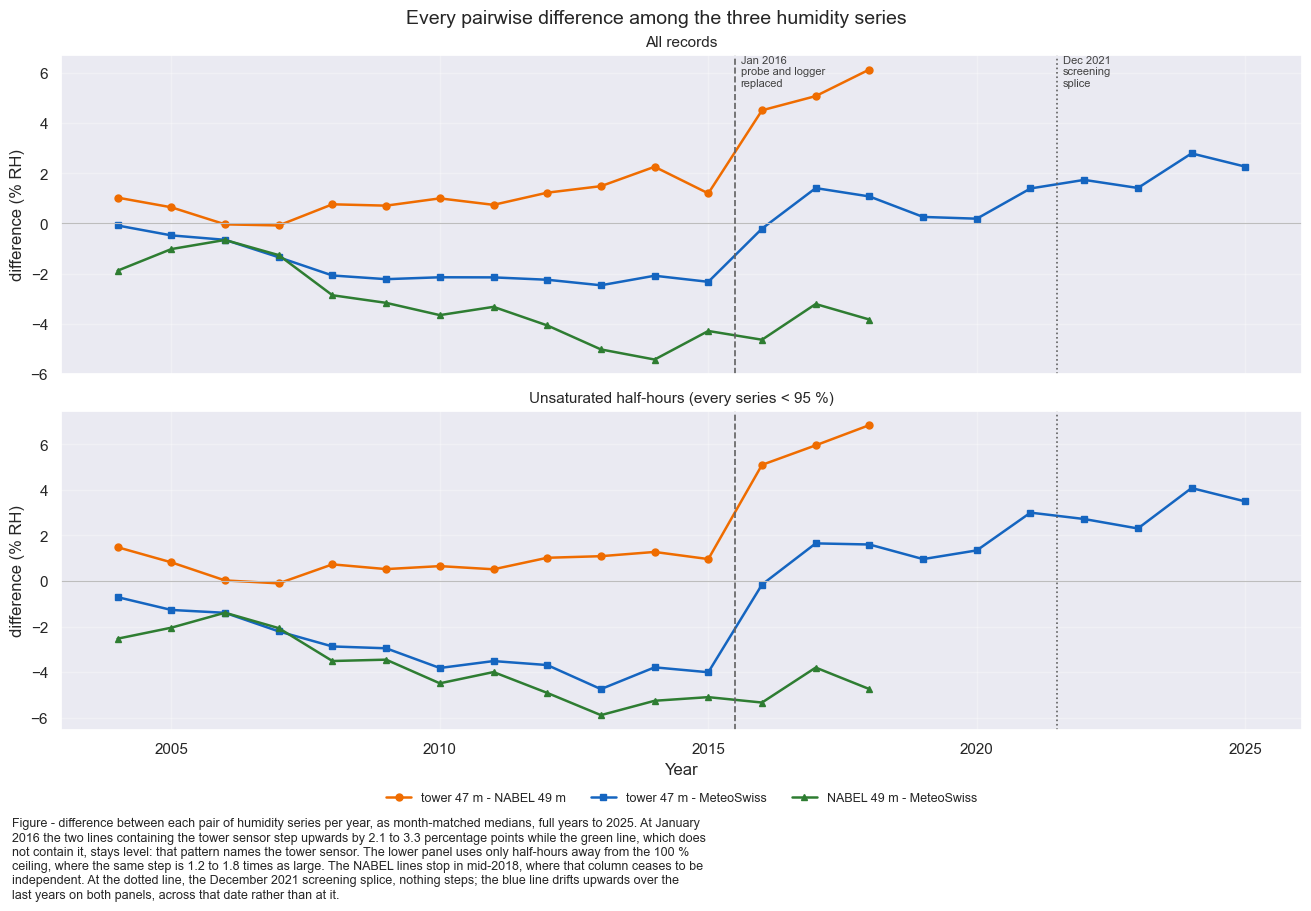

In [41]:
# The three differences drawn together, with the dates of this section marked.
fig, axs = plt.subplots(nrows=2, figsize=(13, 9), dpi=100, layout="constrained", sharex=True)
for _ax, _lvl, _title in [(axs[0], LEVEL, 'All records'),
                          (axs[1], LEVEL_U, f'Unsaturated half-hours (every series < {SATURATED:.0f} %)')]:
    for _l, _colour, _marker in zip(PAIR_LABELS, ['#EF6C00', '#1565C0', '#2E7D32'], 'os^'):
        _ax.plot(_lvl.index, _lvl[_l], color=_colour, lw=1.8, marker=_marker, ms=5, label=_l)
    _ax.axhline(0, color='#BDBDBD', lw=0.8)
    _ax.axvline(BREAK_YEAR - 0.5, color='#616161', lw=1.2, ls='--')
    _ax.axvline(SCREENING_YEAR - 0.5, color='#616161', lw=1.2, ls=':')
    _ax.set_ylabel('difference (% RH)')
    _ax.set_title(_title, fontsize=11)
    _ax.grid(alpha=0.3)
axs[0].text(BREAK_YEAR - 0.4, axs[0].get_ylim()[1], f'Jan {BREAK_YEAR}\nprobe and logger\nreplaced',
            fontsize=8, color='#424242', va='top')
axs[0].text(SCREENING_YEAR - 0.4, axs[0].get_ylim()[1], f'Dec {SCREENING_YEAR - 1}\nscreening\nsplice',
            fontsize=8, color='#424242', va='top')
axs[1].set_xlabel('Year')
axs[1].legend(fontsize=9, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.16), frameon=False)
fig.suptitle('Every pairwise difference among the three humidity series', fontsize=14)
_ratio = (CHANGE_U.loc[BREAK_YEAR, TOWER_PAIRS] / CHANGE.loc[BREAK_YEAR, TOWER_PAIRS])
figcap(fig, f"difference between each pair of humidity series per year, as month-matched medians, "
            f"full years to {LAST_FULL_YEAR}. At January {BREAK_YEAR} the two lines containing the "
            f"tower sensor step upwards by {CHANGE.loc[BREAK_YEAR, TOWER_PAIRS].min():.1f} to "
            f"{CHANGE.loc[BREAK_YEAR, TOWER_PAIRS].max():.1f} percentage points while the green "
            f"line, which does not contain it, stays level: that pattern names the tower sensor. "
            f"The lower panel uses only half-hours away from the 100 % ceiling, where the same "
            f"step is {_ratio.min():.1f} to {_ratio.max():.1f} times as large. The NABEL lines "
            f"stop in mid-2018, where that column ceases to be independent. At the dotted line, the "
            f"December {SCREENING_YEAR - 1} screening splice, nothing steps; the blue line drifts "
            f"upwards over the last years on both panels, across that date rather than at it.")


### 🔟 A transfer across 2016: fitted on the era means it does not hold, fitted at the break it does

For a step that is not one number, the homogenisation is a transfer that varies with the humidity:
per humidity bin, the difference between the eras, added to the earlier era. This step first fits
it against **MeteoSwiss Lägern on the era means** (2005-2015 against 2017 to `CS215_LAST_NORMAL_YEAR`, the last full year before the CS215
changed state, step 1️⃣1️⃣) and
shows that this estimate is not stable, because both eras drift. It then fits the transfer
**against NABEL at the break**, on the three years before it and the CS215 record up to the end of
NABEL's independent period, shows that this estimate depends little on the window, and scores it
against Lägern, which entered no fit. This is the arrangement notebook `02` uses for `TA`.
`RH_T1_47_1_HOMOGENIZED` uses the transfer fitted at the break: it removes the step at the break
and leaves the drift within each era.

Every fit uses **measured records only**, binned on the **reference** humidity; binning on the
tower's reading would produce a slope from regression to the mean.


#### 📋 Table: correction curve per reference humidity bin

In [42]:
HOM_EDGES = np.array([20, 30, 40, 50, 55, 60, 65, 70, 75, 80, 85, 88, 91, 94, 96, 98, 100.0001])
HOM_MID = [(HOM_EDGES[i] + HOM_EDGES[i + 1]) / 2 for i in range(len(HOM_EDGES) - 1)]

# The normal CS215 only: its states of 2024-2025 (step 11) and the HygroVUE10 are left out.
_m = pd.concat([rh_2004_2026[TARGET].rename('tower'), lae.rename('ref')], axis=1).dropna()
_m = _m[_m.index < EXCESS_START]
PRE_YEARS = list(range(2005, BREAK.year))
POST_YEARS = list(range(BREAK.year + 1, CS215_LAST_NORMAL_YEAR + 1))   # full years only
print(f"measured overlapping records: {len(_m):,}   "
      f"pre {PRE_YEARS[0]}-{PRE_YEARS[-1]}, post {POST_YEARS[0]}-{POST_YEARS[-1]}")


def transfer_curve(frame, pre_years, post_years, min_n=1500):
    """The correction a level-dependent homogenisation would apply, per humidity bin.

    Returns each era's mean tower-minus-reference difference and their difference, which is what
    would have to be ADDED to the earlier era to put it on the later era's level. Bins holding
    fewer than `min_n` records in either era are dropped rather than reported as noise.
    """
    def _binned(sel):
        _b = pd.cut(sel['ref'], bins=HOM_EDGES, labels=HOM_MID, include_lowest=True, right=False)
        _g = (sel['tower'] - sel['ref']).groupby(_b, observed=False)
        return _g.mean(), _g.count()

    _mp, _npre = _binned(frame[frame.index.year.isin(pre_years)])
    _mq, _npost = _binned(frame[frame.index.year.isin(post_years)])
    _t = pd.DataFrame({'pre_diff': _mp, 'post_diff': _mq, 'delta': _mq - _mp,
                       'n_pre': _npre, 'n_post': _npost})
    return _t[(_t.n_pre >= min_n) & (_t.n_post >= min_n)]


CURVE = transfer_curve(_m, PRE_YEARS, POST_YEARS)
# The tower's own reading in each bin, which is the axis the transfer would have to be applied on.
CURVE['tower_reading'] = CURVE.index.to_series().astype(float) + CURVE['pre_diff']

tabcap("the correction a level-dependent homogenisation would apply per reference-humidity bin: "
       "each era's mean difference from MeteoSwiss, the correction between them, and the tower "
       "reading it would attach to. It is not monotonic: near zero at both ends of the range, "
       "largest in the middle")
display(CURVE.round(2))

print(f"correction spans {CURVE['delta'].min():+.2f} .. {CURVE['delta'].max():+.2f} pp of RH")
_slope = np.diff(CURVE['delta'].values) / np.diff(CURVE['tower_reading'].values)
print(f"steepest slope d(correction)/d(RH) = {_slope.min():+.3f}; the transfer stays invertible "
      f"while this is > -1: {'yes' if _slope.min() > -1 else 'NO'}")


measured overlapping records: 347,886   pre 2005-2015, post 2017-2023
Table - the correction a level-dependent homogenisation would apply per reference-humidity bin: each
era's mean difference from MeteoSwiss, the correction between them, and the tower reading it would
attach to. It is not monotonic: near zero at both ends of the range, largest in the middle



,pre_diff,post_diff,delta,n_pre,n_post,tower_reading
ref,,,,,,
35.00000,0.70,2.94,2.23,4271,3749,35.70
45.00000,0.29,3.08,2.79,9935,8742,45.29
52.50000,-0.27,3.34,3.61,7361,5838,52.23
57.50000,-0.97,3.02,3.99,9013,6983,56.53
62.50000,-1.79,2.89,4.68,10852,7917,60.71
67.50000,-2.14,3.17,5.31,12582,8047,65.36
72.50000,-2.47,2.98,5.45,13696,8225,70.03
77.50000,-2.85,2.63,5.48,14419,8243,74.65
82.50000,-2.92,2.42,5.34,15082,8346,79.58


correction spans +1.02 .. +5.48 pp of RH
steepest slope d(correction)/d(RH) = -0.514; the transfer stays invertible while this is > -1: yes


#### 📋 Table: correction curve from each half of the eras

In [43]:
# A correction that belongs to the probes gives the same curve from each half of the eras.
_mid_pre, _mid_post = 2011, 2021
_first = transfer_curve(_m, list(range(2005, _mid_pre)),
                        list(range(BREAK.year + 1, _mid_post)), min_n=800)
_second = transfer_curve(_m, list(range(_mid_pre, BREAK.year)),
                         list(range(_mid_post, CS215_LAST_NORMAL_YEAR + 1)), min_n=800)
STAB = pd.DataFrame({f'from the early halves': _first['delta'],
                     f'from the late halves': _second['delta']}).dropna()
STAB['difference'] = STAB.iloc[:, 0] - STAB.iloc[:, 1]

tabcap("the same correction curve estimated from the first half of each era and from the second "
       "half. A correction that belongs to the probes would come out the same both times")
display(STAB.round(2))
print(f"largest disagreement between the two estimates: {STAB['difference'].abs().max():.2f} pp")

# And the same test across the seasons.
_summer = transfer_curve(_m[_m.index.month.isin([5, 6, 7, 8, 9])], PRE_YEARS, POST_YEARS, min_n=600)
_winter = transfer_curve(_m[_m.index.month.isin([11, 12, 1, 2, 3])], PRE_YEARS, POST_YEARS,
                         min_n=600)
SEAS = pd.DataFrame({'summer': _summer['delta'], 'winter': _winter['delta']}).dropna()
print(f"largest summer-minus-winter disagreement:       "
      f"{(SEAS['summer'] - SEAS['winter']).abs().max():.2f} pp")


Table - the same correction curve estimated from the first half of each era and from the second
half. A correction that belongs to the probes would come out the same both times



,from the early halves,from the late halves,difference
ref,,,
35.00000,0.49,4.17,-3.67
45.00000,0.52,5.45,-4.93
52.50000,1.81,5.84,-4.03
57.50000,2.38,6.02,-3.64
62.50000,3.16,6.63,-3.47
67.50000,3.81,7.29,-3.48
72.50000,4.07,7.27,-3.20
77.50000,4.25,7.20,-2.95
82.50000,4.39,6.79,-2.40


largest disagreement between the two estimates: 4.93 pp
largest summer-minus-winter disagreement:       4.72 pp


#### 📋 Table: tower minus MeteoSwiss per year, mid-humidity band

In [44]:
# Why the estimates disagree: both eras are moving. The mid-humidity band is where the step is
# largest and where the 100 % ceiling does not compress it.
# The normal CS215 lasts to the last record before EXCESS_START (_m stops there), so its last year
# is partial. Every year of both eras is restricted to the calendar months that year covers in
# full, January to the month before EXCESS_START, so no year's mean is shifted by the seasonal
# cycle of the difference through months that are missing from it.
DRIFT_MONTHS = list(range(1, EXCESS_START.month))
DRIFT_POST_YEARS = list(range(BREAK.year + 1, EXCESS_START.year + 1))   # the CS215 years, 2016 left out
assert _m.index.max() < EXCESS_START and len(DRIFT_MONTHS) >= 6
_band = _m[(_m['ref'] >= 60) & (_m['ref'] < 80) & _m.index.month.isin(DRIFT_MONTHS)]
_res = (_band['tower'] - _band['ref'])
DRIFT = _res.groupby(_res.index.year).agg(['mean', 'count'])
DRIFT = DRIFT[DRIFT['count'] > 1500]
assert EXCESS_START.year in DRIFT.index, "the last year of the normal CS215 is missing from the drift table"

tabcap(f"tower-minus-MeteoSwiss difference per year over the mid-humidity band, where the step is "
       f"largest, on the months {DRIFT_MONTHS[0]}-{DRIFT_MONTHS[-1]} of every year: the normal CS215 "
       f"runs to {EXCESS_START:%d %B %Y}, and its last year covers these months in full. Each era "
       f"travels rather than holding one level")
display(DRIFT.round(2))

_pre = DRIFT.loc[DRIFT.index.isin(PRE_YEARS), 'mean']
_post = DRIFT.loc[DRIFT.index.isin(DRIFT_POST_YEARS), 'mean']
STEP_PP = float(_post.mean() - _pre.mean())
_tr_pre = float(np.polyfit(_pre.index.values.astype(float), _pre.values, 1)[0])
_tr_post = float(np.polyfit(_post.index.values.astype(float), _post.values, 1)[0])
_span_pre, _span_post = _tr_pre * (len(_pre) - 1), _tr_post * (len(_post) - 1)
DRIFT_TOTAL = abs(_span_pre) + abs(_span_post)
DRIFT_PRE_PER_YR, DRIFT_POST_PER_YR = _tr_pre, _tr_post   # reported, not corrected
_ordinary = float(_pre.diff().abs().median())
_jump = float(DRIFT.loc[BREAK.year + 1, 'mean'] - DRIFT.loc[BREAK.year - 1, 'mean'])

print(f"step between era means:        {STEP_PP:+.2f} pp")
print(f"jump {BREAK.year - 1} -> {BREAK.year + 1}:              {_jump:+.2f} pp   "
      f"(median ordinary year-to-year change within the earlier era: {_ordinary:.2f} pp)")
print(f"drift within the earlier era:  {_tr_pre:+.3f} pp/yr = {_span_pre:+.2f} pp end to end")
print(f"drift within the later era:    {_tr_post:+.3f} pp/yr = {_span_post:+.2f} pp end to end")
print(f"total within-era drift:        {DRIFT_TOTAL:.2f} pp, against a step of {abs(STEP_PP):.2f} pp")

# The step is real (asserted first, so this section is not read as a retraction of step 4).
assert _jump > 5 * _ordinary, (
    "the 2016 jump is no longer large against an ordinary year - has a reference changed?")

# But a transfer fitted on the era means cannot remove it, and these two are the reasons; they
# are why the homogenised column uses a transfer fitted at the break (below).
assert DRIFT_TOTAL > abs(STEP_PP), (
    "the within-era drift no longer exceeds the step; an era-mean transfer may now be stable and "
    "the choice of a transfer fitted at the break should be revisited")
assert STAB['difference'].abs().max() > 0.5 * abs(STEP_PP), (
    "the two half-era estimates of the era-mean transfer now agree; revisit the choice of a "
    "transfer fitted at the break")
print("\nAsserted: the step is real, and the drift within the eras is larger than it. The drift is "
      "not corrected by the homogenised column.")


Table - tower-minus-MeteoSwiss difference per year over the mid-humidity band, where the step is
largest, on the months 1-9 of every year: the normal CS215 runs to 22 October 2024, and its last
year covers these months in full. Each era travels rather than holding one level



,mean,count
TIMESTAMP_MIDDLE,,
2005,-1.29,3958
2006,-1.35,3598
2007,-2.05,4114
2008,-2.82,4528
2009,-2.39,4027
2010,-3.57,3562
2011,-3.72,3763
2012,-3.23,3614
2013,-5.05,2984


step between era means:        +5.46 pp
jump 2015 -> 2017:              +5.59 pp   (median ordinary year-to-year change within the earlier era: 0.64 pp)
drift within the earlier era:  -0.344 pp/yr = -3.44 pp end to end
drift within the later era:    +0.438 pp/yr = +3.07 pp end to end
total within-era drift:        6.51 pp, against a step of 5.46 pp

Asserted: the step is real, and the drift within the eras is larger than it. The drift is not corrected by the homogenised column.


#### 📊 Plot: tower minus MeteoSwiss per year, mid-humidity band

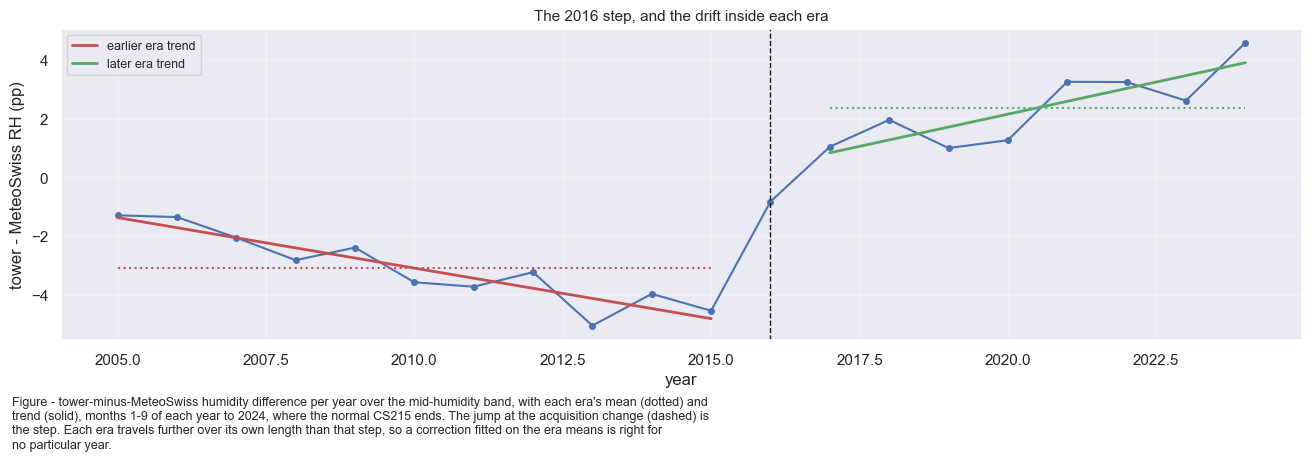

In [45]:
fig, ax = plt.subplots(figsize=(13, 4.5), dpi=100, layout='constrained')
ax.plot(DRIFT.index, DRIFT['mean'], marker='o', ms=4, color='#4C72B0')
for _s, _c, _lab in [(_pre, '#C44E52', 'earlier era'), (_post, '#55A868', 'later era')]:
    _x = _s.index.values.astype(float)
    _fit = np.poly1d(np.polyfit(_x, _s.values, 1))
    ax.plot(_x, _fit(_x), lw=2, color=_c, label=f'{_lab} trend')
    ax.hlines(_s.mean(), _x.min(), _x.max(), color=_c, ls=':', lw=1.5)
ax.axvline(BREAK.year, color='k', ls='--', lw=1)
ax.set_xlabel('year')
ax.set_ylabel('tower - MeteoSwiss RH (pp)')
ax.set_title('The 2016 step, and the drift inside each era', fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=.3)
figcap(fig, f"tower-minus-MeteoSwiss humidity difference per year over the mid-humidity band, "
            f"with each era's mean (dotted) and trend (solid), months {DRIFT_MONTHS[0]}-{DRIFT_MONTHS[-1]} "
            f"of each year to {EXCESS_START.year}, where the normal CS215 ends. The "
            f"jump at the acquisition change (dashed) is the step. Each era travels further over "
            f"its own length than that step, so a correction fitted on the era means is right "
            f"for no particular year.")


#### The transfer at the break, fitted against NABEL

NABEL measures at 49 m on the same tower with its own logger and housing, so it sees the same air
as the 47 m probe; MeteoSwiss Lägern is 2.5 km away. The transfer is fitted on tower minus NABEL
with the binning of `transfer_curve()`: the MP101A over the three full years before the break
(`LOCAL_PRE_YEARS`), the CS215 from the first full month after it (`LOCAL_POST_START`) to the end
of NABEL's independent period (`LOCAL_POST_END`, step 3️⃣). Close to the break the drift has had
little time to act. Each bin's correction is attached to the MP101A's own reading in that bin
(`tower_reading`), interpolated between bins and held constant beyond the outer bins, so it can be
applied to an MP101A value. Near saturation, where both probes sit at the ceiling, the fitted step
is close to zero; the top bin keeps its own small correction, and the result is capped to
`[0, 100]`, so a saturated MP101A record stays at 100 %.

Three checks follow: the transfer must come out the same from shorter windows; applied to the
MP101A era, it must remove the step against **Lägern**, which entered no fit (fit against one
reference, score against another); and the same transfer fitted against Lägern is printed beside
it, because the difference between the two is the reference dependence of this correction.


#### 📋 Table: the 2016 transfer per NABEL humidity bin

In [46]:
# The 2016 transfer, fitted at the break against NABEL (same tower, 49 m, independent until
# NABEL_UNTIL, step 3) and scored against MeteoSwiss Lägern below, as notebook 02 does for TA.
LOCAL_PRE_YEARS = [BREAK.year - 3, BREAK.year - 2, BREAK.year - 1]   # MP101A, 2013-2015
LOCAL_POST_START = pd.Timestamp(f'{BREAK.year}-02-01')   # first full month of the CS215 record
LOCAL_POST_END = NABEL_UNTIL                              # exclusive: NABEL stops being independent
LOCAL_MIN_N = 300   # records per bin and window; lets the shorter windows below fill most bins
assert BREAK < LOCAL_POST_START < LOCAL_POST_END and max(LOCAL_PRE_YEARS) < BREAK.year

# Measured records only: nothing is reconstructed yet.
_nm = pd.concat([rh_2004_2026[TARGET].rename('tower'), NABEL_REF.rename('ref')], axis=1).dropna()
_lm = pd.concat([rh_2004_2026[TARGET].rename('tower'), lae.rename('ref')], axis=1).dropna()


def pre_window(frame, years=None):
    """The MP101A window: full calendar years before the break."""
    return frame[frame.index.year.isin(LOCAL_PRE_YEARS if years is None else years)]


def post_window(frame, start=None, end=None):
    """The CS215 window: from `start` to before `end`."""
    start = LOCAL_POST_START if start is None else start
    end = LOCAL_POST_END if end is None else end
    return frame[(frame.index >= start) & (frame.index < end)]


def binned_transfer(pre: pd.DataFrame, post: pd.DataFrame, min_n: int = None) -> pd.DataFrame:
    """The binning of transfer_curve() on two explicit windows of a (tower, ref) frame.

    Per reference-humidity bin: each window's mean tower - reference difference, their difference
    `delta` (what is added to the earlier era), the record counts, and `tower_reading`, the
    earlier era's own reading in that bin. Bins holding fewer than `min_n` records in either window
    are dropped; raises if none is left.
    """
    min_n = LOCAL_MIN_N if min_n is None else min_n

    def _binned(sel):
        _b = pd.cut(sel['ref'], bins=HOM_EDGES, labels=HOM_MID, include_lowest=True, right=False)
        _g = (sel['tower'] - sel['ref']).groupby(_b, observed=False)
        return _g.mean(), _g.count()

    (_a, _na), (_p, _np) = _binned(pre), _binned(post)
    _t = pd.DataFrame({'pre_diff': _a, 'post_diff': _p, 'delta': _p - _a, 'n_pre': _na, 'n_post': _np})
    _t = _t[(_t.n_pre >= min_n) & (_t.n_post >= min_n)]
    if _t.empty:
        raise ValueError(f"no humidity bin holds {min_n} records in both windows")
    _t['tower_reading'] = _t.index.to_series().astype(float) + _t['pre_diff']
    return _t


try:
    binned_transfer(_nm.iloc[:48], _nm.iloc[-48:])
except ValueError as _exc:
    print(f"OK, binned_transfer raised on a single day per window: {_exc}")
else:
    raise AssertionError("(!) binned_transfer accepted windows of a single day.")

LOCAL_CURVE = binned_transfer(pre_window(_nm), post_window(_nm))

# The ordinary year-to-year change of the same binned difference within each era: consecutive
# calendar years before the break, consecutive year-long blocks after it. It is the noise level of
# a binned correction, used for the near-zero bins here and for the window tolerance below.
_blocks_pre = [pre_window(_nm, [_y]) for _y in LOCAL_PRE_YEARS]
_blocks_post = [post_window(_nm, LOCAL_POST_START + pd.DateOffset(years=_k),
                            LOCAL_POST_START + pd.DateOffset(years=_k + 1)) for _k in range(2)]
_yy = pd.concat([binned_transfer(_x, _y, min_n=1)['delta'] for _x, _y in
                 [(_blocks_pre[0], _blocks_pre[1]), (_blocks_pre[1], _blocks_pre[2]),
                  (_blocks_post[0], _blocks_post[1])]], axis=1, ignore_index=True)
YEAR_TO_YEAR = float(_yy[_yy.index.astype(float) >= 40].abs().stack().median())

# Where both probes sit at the ceiling the step is zero, and the fitted delta may come out a few
# hundredths below it. Such a bin is applied as zero, so the transfer never lowers a reading; a
# negative delta larger than the year-to-year noise would be a real step and fails here.
LOCAL_CURVE['correction'] = LOCAL_CURVE['delta'].clip(lower=0.0)
_neg = LOCAL_CURVE['delta'] < 0
assert (LOCAL_CURVE.loc[_neg, 'delta'].abs() < YEAR_TO_YEAR).all(), (
    "a bin of the 2016 transfer is negative by more than the year-to-year noise: the MP101A would "
    "read wetter than the CS215 there, which this section does not describe")
tabcap(f"the 2016 transfer per NABEL humidity bin: each window's mean difference from NABEL "
       f"(MP101A {LOCAL_PRE_YEARS[0]}-{LOCAL_PRE_YEARS[-1]}, CS215 {LOCAL_POST_START:%b %Y} to "
       f"{(LOCAL_POST_END - pd.Timedelta('1D')):%b %Y}), the fitted delta, the correction applied "
       f"(delta, with {int(_neg.sum())} near-zero negative bin(s) set to zero) and the MP101A reading "
       f"it attaches to")
display(LOCAL_CURVE.round(2))


def mp101a_to_cs215(rh_mp, curve=None):
    """CS215 equivalent of an MP101A reading, from the 2016 transfer of step 10.

    The correction is interpolated on the MP101A reading between the bins and held constant beyond
    the outer bins (np.interp). The result is capped to [0, 100]; NaN stays NaN.
    """
    curve = LOCAL_CURVE if curve is None else curve
    _v = np.asarray(rh_mp, dtype=float)
    _c = curve['correction'] if 'correction' in curve else curve['delta']
    _out = np.clip(_v + np.interp(_v, curve['tower_reading'].values, _c.values), 0.0, 100.0)
    _out = np.where(np.isnan(_v), np.nan, _out)
    if isinstance(rh_mp, pd.Series):
        return pd.Series(_out, index=rh_mp.index, name=rh_mp.name)
    return _out


# What the transfer does, asserted. It is applied on the MP101A reading, so that axis must be
# ordered; it raises every reading in the drier half of the range (below 85 %, the boundary of
# step 5's dry bins), lowers none, keeps the order of the readings, leaves 100 % at 100 % and
# never fills a gap.
_fine = np.linspace(0.0, 100.0, 2001)
_mapped = mp101a_to_cs215(_fine)
assert LOCAL_CURVE['tower_reading'].is_monotonic_increasing, (
    "the MP101A readings of the bins are no longer ordered, so the transfer cannot be applied on them")
assert (LOCAL_CURVE.loc[LOCAL_CURVE.index.astype(float) < 85, 'delta'] > 0).all(), (
    "the MP101A no longer reads drier than the CS215 in every bin below 85 %")
assert (np.diff(_mapped) >= 0).all(), "the transfer maps a wetter MP101A reading to a drier value"
assert (_mapped >= _fine).all() and _mapped.max() <= 100.0, "the transfer lowers a reading or leaves [0, 100]"
assert mp101a_to_cs215(np.array([100.0]))[0] == 100.0, "a saturated MP101A record no longer stays at 100 %"
assert np.isnan(mp101a_to_cs215(np.array([np.nan]))[0]), "the transfer filled a gap"
print(f"correction {LOCAL_CURVE['correction'].min():+.2f} .. {LOCAL_CURVE['correction'].max():+.2f} % RH; "
      f"top bin {LOCAL_CURVE['correction'].iloc[-1]:+.2f} % RH; median one-year change of the binned "
      f"difference {YEAR_TO_YEAR:.2f} % RH")


OK, binned_transfer raised on a single day per window: no humidity bin holds 300 records in both windows
Table - the 2016 transfer per NABEL humidity bin: each window's mean difference from NABEL (MP101A
2013-2015, CS215 Feb 2016 to Jul 2018), the fitted delta, the correction applied (delta, with 1
near-zero negative bin(s) set to zero) and the MP101A reading it attaches to



,pre_diff,post_diff,delta,n_pre,n_post,tower_reading,correction
ref,,,,,,,
25.00000,0.04,3.08,3.04,322,300,25.04,3.04
35.00000,0.20,3.28,3.09,1711,1315,35.20,3.09
45.00000,0.69,3.70,3.01,3676,3223,45.69,3.01
52.50000,0.78,4.17,3.40,2450,2337,53.28,3.40
57.50000,0.52,4.58,4.06,3098,2775,58.02,4.06
62.50000,0.41,4.85,4.45,3321,3028,62.91,4.45
67.50000,0.45,5.66,5.21,3645,3129,67.95,5.21
72.50000,0.70,5.92,5.22,4127,3313,73.20,5.22
77.50000,1.38,6.89,5.51,4164,3405,78.88,5.51


correction +0.00 .. +5.51 % RH; top bin +0.48 % RH; median one-year change of the binned difference 0.32 % RH


#### 📋 Table: window sensitivity of the 2016 transfer

In [47]:
# Window sensitivity against NABEL. A transfer that belongs to the probes comes out the same from
# shorter windows either side of the break.
_y1 = pd.DateOffset(years=1)
LOCAL_WINDOWS = {
    'fitted': (LOCAL_PRE_YEARS, LOCAL_POST_START, LOCAL_POST_END),
    '2 years / 18 months': (LOCAL_PRE_YEARS[-2:], LOCAL_POST_START, LOCAL_POST_START + pd.DateOffset(months=18)),
    '1 year / 1 year': (LOCAL_PRE_YEARS[-1:], LOCAL_POST_START, LOCAL_POST_START + _y1),
}
WINDOW_CURVES = {_k: binned_transfer(pre_window(_nm, _yrs), post_window(_nm, _s, _e))
                 for _k, (_yrs, _s, _e) in LOCAL_WINDOWS.items()}
_deltas = pd.DataFrame({_k: _c['delta'] for _k, _c in WINDOW_CURVES.items()})
_deltas.index.name = 'NABEL RH (%)'
_dev = _deltas.drop(columns='fitted').sub(_deltas['fitted'], axis=0)

# Tolerance, per bin: the ordinary year-to-year change of that bin's difference (median over the
# consecutive-year pairs of rh-hom-local), plus the drift a shorter window skips, its centre lying
# up to a year closer to the break on each side. Per bin, because that noise is several times
# larger where the step falls off towards saturation than in the flat middle of the range; a
# tolerance pooled over the bins sits below the noise there.
_drift_1y = abs(DRIFT_PRE_PER_YR) + abs(DRIFT_POST_PER_YR)
WINDOW_TOL = (_yy.abs().median(axis=1).reindex(_deltas.index) + _drift_1y).rename('tolerance')
_upper = _deltas.index.astype(float) >= 40
tabcap("the 2016 transfer (% RH added to the MP101A) per NABEL humidity bin from each window "
       "choice, each shorter choice's difference from the fitted windows, and the tolerance of "
       "that bin")
display(pd.concat([_deltas, _dev.add_prefix('minus fitted: '), WINDOW_TOL], axis=1).round(2))
print(f"tolerance per bin: that bin's year-to-year change (pooled median {YEAR_TO_YEAR:.2f}) + "
      f"{_drift_1y:.2f} (one year of drift, both eras); from 40 %: "
      f"{WINDOW_TOL[_upper].min():.2f}-{WINDOW_TOL[_upper].max():.2f} % RH")
for _k in _dev.columns:
    _r = (_dev.loc[_upper, _k].abs() / WINDOW_TOL[_upper])
    print(f"  {_k:22s} largest |difference| from 40 %: {_dev.loc[_upper, _k].abs().max():.2f} % RH, "
          f"at most {_r.max():.2f} of its bin's tolerance; below 40 %: "
          + ", ".join(f"{_i:.0f} %: {_v:+.2f}" for _i, _v in _dev.loc[~_upper, _k].dropna().items()))
print(f"  for comparison, the era-mean transfer from the two halves of each era: up to "
      f"{STAB['difference'].abs().max():.2f} % RH")
for _k in _dev.columns:
    assert _dev.loc[_upper, _k].notna().all() and (_dev.loc[_upper, _k].abs() < WINDOW_TOL[_upper]).all(), (
        f"the {_k} curve differs from the fitted one by more than its bin's tolerance in a bin "
        f"from 40 %, so the 2016 transfer depends on the window and must be re-derived")
# Stated in "What step 10 settles": the shorter windows give a smaller correction in the middle of
# the range, a sign that the fitted windows contain some drift.
_middle = _upper & (_deltas.index.astype(float) < 85)
print(f"mean difference of the shorter windows from the fitted one, 40-85 %: "
      + ", ".join(f"{_k} {_dev.loc[_middle, _k].mean():+.2f}" for _k in _dev.columns) + " % RH")
assert (_dev.loc[_middle] < 0).all().all(), (
    "the shorter windows no longer give a smaller correction in every bin from 40 to 85 %; revise "
    "the statement in 'What step 10 settles'")


Table - the 2016 transfer (% RH added to the MP101A) per NABEL humidity bin from each window choice,
each shorter choice's difference from the fitted windows, and the tolerance of that bin



,fitted,2 years / 18 months,1 year / 1 year,minus fitted: 2 years / 18 months,minus fitted: 1 year / 1 year,tolerance
NABEL RH (%),,,,,,
25.00000,3.04,NaN,NaN,NaN,NaN,0.99
35.00000,3.09,2.59,2.42,-0.49,-0.66,0.93
45.00000,3.01,2.37,2.09,-0.64,-0.92,1.24
52.50000,3.40,2.70,2.24,-0.70,-1.15,1.21
57.50000,4.06,3.38,3.18,-0.68,-0.88,1.02
62.50000,4.45,3.89,4.03,-0.55,-0.42,0.95
67.50000,5.21,4.39,4.63,-0.82,-0.58,1.02
72.50000,5.22,4.64,4.85,-0.58,-0.37,1.03
77.50000,5.51,4.85,5.25,-0.65,-0.25,0.91


tolerance per bin: that bin's year-to-year change (pooled median 0.32) + 0.78 (one year of drift, both eras); from 40 %: 0.80-2.81 % RH
  2 years / 18 months    largest |difference| from 40 %: 1.27 % RH, at most 0.80 of its bin's tolerance; below 40 %: 35 %: -0.49
  1 year / 1 year        largest |difference| from 40 %: 1.15 % RH, at most 0.95 of its bin's tolerance; below 40 %: 35 %: -0.66
  for comparison, the era-mean transfer from the two halves of each era: up to 4.93 % RH
mean difference of the shorter windows from the fitted one, 40-85 %: 2 years / 18 months -0.69, 1 year / 1 year -0.61 % RH


#### 📋 Table: step against Lägern before and after the transfer

In [48]:
# Score against MeteoSwiss Lägern, which entered neither the transfer nor its windows: the
# tower-minus-Lägern step across the break, binned on the Lägern humidity, over the windows of the
# fit, before and after the MP101A era is raised. Measured records only.
def step_across(pre: pd.DataFrame, post: pd.DataFrame):
    """Per reference bin the post-minus-pre mean of tower - reference, and its mean over the bins."""
    _s = binned_transfer(pre, post)['delta']
    return _s, float(_s.mean())


_lae_pre, _lae_post = pre_window(_lm), post_window(_lm)
_lae_pre_hom = _lae_pre.assign(tower=mp101a_to_cs215(_lae_pre['tower']))
_lae_before, LAE_STEP_BEFORE = step_across(_lae_pre, _lae_post)
_lae_after, LAE_STEP_AFTER = step_across(_lae_pre_hom, _lae_post)

# Tolerance, two parts. (1) Lägern's own year-to-year scatter of this statistic: the same step
# between consecutive year-long blocks within one era, on the homogenised values. (2) The drift
# the windows contain: against Lägern each era drifts (step 10), and the window centres lie
# away from the break, so a step measured between them holds the drift over those distances.
_hom = lambda d: d.assign(tower=mp101a_to_cs215(d['tower']))
_lb_pre = [_hom(pre_window(_lm, [_y])) for _y in LOCAL_PRE_YEARS]
_lb_post = [post_window(_lm, LOCAL_POST_START + pd.DateOffset(years=_k),
                        LOCAL_POST_START + pd.DateOffset(years=_k + 1)) for _k in range(2)]
_lae_yy = [abs(step_across(_x, _y)[1]) for _x, _y in
           [(_lb_pre[0], _lb_pre[1]), (_lb_pre[1], _lb_pre[2]), (_lb_post[0], _lb_post[1])]]
_yr = pd.Timedelta(days=365.25)
_pre_centre = _lae_pre.index.min() + (_lae_pre.index.max() - _lae_pre.index.min()) / 2
_post_centre = LOCAL_POST_START + (LOCAL_POST_END - LOCAL_POST_START) / 2
LAE_DRIFT_TERM = (abs(DRIFT_PRE_PER_YR) * ((BREAK - _pre_centre) / _yr)
                  + abs(DRIFT_POST_PER_YR) * ((_post_centre - BREAK) / _yr))
LAE_TOL = max(_lae_yy) + LAE_DRIFT_TERM

LAE_SCORE = pd.DataFrame({'step before (% RH)': _lae_before, 'step after (% RH)': _lae_after})
LAE_SCORE.index.name = 'Lägern RH (%)'
tabcap(f"the tower-minus-Lägern step across the break per Lägern humidity bin, "
       f"{LOCAL_PRE_YEARS[0]}-{LOCAL_PRE_YEARS[-1]} against {LOCAL_POST_START:%b %Y} to "
       f"{(LOCAL_POST_END - pd.Timedelta('1D')):%b %Y}, before and after the MP101A era is raised by "
       f"the transfer fitted against NABEL")
display(LAE_SCORE.round(2))
print(f"mean over the bins: before {LAE_STEP_BEFORE:+.2f} % RH, after {LAE_STEP_AFTER:+.2f} % RH")
print(f"tolerance: {max(_lae_yy):.2f} (largest step between consecutive years within one era: "
      + ", ".join(f"{_v:.2f}" for _v in _lae_yy) + f") + {LAE_DRIFT_TERM:.2f} (drift between the "
      f"window centres {_pre_centre:%b %Y} and {_post_centre:%b %Y} and the break) = {LAE_TOL:.2f} % RH")

assert abs(LAE_STEP_AFTER) < LAE_TOL, (
    f"against Lägern the homogenised series still steps by {LAE_STEP_AFTER:+.2f} % RH across the "
    f"break, more than the tolerance of {LAE_TOL:.2f} % RH")
assert abs(LAE_STEP_BEFORE) > 3 * max(_lae_yy), (
    "against Lägern the measured step is no longer large against an ordinary year, so this score "
    "cannot tell a correction from no correction")
assert abs(LAE_STEP_AFTER) < abs(LAE_STEP_BEFORE) / 3, (
    "the transfer no longer removes most of the step against Lägern")

Table - the tower-minus-Lägern step across the break per Lägern humidity bin, 2013-2015 against Feb
2016 to Jul 2018, before and after the MP101A era is raised by the transfer fitted against NABEL



,step before (% RH),step after (% RH)
Lägern RH (%),,
35.00000,1.58,-1.49
45.00000,4.06,0.94
52.50000,4.05,0.76
57.50000,4.31,0.70
62.50000,4.47,0.42
67.50000,4.94,0.48
72.50000,4.93,0.06
77.50000,5.48,0.44
82.50000,5.68,0.78


mean over the bins: before +4.21 % RH, after +0.83 % RH
tolerance: 0.71 (largest step between consecutive years within one era: 0.42, 0.12, 0.71) + 1.10 (drift between the window centres Jul 2014 and May 2017 and the break) = 1.81 % RH


#### 📋 Table: the transfer fitted against NABEL and against Lägern

In [49]:
# The reference dependence: the same transfer fitted against Lägern over the same windows,
# compared on the axis both are applied on, the MP101A reading.
LAE_CURVE = binned_transfer(_lae_pre, _lae_post)
_grid = np.arange(30.0, 100.1, 5.0)
_cmp = pd.DataFrame({'fitted against NABEL': mp101a_to_cs215(_grid) - _grid,
                     'fitted against Lägern': mp101a_to_cs215(_grid, LAE_CURVE) - _grid},
                    index=pd.Index(_grid, name='MP101A reading (%)'))
_cmp['Lägern minus NABEL'] = _cmp.iloc[:, 1] - _cmp.iloc[:, 0]
_mp_meas = pre_window(rh_2004_2026[[TARGET]].dropna().rename(columns={TARGET: 'tower'}))['tower']
LIFT_NABEL = float((mp101a_to_cs215(_mp_meas) - _mp_meas).mean())
LIFT_LAE = float((mp101a_to_cs215(_mp_meas, LAE_CURVE) - _mp_meas).mean())
tabcap("the correction (% RH) the 2016 transfer adds to an MP101A reading when fitted against NABEL "
       "(used) and against Lägern (comparison only), over the same windows")
display(_cmp.round(2))
print(f"mean correction of the measured MP101A records {LOCAL_PRE_YEARS[0]}-{LOCAL_PRE_YEARS[-1]}: "
      f"{LIFT_NABEL:+.2f} % RH fitted against NABEL, {LIFT_LAE:+.2f} % RH against Lägern; the "
      f"difference, {LIFT_LAE - LIFT_NABEL:+.2f} % RH on average and up to "
      f"{_cmp['Lägern minus NABEL'].abs().max():.2f} % RH at one reading, is the reference "
      f"dependence of this correction")


Table - the correction (% RH) the 2016 transfer adds to an MP101A reading when fitted against NABEL
(used) and against Lägern (comparison only), over the same windows



,fitted against NABEL,fitted against Lägern,Lägern minus NABEL
MP101A reading (%),,,
30.0,3.06,1.58,-1.48
35.0,3.08,1.58,-1.51
40.0,3.05,3.03,-0.02
45.0,3.01,4.06,1.04
50.0,3.23,4.05,0.83
55.0,3.64,4.30,0.66
60.0,4.21,4.52,0.31
65.0,4.76,4.94,0.17
70.0,5.21,5.08,-0.14


mean correction of the measured MP101A records 2013-2015: +2.82 % RH fitted against NABEL, +3.36 % RH against Lägern; the difference, +0.54 % RH on average and up to 2.44 % RH at one reading, is the reference dependence of this correction


#### 📊 Plot: the 2016 transfer and its score against Lägern

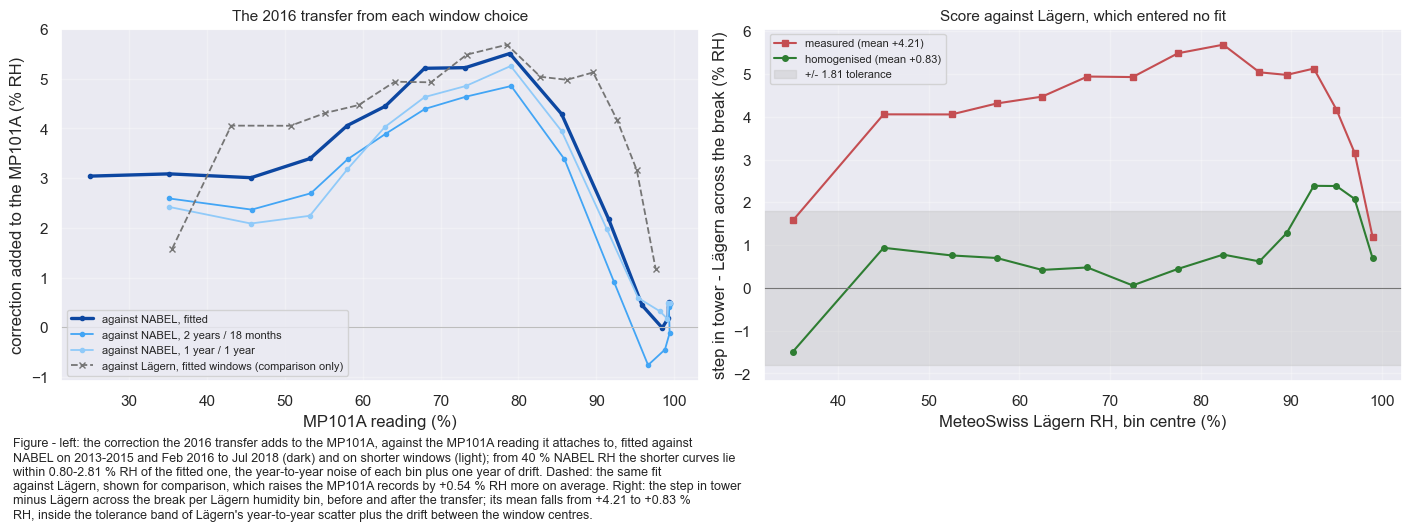

In [50]:
fig, axs = plt.subplots(ncols=2, figsize=(14, 5.2), dpi=100, layout='constrained')
for (_k, _cv), _c in zip(WINDOW_CURVES.items(), ['#0D47A1', '#42A5F5', '#90CAF9']):
    axs[0].plot(_cv['tower_reading'], _cv['delta'], color=_c, marker='o', ms=3,
                lw=2.4 if _k == 'fitted' else 1.3, label=f'against NABEL, {_k}')
axs[0].plot(LAE_CURVE['tower_reading'], LAE_CURVE['delta'], color='#757575', ls='--', lw=1.3,
            marker='x', ms=4, label='against Lägern, fitted windows (comparison only)')
axs[0].axhline(0, color='#BDBDBD', lw=0.8)
axs[0].set_xlabel('MP101A reading (%)')
axs[0].set_ylabel('correction added to the MP101A (% RH)')
axs[0].set_title('The 2016 transfer from each window choice', fontsize=11)
axs[0].legend(fontsize=8, loc='lower left')
_x = LAE_SCORE.index.astype(float)
axs[1].plot(_x, LAE_SCORE['step before (% RH)'], color='#C44E52', marker='s', ms=4,
            label=f'measured (mean {LAE_STEP_BEFORE:+.2f})')
axs[1].plot(_x, LAE_SCORE['step after (% RH)'], color='#2E7D32', marker='o', ms=4,
            label=f'homogenised (mean {LAE_STEP_AFTER:+.2f})')
axs[1].axhspan(-LAE_TOL, LAE_TOL, color='#BDBDBD', alpha=.35, label=f'+/- {LAE_TOL:.2f} tolerance')
axs[1].axhline(0, color='#757575', lw=0.8)
axs[1].set_xlabel('MeteoSwiss Lägern RH, bin centre (%)')
axs[1].set_ylabel('step in tower - Lägern across the break (% RH)')
axs[1].set_title('Score against Lägern, which entered no fit', fontsize=11)
axs[1].legend(fontsize=8)
for _ax in axs:
    _ax.grid(alpha=.3)
figcap(fig, f"left: the correction the 2016 transfer adds to the MP101A, against the MP101A reading "
            f"it attaches to, fitted against NABEL on {LOCAL_PRE_YEARS[0]}-{LOCAL_PRE_YEARS[-1]} "
            f"and {LOCAL_POST_START:%b %Y} to {(LOCAL_POST_END - pd.Timedelta('1D')):%b %Y} (dark) "
            f"and on shorter windows (light); from 40 % NABEL RH the shorter curves lie within "
            f"{WINDOW_TOL[WINDOW_TOL.index.astype(float) >= 40].min():.2f}-"
            f"{WINDOW_TOL[WINDOW_TOL.index.astype(float) >= 40].max():.2f} % RH of the fitted "
            f"one, the year-to-year noise of each bin plus one year of drift. Dashed: the same fit against Lägern, shown "
            f"for comparison, which raises the MP101A records by {LIFT_LAE - LIFT_NABEL:+.2f} % RH "
            f"more on average. Right: the step in tower minus Lägern across the break per Lägern "
            f"humidity bin, before and after the transfer; its mean falls from "
            f"{LAE_STEP_BEFORE:+.2f} to {LAE_STEP_AFTER:+.2f} % RH, inside the tolerance band of "
            f"Lägern's year-to-year scatter plus the drift between the window centres.")


#### What step 🔟 settles

**Fitted on the era means, the transfer is not stable.** Estimates from the first and second
halves of each era differ by up to the size of the correction, and summer and winter by about as
much again. The drift figure shows why: each era travels further over its own length than the step
between them, the two in opposite directions, so a transfer fitted on the era means is correct for
no particular year.

**Fitted at the break against NABEL, it is.** Shorter windows change it by less than the
year-to-year noise of each bin plus a year of drift, and applied to the MP101A era it removes most
of the step against Lägern, which entered no fit, to within Lägern's own year-to-year change plus
the drift the windows contain. `RH_T1_47_1_HOMOGENIZED` raises the MP101A era by this transfer. The
shorter windows give a smaller correction in every bin from 40 to 85 % (asserted), so part of what
the fitted windows attribute to the probes may be drift.

**The correction depends on the reference.** Fitted against Lägern over the same windows, it raises
the MP101A records by several tenths of a percentage point more on average and by up to about two
percentage points more just below saturation, where NABEL finds almost no step and Lägern a large
one (table above). That difference is the uncertainty of the homogenised column across 2016, and
it is largest in humid conditions.

**The drift is not corrected.** It is unattributed, and after mid-2018 no third series exists to
attribute it (NABEL stops, then repeats the tower). Fitting the tower onto MeteoSwiss would replace
the measurement with the reference, which `01` and `03` decline for an unattributed drift. The
homogenised column is therefore free of the step at the break and not homogeneous over decades:
against Lägern the MP101A era drifts by `DRIFT_PRE_PER_YR` and the CS215 era by
`DRIFT_POST_PER_YR` (printed above, in percentage points a year, from January to September of
each year so that the partial year 2024 compares with the others), in opposite directions, and a
trend computed from either column carries that drift.


### 1️⃣1️⃣ The CS215 change of May 2025

Notebook `02` (its step 1️⃣1️⃣) finds two states of the CS215 that depart from its normal
behaviour. From `EXCESS_START` (22 October 2024) the probe heats abnormally in sunlight (source
code `7`). On 16 May 2025 it was handled between 09:32 and 09:42, and from `RESET_START` the daytime
excess is gone (code `6`). The dates are those of `02`, declared again in the settings; the source
flags of the two products are compared in *Sensor era of every record*.

The CS215 reports `RH` relative to its own temperature, so a probe that is too warm in sun reads a
lower `RH` for the same amount of water vapour. Whether the May 2025 change in `RH` is of that kind
or a change of the humidity element is decided here in **vapour pressure** `e`, computed from each
sensor's own `RH` and `TA`: a temperature error moves `RH` and leaves `e` in place. Tower `TA` is
`02`'s measured `TA_T1_47_1_gfXG` (measured records only); Lägern `e` follows from `RH_LAE_MS` and
`TA_LAE_MS`. Saturation vapour pressure over water is the Magnus form that `diive`'s
`calc_vpd_from_ta_rh` uses, so notebook `07`'s VPD rests on the same formula.

The comparison is season-matched: the 30 days before the handling and the 30 days after it in
2025, against the same calendar dates of the normal CS215 summers `HV_CS215_YEARS`.


In [51]:
def es_hpa(ta):
    """Saturation vapour pressure over water (hPa) at air temperature `ta` (degC).

    Magnus form with the coefficients of diive's calc_vpd_from_ta_rh (6.1078 hPa, 17.08085,
    234.175 degC), the formula notebook 07 computes VPD with.
    """
    _t = np.asarray(ta, dtype=float)
    _out = 6.1078 * np.exp(17.08085 * _t / (234.175 + _t))
    return pd.Series(_out, index=ta.index) if isinstance(ta, pd.Series) else _out


assert abs(es_hpa(np.array([0.0]))[0] - 6.1078) < 1e-9 and 23.3 < es_hpa(np.array([20.0]))[0] < 23.5, (
    "the saturation vapour pressure no longer gives its textbook values at 0 and 20 degC")

# Notebook 02's product, read rather than recomputed: same index, the four columns used here.
ta02 = pd.read_parquet(TA_PRODUCT)
_missing = {TA_COL, TA_FLAGCOL, TA_HOMCOL, TA_SRCCOL} - set(ta02.columns)
assert not _missing, f"notebook 02's product lacks {sorted(_missing)}; run 02 before this notebook"
assert ta02.index.equals(rh_2004_2026.index), (
    "notebook 02's product is not on this notebook's TIMESTAMP_MID index; re-run 02 for the same period")
assert ta02[TA_COL].notna().all() and ta02[TA_HOMCOL].notna().all(), "notebook 02's product has gaps"

# Lägern TA, SW_IN and its own vapour pressure, on TIMESTAMP_MID like RH_LAE_MS above.
_ref = pd.read_parquet(REFPATH)[['TA_LAE_MS', 'SW_IN_LAE_MS', 'VP_LAE_MS']]
_ref.index = _ref.index - pd.Timedelta(minutes=15)
_ref = _ref.reindex(rh_2004_2026.index)

# Measured records only: nothing is reconstructed yet, and 02's filled TA is excluded.
VP = pd.DataFrame({'rh': rh_2004_2026[TARGET],
                   'ta': ta02[TA_COL].where(ta02[TA_FLAGCOL] == 0),
                   'rh_ref': lae, 'ta_ref': _ref['TA_LAE_MS'], 'sw_ref': _ref['SW_IN_LAE_MS']})
VP['e'] = VP['rh'] / 100 * es_hpa(VP['ta'])
VP['e_ref'] = VP['rh_ref'] / 100 * es_hpa(VP['ta_ref'])
VP['d_rh'] = VP['rh'] - VP['rh_ref']
VP['d_e'] = VP['e'] - VP['e_ref']
VP['d_ta'] = VP['ta'] - VP['ta_ref']
VP['night'] = NIGHT.reindex(VP.index).fillna(False).astype(bool)   # astronomical, step 6
VP['sun'] = VP['sw_ref'] > 500                                       # W m-2 at Lägern

# The formula and the alignment, checked against the vapour pressure MeteoSwiss reports itself.
_vp_dev = (VP['e_ref'] - _ref['VP_LAE_MS']).dropna()
print(f"Lägern e from RH and TA minus its reported VP: median {_vp_dev.median():+.3f} hPa, "
      f"95th percentile of |difference| {_vp_dev.abs().quantile(0.95):.3f} hPa ({len(_vp_dev):,} records)")
assert abs(_vp_dev.median()) < 0.1 and _vp_dev.abs().quantile(0.95) < 0.2, (
    "the vapour pressure computed for Lägern no longer matches the one MeteoSwiss reports")


Lägern e from RH and TA minus its reported VP: median +0.014 hPa, 95th percentile of |difference| 0.051 hPa (397,036 records)


#### 📋 Table: RH, vapour pressure and temperature against Lägern around 16 May 2025


In [52]:
# The 30 days either side of the handling in 2025, and the same calendar dates of the normal CS215
# summers. Tower minus Lägern, measured records only, in sun (Lägern SW_IN > 500 W m-2) and at night.
_d30 = pd.Timedelta('30D')
MAY25_WINDOWS = {'before': (HANDLING_RECORD - _d30, HANDLING_RECORD),
                 'after': (RESET_START, RESET_START + _d30)}
_rows = []
for _y in HV_CS215_YEARS + [HANDLING_RECORD.year]:
    for _w, (_a, _b) in MAY25_WINDOWS.items():
        _sel = VP.loc[_a.replace(year=_y):_b.replace(year=_y) - pd.Timedelta('30min')].dropna(
            subset=['d_rh', 'd_e', 'd_ta'])
        _code = (7 if _w == 'before' else 6) if _y == HANDLING_RECORD.year else 0
        _row = {'year': _y, 'window': _w, 'code': _code}
        for _k in ('sun', 'night'):
            _m = _sel[_k]
            for _v in ('d_rh', 'd_e', 'd_ta'):
                _row[f'{_v} {_k}'] = _sel.loc[_m, _v].mean()
            _row[f'n {_k}'] = int(_m.sum())
        _rows.append(_row)
MAY25 = pd.DataFrame(_rows).set_index(['year', 'window'])
tabcap(f"tower minus Lägern in the 30 days before the handling of {HANDLING_RECORD:%d %B %Y} and the "
       f"30 days after it, and over the same calendar dates of the normal CS215 summers "
       f"{HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]}: relative humidity d_rh (% RH), vapour pressure "
       f"d_e (hPa) and air temperature d_ta (degC), in sun and at night. Code 7 is the heated CS215, "
       f"code 6 the CS215 after the handling")
display(MAY25.round(2))

# The change across the handling, against the same change between the same dates in normal years.
_chg = MAY25.xs('after', level='window') - MAY25.xs('before', level='window')
_y25 = HANDLING_RECORD.year
_norm = _chg.loc[HV_CS215_YEARS]
MAY25_CHANGE = _chg.loc[_y25]
print(f"change across the handling in sun, {_y25}: d_rh {MAY25_CHANGE['d_rh sun']:+.2f} % RH, "
      f"d_e {MAY25_CHANGE['d_e sun']:+.2f} hPa, d_ta {MAY25_CHANGE['d_ta sun']:+.2f} degC")
print(f"the same change in the normal years: d_rh {_norm['d_rh sun'].min():+.2f} .. "
      f"{_norm['d_rh sun'].max():+.2f} % RH, d_e {_norm['d_e sun'].min():+.2f} .. "
      f"{_norm['d_e sun'].max():+.2f} hPa, d_ta {_norm['d_ta sun'].min():+.2f} .. "
      f"{_norm['d_ta sun'].max():+.2f} degC")
# RH moves out of the range of normal years; e moves by a small fraction of what that RH change
# would mean in vapour pressure: the change is in the probe's temperature, not its humidity element.
_drh = MAY25_CHANGE['d_rh sun'] - _norm['d_rh sun'].mean()
_de = MAY25_CHANGE['d_e sun'] - _norm['d_e sun'].mean()
_ta_sun = float(VP.loc[MAY25_WINDOWS['before'][0]:MAY25_WINDOWS['after'][1]].query('sun')['ta'].mean())
_de_equiv = _drh / 100 * float(es_hpa(np.array([_ta_sun]))[0])
print(f"against the normal years: RH {_drh:+.2f} % RH in sun, which at {_ta_sun:.1f} degC is "
      f"{_de_equiv:+.2f} hPa of vapour pressure; e moved by {_de:+.2f} hPa ({abs(_de / _de_equiv):.0%} of that)")
assert not (_norm['d_rh sun'].min() <= MAY25_CHANGE['d_rh sun'] <= _norm['d_rh sun'].max()), (
    "the RH change in sun across the handling now lies within the range of normal years")
assert abs(_de) < 0.25 * abs(_de_equiv), (
    "the vapour pressure in sun now moves across the handling by a quarter or more of what the RH change "
    "means in vapour pressure, so the change is no longer confined to the probe temperature")

# The probe temperature in sun: code 7 warmer, code 6 cooler than the normal CS215 on the same dates;
# RH follows the other way.
_ta7, _ta6 = MAY25.loc[(_y25, 'before'), 'd_ta sun'], MAY25.loc[(_y25, 'after'), 'd_ta sun']
_norm_before = MAY25.xs('before', level='window').loc[HV_CS215_YEARS]
_norm_after = MAY25.xs('after', level='window').loc[HV_CS215_YEARS]
_sun7, _sun6 = MAY25.loc[(_y25, 'before'), 'd_rh sun'], MAY25.loc[(_y25, 'after'), 'd_rh sun']
print(f"in sun, code 7: TA {_ta7:+.2f} degC, RH {_sun7:+.2f} % RH against Lägern (normal years on the same "
      f"dates: TA {_norm_before['d_ta sun'].min():+.2f} .. {_norm_before['d_ta sun'].max():+.2f}, RH "
      f"{_norm_before['d_rh sun'].min():+.2f} .. {_norm_before['d_rh sun'].max():+.2f})")
print(f"in sun, code 6: TA {_ta6:+.2f} degC, RH {_sun6:+.2f} % RH against Lägern (normal years on the same "
      f"dates: TA {_norm_after['d_ta sun'].min():+.2f} .. {_norm_after['d_ta sun'].max():+.2f}, RH "
      f"{_norm_after['d_rh sun'].min():+.2f} .. {_norm_after['d_rh sun'].max():+.2f})")
assert _ta7 > _norm_before['d_ta sun'].max() and _ta6 < _norm_after['d_ta sun'].min(), (
    "in sun code 7 no longer reads warmer, or code 6 cooler, than every normal CS215 summer on the same dates")
assert _sun6 > _norm_after['d_rh sun'].max(), (
    "in sun code 6 no longer reads a higher RH than every normal CS215 summer on the same dates")


Table - tower minus Lägern in the 30 days before the handling of 16 May 2025 and the 30 days after
it, and over the same calendar dates of the normal CS215 summers 2022-2024: relative humidity d_rh
(% RH), vapour pressure d_e (hPa) and air temperature d_ta (degC), in sun and at night. Code 7 is
the heated CS215, code 6 the CS215 after the handling



code  d_rh sun  d_e sun  d_ta sun  n sun  d_rh night  d_e night  d_ta night  n night
year window                                                                                      
2022 before     0      0.18     1.70      2.80    301        1.81       1.22        1.63      557
     after      0      1.31     2.11      2.32    369        2.62       1.58        1.41      488
2023 before     0      2.87     1.64      1.73    175        2.38       1.13        1.24      558
     after      0     -0.20     2.08      2.86    404        2.41       1.41        1.55      488
2024 before     0      3.37     1.76      1.92    194        4.42       1.18        1.19      555
     after      0      3.12     1.88      1.73    197        4.59       1.55        1.12      487
2025 before     7      0.18     2.00      3.08    260        3.65       1.24        1.25      557
     after      6      4.62     2.12      1.51    314        4.03       1.67        1.36      488

change across the handling in sun, 2025: d_rh +4.43 % RH, d_e +0.13 hPa, d_ta -1.57 degC
the same change in the normal years: d_rh -3.07 .. +1.13 % RH, d_e +0.13 .. +0.45 hPa, d_ta -0.48 .. +1.14 degC
against the normal years: RH +5.17 % RH in sun, which at 17.9 degC is +1.06 hPa of vapour pressure; e moved by -0.20 hPa (19% of that)
in sun, code 7: TA +3.08 degC, RH +0.18 % RH against Lägern (normal years on the same dates: TA +1.73 .. +2.80, RH +0.18 .. +3.37)
in sun, code 6: TA +1.51 degC, RH +4.62 % RH against Lägern (normal years on the same dates: TA +1.73 .. +2.86, RH -0.20 .. +3.12)


#### 📊 Plot: tower minus Lägern in sun, daily, spring 2025


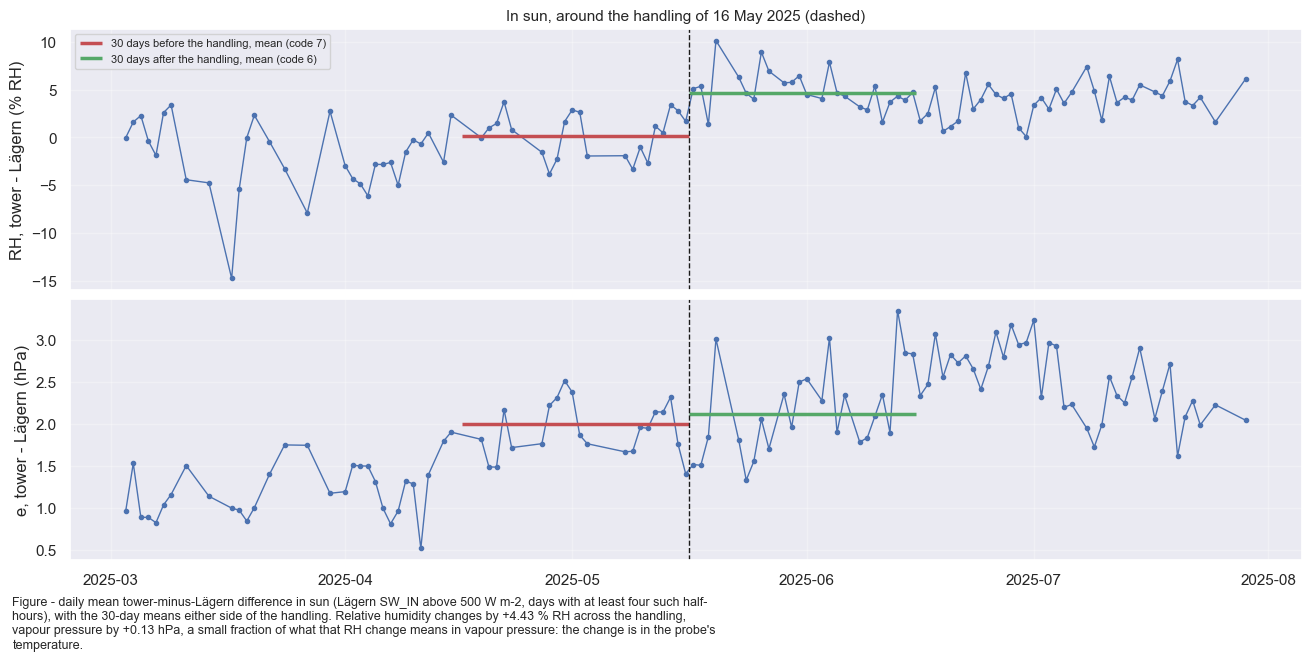

In [53]:
_span = VP.loc[HANDLING_RECORD - pd.Timedelta('75D'):HANDLING_RECORD + pd.Timedelta('75D')]
_sun = _span[_span['sun']]
_per_day = _sun.groupby(_sun.index.normalize())
_daily = _per_day[['d_rh', 'd_e']].mean()[_per_day.size() >= 4]   # days with two hours of sun or more
fig, axs = plt.subplots(nrows=2, figsize=(13, 6.5), dpi=100, layout='constrained', sharex=True)
for _ax, _col, _lab in [(axs[0], 'd_rh', 'RH, tower - Lägern (% RH)'),
                        (axs[1], 'd_e', 'e, tower - Lägern (hPa)')]:
    _ax.plot(_daily.index, _daily[_col], marker='o', ms=3, lw=1, color='#4C72B0')
    for (_w, (_a, _b)), _c in zip(MAY25_WINDOWS.items(), ['#C44E52', '#55A868']):
        _r = MAY25.loc[(HANDLING_RECORD.year, _w)]
        _ax.hlines(_r[f'{_col} sun'], _a, _b, color=_c, lw=2.5,
                   label=f"30 days {_w} the handling, mean (code {int(_r['code'])})")
    _ax.axvline(HANDLING_RECORD, color='k', ls='--', lw=1)
    _ax.set_ylabel(_lab)
    _ax.grid(alpha=.3)
axs[0].legend(fontsize=8)
axs[0].set_title(f'In sun, around the handling of {HANDLING_RECORD:%d %B %Y} (dashed)', fontsize=11)
figcap(fig, f"daily mean tower-minus-Lägern difference in sun (Lägern SW_IN above 500 W m-2, days "
            f"with at least four such half-hours), with the 30-day means either side of the handling. "
            f"Relative humidity changes by {MAY25_CHANGE['d_rh sun']:+.2f} % RH across the handling, "
            f"vapour pressure by {MAY25_CHANGE['d_e sun']:+.2f} hPa, a small fraction of what that RH "
            f"change means in vapour pressure: the change is in the probe's temperature.")


#### What step 1️⃣1️⃣ settles

The change of 16 May 2025 is a change of the probe's temperature and not of its humidity element:
in sun, `RH` against Lägern moves across the handling by more than in any normal year, while the
vapour pressure moves by a small fraction of what that `RH` change would mean (table above). `RH_T1_47_1_HOMOGENIZED` therefore
leaves codes `6` and `7` as measured, as it leaves code `0`. A correction of these records would
be a correction of the probe temperature, which belongs to notebook `02`.

**Limitations.** Both states are probe-heating effects that remain in the exported `RH`. Code `7`
is warmer in sun than the normal CS215 and reports its humidity relative to that temperature, so
it reads low in sun against the summers just before it; code `6` is cooler in sun, because the
daytime excess of the normal CS215 is gone as well, and reads a higher `RH` in sun than every
normal CS215 summer on the same dates. Codes `6` and `7` are excluded from every statistic
meant to describe the normal CS215: the era-mean transfer of step 🔟 (full years to
`CS215_LAST_NORMAL_YEAR`), its drift (January to September of each year, through the last record
before `EXCESS_START`), the screening-splice comparison of step 8️⃣ and the CS215 reference of
step 1️⃣2️⃣. Each state has its own reconstruction offsets.


### 1️⃣2️⃣ The June 2026 probe change

**What changed.** On 5 June 2026 a Campbell HygroVUE10 (SDI-12, SN E6730) replaced the CS215 at
47 m. The fieldbook adds it at this location on that day and records a change of its SDI-12
configuration ID together with a new logger program on 11 June (step 9️⃣); no entry records the
removal of the CS215. The data date the swap to the half-hour: the raw 1-min `TA_T1_47_1` stops at
11:10 and resumes at 11:31, and `TA_T1_47_1` and `RH_T1_47_1` both change level against MeteoSwiss
Lägern from that day. Field name and database tags are unchanged. `HV_START` (11:45,
`TIMESTAMP_MID`) is the first HygroVUE10 record; the swap half-hour before it was removed in the
corrections.

**Why vapour pressure.** Step 1️⃣1️⃣ shows that this probe's `RH` in sun follows its temperature,
and the two probes differ in their radiation behaviour (notebook `02`: the HygroVUE10 reads cooler
in sun). A transfer in %RH would mix the humidity elements with the temperature sensors. The
transfer is therefore made in vapour pressure `e`, which a temperature error leaves in place, and
converted back to `RH` with `02`'s homogenised temperature.

**Method.**

1. `e` from each sensor's own `RH` and `TA`, as in step 1️⃣1️⃣: tower `RH_T1_47_1` with `02`'s
   measured `TA_T1_47_1_gfXG`, Lägern `RH_LAE_MS` with `TA_LAE_MS`.
2. Two samples, matched on calendar dates (12 June to 30 September): the HygroVUE10 from
   `HV_FIT_START` to `PERIOD_END`, after the configuration change, so 5-11 June are excluded as
   transitional; and the normal CS215 (code `0`) over the same dates of `HV_CS215_YEARS`, the
   summers before its excess heating, as in `02`. Measured records only, everything present.
3. The difference `d_e = e_47 - e_LAE` is binned on `e_LAE` and split by day and night. If the
   HygroVUE10-minus-CS215 difference varies across the bins by more than the CS215 year-to-year
   scatter, each sample is fitted as `d_e = a + b * e_LAE` and the difference of the two lines is
   applied through the `e_LAE` a HygroVUE10 value corresponds to, held inside the fitted range;
   otherwise it is a constant. The decision is computed below.
4. `RH_HOM = 100 * (e_47 - Delta_e) / es(TA_HOM)`, where `Delta_e` is the HygroVUE10-minus-CS215
   difference and `TA_HOM` is `02`'s homogenised temperature of the same record, capped to
   `[0, 100]`.

**What the homogenised RH refers to.** From June 2026 it is relative to `02`'s homogenised air
temperature, not to a CS215's own temperature. `02` removes the CS215 shield's radiative excess, so
in sun the homogenised `RH` lies above what the CS215 would have read; at night the two agree. The
amount is computed below.

**Limitations.** The transfer rests on one summer and on one reference: NABEL ended in 2018, so
Lägern is the only series to fit against, and a month hold-out takes the place of a second one. It
is fitted on June to September and applied as fitted to the whole HygroVUE10 era, including the
transitional week. Its month hold-out residuals follow the season, negative in June and July,
near zero in August and positive in September (table below): within the summer the transfer
leaves the early months slightly too dry and the late ones slightly too wet, and its behaviour
outside the summer is untested. The hold-out tolerance is pooled over the months, because three
CS215 summers cannot estimate one month's scatter reliably. It depends on `02`: the measured `TA` enters `e`, the homogenised `TA` the
conversion back, so `02` runs before this notebook.


#### 📋 Table: vapour pressure against Lägern per summer


In [54]:
# The two fitting samples in vapour pressure, matched on calendar dates. Measured records only
# (VP of step 11): nothing is reconstructed yet, and the probe half-hours were removed.
_season = (HV_FIT_START.strftime('%m-%d'), pd.Timestamp(PERIOD_END).strftime('%m-%d'))
_md = VP.index.strftime('%m-%d')
_in_season = (_md >= _season[0]) & (_md <= _season[1])
_ok = VP[['e', 'e_ref']].notna().all(axis=1)
_code0 = (VP.index >= BREAK) & (VP.index < EXCESS_START)   # the normal CS215
HV_SAMPLE = VP[_in_season & _ok & (VP.index >= HV_FIT_START)]
CS_SAMPLE = VP[_in_season & _ok & _code0 & VP.index.year.isin(HV_CS215_YEARS)]
print(f"HygroVUE10 sample: {len(HV_SAMPLE):,} records, "
      f"{HV_SAMPLE.index.min():%d %b %Y} -> {HV_SAMPLE.index.max():%d %b %Y}")
print(f"CS215 sample:      {len(CS_SAMPLE):,} records, {_season[0]} to {_season[1]} of "
      f"{HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]} (code 0)")
assert HV_SAMPLE.index.min() >= HV_FIT_START > HV_START, "the HygroVUE10 sample reaches before its fit start"
assert BREAK <= CS_SAMPLE.index.min() and CS_SAMPLE.index.max() < EXCESS_START, (
    "the CS215 sample now reaches outside the normal CS215 (code 0)")
assert sorted(CS_SAMPLE.index.year.unique()) == HV_CS215_YEARS, "a CS215 sample year is missing"


def _summer(s):
    return pd.Series({'d_e all (hPa)': s['d_e'].mean(), 'd_e day (hPa)': s.loc[~s['night'], 'd_e'].mean(),
                      'd_e night (hPa)': s.loc[s['night'], 'd_e'].mean(),
                      'd_rh all (% RH)': s['d_rh'].mean(), 'd_ta day (degC)': s.loc[~s['night'], 'd_ta'].mean(),
                      'records': len(s)})


HV_LEVELS = pd.DataFrame({**{f'{_y} (CS215)': _summer(CS_SAMPLE[CS_SAMPLE.index.year == _y])
                             for _y in HV_CS215_YEARS},
                          f'{HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]} (CS215)': _summer(CS_SAMPLE),
                          f'{HV_START.year} (HygroVUE10)': _summer(HV_SAMPLE)}).T
HV_LEVELS['records'] = HV_LEVELS['records'].astype(int)
tabcap(f"tower minus MeteoSwiss Lägern, {_season[0]} to {_season[1]} of each summer, measured records "
       f"only: vapour pressure d_e over all hours, by day and at night, relative humidity d_rh and "
       f"daytime temperature d_ta. The HygroVUE10 row lies below every CS215 row in vapour pressure")
display(HV_LEVELS.round(3))

# The tolerance of every e-space comparison: the CS215 year-to-year scatter of the season mean,
# as the largest deviation of one summer from the mean of the others (leave-one-year-out).
_ym = CS_SAMPLE['d_e'].groupby(CS_SAMPLE.index.year).mean()
E_TOL = float(max(abs(_ym[_y] - _ym.drop(_y).mean()) for _y in _ym.index))
HV_STEP_E = float(HV_SAMPLE['d_e'].mean() - CS_SAMPLE['d_e'].mean())
print(f"HygroVUE10 minus CS215 in vapour pressure: {HV_STEP_E:+.3f} hPa; CS215 year-to-year scatter "
      f"(leave one summer out): {E_TOL:.3f} hPa")
assert float(HV_LEVELS.iloc[-1]['d_e all (hPa)']) < _ym.min(), (
    "the HygroVUE10 summer no longer lies below every CS215 summer in vapour pressure")
assert abs(HV_STEP_E) > 3 * E_TOL, (
    "the HygroVUE10 difference in vapour pressure is no longer large against the CS215 year-to-year "
    "scatter, so the change this step corrects may be within the CS215's own variation")


HygroVUE10 sample: 5,328 records, 12 Jun 2026 -> 30 Sep 2026
CS215 sample:      15,885 records, 06-12 to 09-30 of 2022-2024 (code 0)
Table - tower minus MeteoSwiss Lägern, 06-12 to 09-30 of each summer, measured records only: vapour
pressure d_e over all hours, by day and at night, relative humidity d_rh and daytime temperature
d_ta. The HygroVUE10 row lies below every CS215 row in vapour pressure



,d_e all (hPa),d_e day (hPa),d_e night (hPa),d_rh all (% RH),d_ta day (degC),records
2022 (CS215),1.847,1.981,1.635,1.489,2.032,5328
2023 (CS215),1.944,2.039,1.792,2.459,1.754,5320
2024 (CS215),2.090,2.229,1.872,3.205,1.760,5237
2022-2024 (CS215),1.959,2.082,1.766,2.379,1.849,15885
2026 (HygroVUE10),0.689,0.712,0.653,-0.874,1.142,5328


HygroVUE10 minus CS215 in vapour pressure: -1.270 hPa; CS215 year-to-year scatter (leave one summer out): 0.195 hPa


#### 📋 Table: HygroVUE10 minus CS215 by vapour pressure, day and night


In [55]:
# The shape of the difference: binned on the Lägern vapour pressure, over all hours, by day and at
# night. It decides between a constant and a linear transfer.
def binned_e(sample: pd.DataFrame, col: str = 'd_e'):
    """Mean of `col` and record count per Lägern vapour pressure bin (HV_E_BINS)."""
    _g = sample[col].groupby(pd.cut(sample['e_ref'], HV_E_BINS, right=False), observed=False)
    return _g.mean(), _g.count()


_cols = {}
for _lab, _sel_hv, _sel_cs in [('all', None, None), ('day', ~HV_SAMPLE['night'], ~CS_SAMPLE['night']),
                               ('night', HV_SAMPLE['night'], CS_SAMPLE['night'])]:
    _h = HV_SAMPLE if _sel_hv is None else HV_SAMPLE[_sel_hv]
    _c = CS_SAMPLE if _sel_cs is None else CS_SAMPLE[_sel_cs]
    (_mh, _nh), (_mc, _nc) = binned_e(_h), binned_e(_c)
    _ok_bins = (_nh >= HV_MIN_BIN_RECORDS / (1 if _lab == 'all' else 2)) & \
               (_nc >= HV_MIN_BIN_RECORDS / (1 if _lab == 'all' else 2))
    _cols[f'HygroVUE10 - CS215, {_lab} (hPa)'] = (_mh - _mc).where(_ok_bins)
    if _lab == 'all':
        _cols['records HygroVUE10'], _cols['records CS215'] = _nh, _nc
HV_SHAPE = pd.DataFrame(_cols)
HV_SHAPE.index.name = 'Lägern e (hPa)'
tabcap(f"the HygroVUE10-minus-CS215 difference in vapour pressure per Lägern vapour pressure bin, "
       f"over all hours, by day and at night (bins with at least {HV_MIN_BIN_RECORDS} records in "
       f"both samples, half that for day and night)")
display(HV_SHAPE.round(3))

_all = HV_SHAPE['HygroVUE10 - CS215, all (hPa)'].dropna()
_dn = (HV_SAMPLE.loc[HV_SAMPLE['night'], 'd_e'].mean() - CS_SAMPLE.loc[CS_SAMPLE['night'], 'd_e'].mean()) - \
      (HV_SAMPLE.loc[~HV_SAMPLE['night'], 'd_e'].mean() - CS_SAMPLE.loc[~CS_SAMPLE['night'], 'd_e'].mean())
HV_E_SPREAD = float(_all.max() - _all.min())
HV_E_LINEAR = HV_E_SPREAD > E_TOL
print(f"spread of the difference across {len(_all)} vapour pressure bins: {HV_E_SPREAD:.3f} hPa; "
      f"night minus day: {_dn:+.3f} hPa; CS215 year-to-year scatter: {E_TOL:.3f} hPa")
print(f"-> the transfer is {'linear in e' if HV_E_LINEAR else 'a constant'}: the difference "
      f"{'varies' if HV_E_LINEAR else 'does not vary'} across the vapour pressure bins by more than "
      f"the CS215 scatter")


Table - the HygroVUE10-minus-CS215 difference in vapour pressure per Lägern vapour pressure bin,
over all hours, by day and at night (bins with at least 200 records in both samples, half that for
day and night)



,"HygroVUE10 - CS215, all (hPa)",records HygroVUE10,records CS215,"HygroVUE10 - CS215, day (hPa)","HygroVUE10 - CS215, night (hPa)"
Lägern e (hPa),,,,,
"[4.0, 6.0)",NaN,29,5,NaN,NaN
"[6.0, 8.0)",-0.903,227,455,-1.195,-0.570
"[8.0, 10.0)",-0.880,884,1554,-0.981,-0.779
"[10.0, 12.0)",-1.118,1068,2939,-1.191,-0.998
"[12.0, 14.0)",-1.237,1391,3566,-1.319,-1.114
"[14.0, 16.0)",-1.371,1046,3715,-1.442,-1.271
"[16.0, 18.0)",-1.441,534,2655,-1.562,-1.213
"[18.0, 20.0)",NaN,146,855,-1.692,NaN
"[20.0, 22.0)",NaN,3,125,NaN,NaN


spread of the difference across 6 vapour pressure bins: 0.561 hPa; night minus day: +0.258 hPa; CS215 year-to-year scatter: 0.195 hPa
-> the transfer is linear in e: the difference varies across the vapour pressure bins by more than the CS215 scatter


#### 📋 Table: the fitted vapour pressure transfer


In [56]:
def fit_e_line(sample: pd.DataFrame, label: str, linear: bool = None, min_records: int = None) -> dict:
    """Fit `d_e = a + b * e_LAE` (linear) or `d_e = a` (constant) on one sample.

    Raises when the sample holds fewer than `min_records` records or spans less than 5 hPa of
    Lägern vapour pressure: a fit on a few days describes those days' weather, not the probe.
    """
    linear = HV_E_LINEAR if linear is None else linear
    min_records = HV_MIN_RECORDS if min_records is None else min_records
    _s = sample[['e_ref', 'd_e']].dropna()
    if len(_s) < min_records:
        raise ValueError(f"{label}: {len(_s)} records, fewer than the {min_records} a transfer is fitted on")
    _span = float(_s['e_ref'].max() - _s['e_ref'].min())
    if _span < 5:
        raise ValueError(f"{label}: the records span only {_span:.1f} hPa of Lägern vapour pressure")
    if linear:
        _b, _a = np.polyfit(_s['e_ref'].values, _s['d_e'].values, 1)
    else:
        _a, _b = float(_s['d_e'].mean()), 0.0
    return {'a': float(_a), 'b': float(_b), 'lowest Lägern e (hPa)': float(_s['e_ref'].min()),
            'highest Lägern e (hPa)': float(_s['e_ref'].max()), 'records': len(_s)}


def hv_e_to_cs215(e_hv, fit_cs: dict, fit_hv: dict):
    """CS215 equivalent of a HygroVUE10 vapour pressure: `e_hv - Delta_e`.

    The value is mapped to the Lägern vapour pressure it corresponds to, held inside the range both
    fits cover, and corrected by the difference of the two fitted lines there. NaN stays NaN.
    """
    _v = np.asarray(e_hv, dtype=float)
    _x = (_v - fit_hv['a']) / (1 + fit_hv['b'])
    _x = np.clip(_x, max(fit_cs['lowest Lägern e (hPa)'], fit_hv['lowest Lägern e (hPa)']),
                 min(fit_cs['highest Lägern e (hPa)'], fit_hv['highest Lägern e (hPa)']))
    _out = _v + (fit_cs['a'] - fit_hv['a']) + (fit_cs['b'] - fit_hv['b']) * _x
    return pd.Series(_out, index=e_hv.index, name=e_hv.name) if isinstance(e_hv, pd.Series) else _out


def hv_to_cs215_rh(rh_hv, ta_measured, ta_homogenized, fit_cs: dict = None, fit_hv: dict = None):
    """Homogenised RH of a HygroVUE10 record: its vapour pressure (own RH and TA) on the CS215 level,
    relative to notebook 02's homogenised TA of the same record, capped to [0, 100]."""
    fit_cs = FIT_CS215 if fit_cs is None else fit_cs
    fit_hv = FIT_HV if fit_hv is None else fit_hv
    _e = np.asarray(rh_hv, dtype=float) / 100 * es_hpa(np.asarray(ta_measured, dtype=float))
    _out = np.clip(100 * hv_e_to_cs215(_e, fit_cs, fit_hv) / es_hpa(np.asarray(ta_homogenized, dtype=float)),
                   0.0, 100.0)
    return pd.Series(_out, index=rh_hv.index, name=rh_hv.name) if isinstance(rh_hv, pd.Series) else _out


# Negative control: one day of records is refused.
_one_day = HV_SAMPLE[HV_SAMPLE.index.normalize() == HV_SAMPLE.index[0].normalize()]
try:
    fit_e_line(_one_day, 'a single day')
except ValueError as _exc:
    print(f"OK, fit_e_line raised on a single day: {_exc}")
else:
    raise AssertionError("(!) fit_e_line accepted a single day of records.")

FIT_CS215 = fit_e_line(CS_SAMPLE, 'CS215 sample')
FIT_HV = fit_e_line(HV_SAMPLE, 'HygroVUE10 sample')
tabcap(f"the fitted {'lines' if HV_E_LINEAR else 'constants'} d_e = a + b * e_LAE (hPa) of the two "
       f"samples, and the range of Lägern vapour pressure each covers")
display(pd.DataFrame({f'CS215 {HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]}': FIT_CS215,
                      f'HygroVUE10 {HV_START.year}': FIT_HV}).T.astype({'records': int}).round(4))

_grid = np.array([8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0])
HV_DELTA_E = pd.Series((FIT_HV['a'] - FIT_CS215['a']) + (FIT_HV['b'] - FIT_CS215['b']) * _grid,
                       index=pd.Index(_grid, name='Lägern e (hPa)'), name='Delta_e (hPa)')
print("Delta_e, HygroVUE10 minus CS215, at the Lägern vapour pressure it applies to: "
      + ", ".join(f"{_k:.0f} hPa: {_v:+.2f}" for _k, _v in HV_DELTA_E.items())
      + f" (uncertainty: CS215 year-to-year scatter {E_TOL:.2f} hPa)")
assert (HV_DELTA_E < 0).all(), "the HygroVUE10 no longer reads drier than the CS215 across the fitted range"
assert np.isnan(hv_e_to_cs215(np.array([np.nan]), FIT_CS215, FIT_HV)[0]), "the transfer filled a gap"


OK, fit_e_line raised on a single day: a single day: 48 records, fewer than the 1500 a transfer is fitted on
Table - the fitted lines d_e = a + b * e_LAE (hPa) of the two samples, and the range of Lägern
vapour pressure each covers



,a,b,lowest Lägern e (hPa),highest Lägern e (hPa),records
CS215 2022-2024,0.8762,0.0797,5.6009,22.6708,15885
HygroVUE10 2026,0.4809,0.0165,4.7185,20.4936,5328


Delta_e, HygroVUE10 minus CS215, at the Lägern vapour pressure it applies to: 8 hPa: -0.90, 10 hPa: -1.03, 12 hPa: -1.15, 14 hPa: -1.28, 16 hPa: -1.41, 18 hPa: -1.53, 20 hPa: -1.66 (uncertainty: CS215 year-to-year scatter 0.19 hPa)


#### 📋 Table: HygroVUE10 minus CS215 in vapour pressure, before and after the transfer


In [57]:
# The HygroVUE10 sample on the CS215 level in vapour pressure, against the CS215 sample: over all
# hours (asserted), and per vapour pressure bin, by day and at night (information). This is the
# fitting sample; the month hold-out below is the test.
HV_SAMPLE_CS = HV_SAMPLE.assign(e=hv_e_to_cs215(HV_SAMPLE['e'], FIT_CS215, FIT_HV))
HV_SAMPLE_CS['d_e'] = HV_SAMPLE_CS['e'] - HV_SAMPLE_CS['e_ref']
_before, _ = binned_e(HV_SAMPLE)
_after, _n = binned_e(HV_SAMPLE_CS)
_cs, _nc = binned_e(CS_SAMPLE)
_ok_bins = (_n >= HV_MIN_BIN_RECORDS) & (_nc >= HV_MIN_BIN_RECORDS)
HV_SCORE_E = pd.DataFrame({'before (hPa)': (_before - _cs).where(_ok_bins),
                           'after (hPa)': (_after - _cs).where(_ok_bins)})
HV_SCORE_E.index.name = 'Lägern e (hPa)'
_cs_mean = CS_SAMPLE['d_e'].mean()
HV_E_BEFORE = float(HV_SAMPLE['d_e'].mean() - _cs_mean)
HV_E_AFTER = float(HV_SAMPLE_CS['d_e'].mean() - _cs_mean)
_dn_after = {_k: float(HV_SAMPLE_CS.loc[_m, 'd_e'].mean() - CS_SAMPLE.loc[_mc, 'd_e'].mean())
             for _k, _m, _mc in [('day', ~HV_SAMPLE_CS['night'], ~CS_SAMPLE['night']),
                                 ('night', HV_SAMPLE_CS['night'], CS_SAMPLE['night'])]}
tabcap("HygroVUE10 minus CS215 in vapour pressure per Lägern vapour pressure bin, before and after "
       "the transfer, season-matched, measured records only")
display(HV_SCORE_E.round(3))
print(f"over all hours: before {HV_E_BEFORE:+.3f} hPa, after {HV_E_AFTER:+.3f} hPa "
      f"(tolerance {E_TOL:.3f} hPa); after, by day {_dn_after['day']:+.3f}, at night "
      f"{_dn_after['night']:+.3f} hPa; largest |after| in a bin "
      f"{HV_SCORE_E['after (hPa)'].abs().max():.3f} hPa")
assert abs(HV_E_AFTER) < E_TOL, (
    f"after the transfer the HygroVUE10 still differs from the CS215 by {HV_E_AFTER:+.3f} hPa, more "
    f"than the CS215 year-to-year scatter ({E_TOL:.3f} hPa)")


Table - HygroVUE10 minus CS215 in vapour pressure per Lägern vapour pressure bin, before and after
the transfer, season-matched, measured records only



,before (hPa),after (hPa)
Lägern e (hPa),,
"[4.0, 6.0)",NaN,NaN
"[6.0, 8.0)",-0.903,-0.045
"[8.0, 10.0)",-0.880,0.093
"[10.0, 12.0)",-1.118,-0.028
"[12.0, 14.0)",-1.237,-0.018
"[14.0, 16.0)",-1.371,-0.034
"[16.0, 18.0)",-1.441,0.020
"[18.0, 20.0)",NaN,NaN
"[20.0, 22.0)",NaN,NaN


over all hours: before -1.270 hPa, after -0.079 hPa (tolerance 0.195 hPa); after, by day -0.167, at night +0.060 hPa; largest |after| in a bin 0.093 hPa


#### 📋 Table: month hold-out in vapour pressure


In [58]:
# Month hold-out in vapour pressure. Lägern is the only reference, so each month of the HygroVUE10
# sample is left out in turn, both fits are redone without it (the CS215 sample leaves the same
# calendar month out), and the held-out month is predicted. The statistic is the month's mean
# d_e, HygroVUE10 on the CS215 level minus the CS215 sample of the same calendar month. Its
# scatter among the CS215 summers (leave one summer out) is printed per month, but three summers
# cannot estimate one month's scatter reliably, so the tolerance is pooled: the largest of the
# four monthly scatters, applied to every month.
_rows = []
for _mo in sorted(HV_SAMPLE.index.month.unique()):
    _fc = fit_e_line(CS_SAMPLE[CS_SAMPLE.index.month != _mo], f'CS215 without month {_mo}')
    _fh = fit_e_line(HV_SAMPLE[HV_SAMPLE.index.month != _mo], f'HygroVUE10 without month {_mo}')
    _ho = HV_SAMPLE[HV_SAMPLE.index.month == _mo]
    _cs_m = CS_SAMPLE.loc[CS_SAMPLE.index.month == _mo, 'd_e']
    _ym = _cs_m.groupby(_cs_m.index.year).mean()
    _rows.append({
        'month': _mo, 'held-out records': len(_ho),
        'as measured (hPa)': float(_ho['d_e'].mean() - _cs_m.mean()),
        'held out, on CS215 level (hPa)':
            float((hv_e_to_cs215(_ho['e'], _fc, _fh) - _ho['e_ref']).mean() - _cs_m.mean()),
        'CS215 year scatter of the month (hPa)':
            max(abs(_ym[_y] - _ym.drop(_y).mean()) for _y in _ym.index),
    })
HV_HOLDOUT = pd.DataFrame(_rows).set_index('month')
_ho_col, _sc_col = 'held out, on CS215 level (hPa)', 'CS215 year scatter of the month (hPa)'
HV_HOLDOUT_TOL = float(HV_HOLDOUT[_sc_col].max())
tabcap(f"month hold-out of the vapour pressure transfer: each month of the HygroVUE10 summer "
       f"predicted by fits without it, as its difference from the CS215 sample of the same calendar "
       f"month, beside the leave-one-summer-out scatter of the CS215 summers in that month. The "
       f"tolerance is the largest of these, {HV_HOLDOUT_TOL:.3f} hPa, for every month")
display(HV_HOLDOUT.round(3))

assert len(HV_HOLDOUT) >= 3, "the HygroVUE10 sample covers too few months for a hold-out"
assert (HV_HOLDOUT[_ho_col].abs() < HV_HOLDOUT_TOL).all(), (
    "a held-out month lies further from the CS215 level than the largest monthly CS215 scatter")
assert (HV_HOLDOUT[_ho_col].abs() < HV_HOLDOUT['as measured (hPa)'].abs()).all(), (
    "the transfer, fitted without a month, no longer brings that month closer to the CS215 level")
print(f"Every held-out month lies within the pooled tolerance of {HV_HOLDOUT_TOL:.3f} hPa (largest "
      f"|residual| {HV_HOLDOUT[_ho_col].abs().max():.3f} hPa). Residual by month: "
      + ", ".join(f"{pd.Timestamp(2000, _mo, 1):%B} {_v:+.2f}" for _mo, _v in HV_HOLDOUT[_ho_col].items())
      + " hPa.")


Table - month hold-out of the vapour pressure transfer: each month of the HygroVUE10 summer
predicted by fits without it, as its difference from the CS215 sample of the same calendar month,
beside the leave-one-summer-out scatter of the CS215 summers in that month. The tolerance is the
largest of these, 0.368 hPa, for every month



,held-out records,as measured (hPa),"held out, on CS215 level (hPa)",CS215 year scatter of the month (hPa)
month,,,,
6,912,-1.393,-0.169,0.121
7,1488,-1.414,-0.319,0.245
8,1488,-1.300,-0.006,0.368
9,1440,-1.016,0.191,0.251


Every held-out month lies within the pooled tolerance of 0.368 hPa (largest |residual| 0.319 hPa). Residual by month: June -0.17, July -0.32, August -0.01, September +0.19 hPa.


#### 📋 Table: homogenised HygroVUE10 RH against the CS215, by RH bin


In [59]:
# Information, not a guard: the homogenised RH of the HygroVUE10 sample against the CS215 sample in
# %RH, by Lägern RH bin and by sun and night. The CS215 RH is relative to its own probe temperature,
# which runs warm in sun; the homogenised RH is relative to 02's homogenised temperature, which does
# not. In sun the two are therefore expected to differ, at night not.
_ta_hom = ta02[TA_HOMCOL].reindex(HV_SAMPLE.index)
HV_SAMPLE_RH = HV_SAMPLE.assign(rh=hv_to_cs215_rh(HV_SAMPLE['rh'], HV_SAMPLE['ta'], _ta_hom))
HV_SAMPLE_RH['d_rh'] = HV_SAMPLE_RH['rh'] - HV_SAMPLE_RH['rh_ref']
assert HV_SAMPLE_RH['rh'].between(0, 100).all(), "a homogenised HygroVUE10 RH leaves [0, 100]"


def binned_rh(sample: pd.DataFrame):
    _g = sample['d_rh'].groupby(pd.cut(sample['rh_ref'], HV_BINS, right=False), observed=False)
    return _g.mean(), _g.count()


(_mh, _nh), (_mm, _), (_mc, _nc) = binned_rh(HV_SAMPLE_RH), binned_rh(HV_SAMPLE), binned_rh(CS_SAMPLE)
_ok_bins = (_nh >= HV_MIN_BIN_RECORDS) & (_nc >= HV_MIN_BIN_RECORDS)
HV_RH_RESIDUAL = pd.DataFrame({'as measured - CS215 (% RH)': (_mm - _mc).where(_ok_bins),
                               'homogenised - CS215 (% RH)': (_mh - _mc).where(_ok_bins),
                               'records HygroVUE10': _nh, 'records CS215': _nc})
HV_RH_RESIDUAL.index.name = 'Lägern RH (%)'
tabcap("the HygroVUE10 against the CS215 in relative humidity per Lägern RH bin, as measured and "
       "homogenised (information: the CS215 RH is relative to its own, warm, probe in sun)")
display(HV_RH_RESIDUAL.round(2))
HV_RH_SUN = float(HV_SAMPLE_RH.loc[HV_SAMPLE_RH['sun'], 'd_rh'].mean() - CS_SAMPLE.loc[CS_SAMPLE['sun'], 'd_rh'].mean())
HV_RH_NIGHT = float(HV_SAMPLE_RH.loc[HV_SAMPLE_RH['night'], 'd_rh'].mean() - CS_SAMPLE.loc[CS_SAMPLE['night'], 'd_rh'].mean())
HV_RH_ALL = float(HV_SAMPLE_RH['d_rh'].mean() - CS_SAMPLE['d_rh'].mean())
_ta_sun = float((_ta_hom - HV_SAMPLE['ta'])[HV_SAMPLE['sun']].mean())
print(f"homogenised HygroVUE10 minus CS215 in RH: in sun {HV_RH_SUN:+.2f} % RH, at night "
      f"{HV_RH_NIGHT:+.2f} % RH, over all hours {HV_RH_ALL:+.2f} % RH; in sun 02's homogenised TA "
      f"differs from the HygroVUE10's own by {_ta_sun:+.2f} degC")


Table - the HygroVUE10 against the CS215 in relative humidity per Lägern RH bin, as measured and
homogenised (information: the CS215 RH is relative to its own, warm, probe in sun)



,as measured - CS215 (% RH),homogenised - CS215 (% RH),records HygroVUE10,records CS215
Lägern RH (%),,,,
"[10.0, 20.0)",NaN,NaN,12,0
"[20.0, 30.0)",NaN,NaN,238,150
"[30.0, 40.0)",-2.32,0.30,774,630
"[40.0, 50.0)",-3.19,0.03,1196,1584
"[50.0, 60.0)",-3.61,0.25,1207,2335
"[60.0, 70.0)",-3.78,0.84,815,2900
"[70.0, 80.0)",-4.43,0.85,525,2878
"[80.0, 90.0)",-4.58,1.25,334,2386
"[90.0, 100.0)",-1.90,2.52,227,3022


homogenised HygroVUE10 minus CS215 in RH: in sun +0.74 % RH, at night +0.30 % RH, over all hours +0.60 % RH; in sun 02's homogenised TA differs from the HygroVUE10's own by +0.51 degC


#### 📊 Plot: HygroVUE10 and CS215 summers in vapour pressure and RH


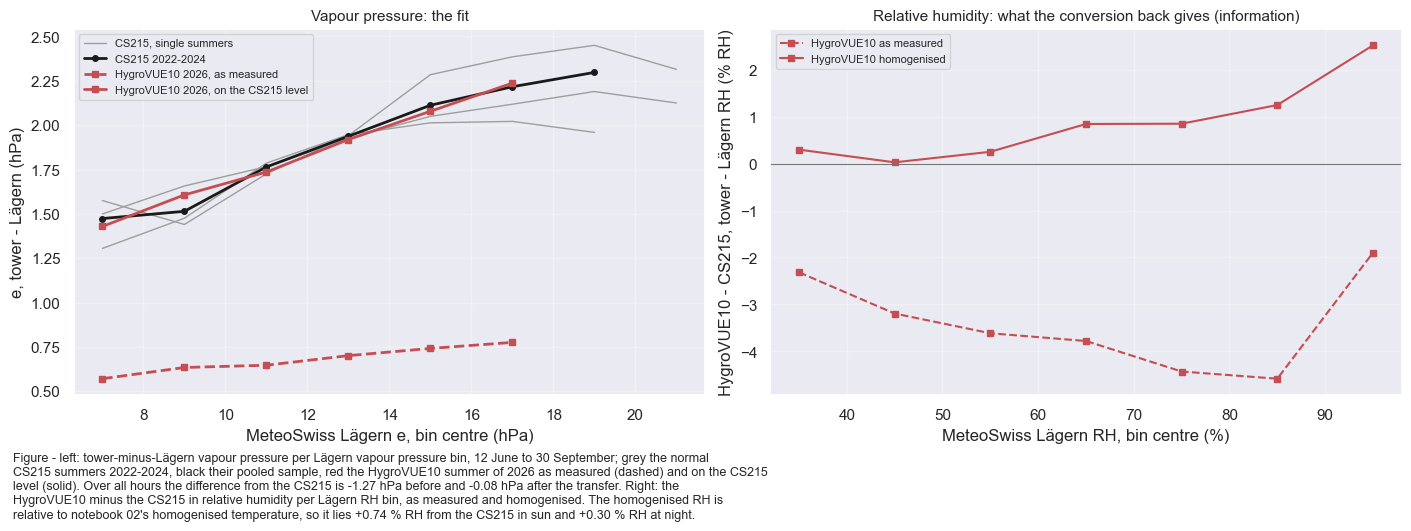

In [60]:
fig, axs = plt.subplots(ncols=2, figsize=(14, 5.2), dpi=100, layout='constrained')
_emid = np.array([(_i.left + _i.right) / 2 for _i in HV_SCORE_E.index])
for _k, _y in enumerate(HV_CS215_YEARS):
    _my, _ny = binned_e(CS_SAMPLE[CS_SAMPLE.index.year == _y])
    axs[0].plot(_emid, _my.where(_ny >= HV_MIN_BIN_RECORDS / 4).values, color='#9E9E9E', lw=1,
                label='CS215, single summers' if _k == 0 else None)
_mc, _nc = binned_e(CS_SAMPLE)
axs[0].plot(_emid, _mc.where(_nc >= HV_MIN_BIN_RECORDS).values, color='k', lw=2, marker='o', ms=4,
            label=f'CS215 {HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]}')
for _s, _ls, _lab in [(HV_SAMPLE, '--', 'as measured'), (HV_SAMPLE_CS, '-', 'on the CS215 level')]:
    _mh, _nh = binned_e(_s)
    axs[0].plot(_emid, _mh.where(_nh >= HV_MIN_BIN_RECORDS).values, color='#C44E52', lw=2, ls=_ls,
                marker='s', ms=4, label=f'HygroVUE10 {HV_START.year}, {_lab}')
axs[0].set_xlabel('MeteoSwiss Lägern e, bin centre (hPa)')
axs[0].set_ylabel('e, tower - Lägern (hPa)')
axs[0].set_title('Vapour pressure: the fit', fontsize=11)
axs[0].legend(fontsize=8)
_rmid = np.array([(_i.left + min(_i.right, 100.0)) / 2 for _i in HV_RH_RESIDUAL.index])
axs[1].plot(_rmid, HV_RH_RESIDUAL['as measured - CS215 (% RH)'], color='#C44E52', ls='--', marker='s',
            ms=4, label='HygroVUE10 as measured')
axs[1].plot(_rmid, HV_RH_RESIDUAL['homogenised - CS215 (% RH)'], color='#C44E52', marker='s', ms=4,
            label='HygroVUE10 homogenised')
axs[1].axhline(0, color='#757575', lw=0.8)
axs[1].set_xlabel('MeteoSwiss Lägern RH, bin centre (%)')
axs[1].set_ylabel('HygroVUE10 - CS215, tower - Lägern RH (% RH)')
axs[1].set_title('Relative humidity: what the conversion back gives (information)', fontsize=11)
axs[1].legend(fontsize=8)
for _ax in axs:
    _ax.grid(alpha=.3)
figcap(fig, f"left: tower-minus-Lägern vapour pressure per Lägern vapour pressure bin, 12 June to 30 "
            f"September; grey the normal CS215 summers {HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]}, black "
            f"their pooled sample, red the HygroVUE10 summer of {HV_START.year} as measured (dashed) and "
            f"on the CS215 level (solid). Over all hours the difference from the CS215 is "
            f"{HV_E_BEFORE:+.2f} hPa before and {HV_E_AFTER:+.2f} hPa after the transfer. Right: the "
            f"HygroVUE10 minus the CS215 in relative humidity per Lägern RH bin, as measured and "
            f"homogenised. The homogenised RH is relative to notebook 02's homogenised temperature, so "
            f"it lies {HV_RH_SUN:+.2f} % RH from the CS215 in sun and {HV_RH_NIGHT:+.2f} % RH at night.")


#### What step 1️⃣2️⃣ settles

From `HV_START` the column holds a third probe. In vapour pressure against Lägern the HygroVUE10
reads drier than the normal CS215, by more than the CS215 summers differ among themselves. Hence:

- the HygroVUE10 era has its own sensor code (`4`) and its own reconstruction offsets, and the
  swap half-hour has code `5` and belongs to the code `6` era;
- `RH_T1_47_1_HOMOGENIZED` carries the HygroVUE10 era with its vapour pressure on the CS215 level,
  converted back with `02`'s homogenised temperature. In vapour pressure the transfer meets the
  tolerances asserted above, and the month hold-out supports it on months it was not fitted on,
within a tolerance pooled over the months; its residuals follow the season.

In relative humidity the homogenised HygroVUE10 era is not on the level of the CS215's own reading
in sun: it refers to `02`'s homogenised temperature, which carries no radiative excess, while the
CS215's `RH` is relative to its warm probe (table above). At night the two agree. The transfer is
fitted on one summer and applied unchanged to later months; it is to be refitted once the
HygroVUE10 record includes a winter.


#### What this section settles

`RH_T1_47_1` is **three instruments in one column**: a Rotronic MP101A from September 2004 to
December 2015, a Campbell CS215 from 21 January 2016, and a Campbell HygroVUE10 from 5 June 2026.
At the first change the column steps upwards by **2.1 to 3.3 percentage points** and **3.9 to 4.1**
away from saturation. That step is on the tower probe and present at every hour, and the replaced
probe had drifted past 100 % in 3.6 % of its last full year. The CS215 changed state twice before
it was replaced: from 22 October 2024 it heated abnormally in sun, and after its handling on 16 May
2025 its daytime excess was gone; in `RH` both are effects of the probe temperature (step 1️⃣1️⃣).
At the second probe change the column becomes drier in vapour pressure (step 1️⃣2️⃣). Hence:

- **`FLAG_RH_T1_47_1_SOURCE`** names the probe generation and state of every record, with the
  codes of `02`, so the field name does not imply a continuity the hardware lacks.
- **Reconstruction offsets are fitted within each era and probe state**, five since June 2026. A
  relationship across a change would put reconstructed records on neither side's level, the failure
  `02` documents for gap-filling models. At the 2016 change this concerns about a thousand records,
  almost all in the January 2016 outage, moved by up to 1.8 % RH.
- **`RH_T1_47_1_HOMOGENIZED` puts the other probes on the CS215 level.** No constant fits the 2016
  step, which is 3 to 6 percentage points in the drier half of the range and at most 1.1 above 95 %
  RH, so the MP101A era is raised by a humidity-dependent transfer. Fitted on the era means that
  transfer is unstable, because both eras drift; fitted against NABEL close to the break it is
  stable and removes most of the step against Lägern (step 🔟). The HygroVUE10 era is transferred
  in vapour pressure, fitted on one summer (step 1️⃣2️⃣). The CS215 itself is left as measured in
  all three states.
- **The 2016 correction depends on the reference.** Fitted against Lägern it would be larger by
  several tenths of a percentage point on average and by up to about two just below saturation,
  the uncertainty of the homogenised column across 2016.
- **The drift within the eras and the probe heating of 2024-2025 are not corrected.** The drift is
  unattributed after NABEL stops in 2018, and fitting it away would replace the measurement with
  the reference; the heating is a temperature error, which belongs to `02`.

::: {.callout-warning title="Known limitation of this product"}
**Any statistic from `RH_T1_47_1` that crosses 21 January 2016 or 5 June 2026 contains a probe
step**: period means, trends, year rankings and anomalies over the full record. Use
`RH_T1_47_1_HOMOGENIZED` for these, or stay within one era (filter on `FLAG_RH_T1_47_1_SOURCE`).

**The homogenised column is not homogeneous over decades.** Against MeteoSwiss the MP101A era
drifts downwards and the CS215 era upwards, each by a few tenths of a percentage point a year
(step 🔟), so a trend from either column, and a comparison of years far from the break, still
contains sensor movement. Across 2016 the homogenised column carries the reference dependence of
its correction, largest in humid conditions. **In sun, codes `7` and `6` carry the probe's
heating**: code `7` reads low, code `6` higher than the normal CS215, in both columns. From June
2026 the homogenised `RH` refers to `02`'s homogenised temperature and lies above the CS215's own
level in sun.

Quantities computed from `RH` at low humidity, VPD above all, inherit more of the step. Notebook
`07` computes VPD from the measured series and the **homogenised** `TA` and measures a residual
step of about 17 % of the mean. With the uncorrected `TA` it would appear about three times
smaller, because the two input errors have opposite signs on VPD, a masking not to be relied on.
:::


### Sensor era of every record

The exported flag, built from the two dates derived above and from the settings of 2024-2026,
with the codes of notebook `02`. It also supplies the era label on which the reconstruction fits
are split, one per probe and probe state: `analog`, `cs215`, `cs215_heated` (code `7`),
`cs215_2025` (code `6`) and `hygrovue10`. Each probe half-hour takes the label of the era before
it. The flag is compared with `02`'s `FLAG_TA_T1_47_1_SOURCE` at the end of the cell.


#### 📋 Table: sensor era codes and their periods

In [61]:
# The sensor era of every record, from the two dates derived above and the settings of 2024-2026.
# The codes are notebook 02's: one probe delivers TA and RH, so the two products must agree on when
# it changed, and the comparison below asserts that they do.
RECORD_START = rh_2004_2026[TARGET].first_valid_index()

SOURCE_LEGEND = {
    0: '0 = Campbell CS215 on SDI-12, normal state',
    1: '1 = Rotronic MP101A, single-ended analog',
    2: '2 = acquisition changeover, sensor era undetermined',
    3: '3 = before the tower record begins',
    4: '4 = Campbell HygroVUE10 on SDI-12',
    5: '5 = probe handling or swap half-hour, removed and reconstructed with the period before it',
    6: '6 = Campbell CS215 after the change of 16 May 2025, reads high in sun',
    7: '7 = Campbell CS215 with excess daytime heating, reads low in sun',
}

_idx = rh_2004_2026.index
source = pd.Series(0, index=_idx, dtype=int, name=f'FLAG_{TARGET}_SOURCE')
source[(_idx >= RECORD_START) & (_idx <= LAST_ANALOG)] = 1
source[(_idx > LAST_ANALOG) & (_idx < BREAK)] = 2
source[_idx < RECORD_START] = 3
source[(_idx >= EXCESS_START) & (_idx < HANDLING_RECORD)] = 7
source[(_idx >= RESET_START) & (_idx < HV_START)] = 6
source[_idx >= HV_START] = 4
source[_idx.isin(PROBE_HALF_HOURS)] = 5

# The era label of the offset fits, one per probe and probe state, changing exactly at the dates
# above. The pre-record block of 2004 lies inside the analog era's months and the changeover outage
# is bracketed by analog measurements on its left, so both are fitted on the analog era. Each probe
# half-hour lies before the change it holds and is fitted on the era before it.
ERA_FIT = pd.Series(np.select([_idx >= HV_START, _idx >= RESET_START, _idx >= EXCESS_START, _idx >= BREAK],
                              ['hygrovue10', 'cs215_2025', 'cs215_heated', 'cs215'], default='analog'),
                    index=_idx)
ERA_LABELS = ['analog', 'cs215', 'cs215_heated', 'cs215_2025', 'hygrovue10']

tabcap("the sensor generation behind every record and the period each covers. Codes 2 (changeover "
       "outage) and 3 (before the tower record begins) mark records no probe at this height "
       "stands behind; code 5 marks the two half-hours in which a probe was handled")
_src = pd.DataFrame({
    'sensor era': [SOURCE_LEGEND[_c].split(' = ')[1] for _c in sorted(SOURCE_LEGEND)],
    'from': [source[source == _c].index.min() for _c in sorted(SOURCE_LEGEND)],
    'to': [source[source == _c].index.max() for _c in sorted(SOURCE_LEGEND)],
    'records': [int((source == _c).sum()) for _c in sorted(SOURCE_LEGEND)],
    'offset fitted as': [', '.join(ERA_FIT[source == _c].unique()) for _c in sorted(SOURCE_LEGEND)],
}, index=pd.Index(sorted(SOURCE_LEGEND), name='code'))
display(_src)

assert int((source == 2).sum()) > 0 and int((source == 3).sum()) > 0, (
    "the changeover interval or the pre-record period has become empty, so the two codes that "
    "mark records no probe stands behind no longer describe anything")
assert source.isin(SOURCE_LEGEND).all(), "a record carries a source code with no legend entry"
assert EXCESS_START < HANDLING_RECORD < RESET_START < SWAP_RECORD < HV_START, (
    "the era boundaries of 2024-2026 are not in order")
assert int((source == 5).sum()) == 2 and source.loc[PROBE_HALF_HOURS].eq(5).all(), (
    "the probe half-hour code no longer marks exactly the handling and the swap half-hours")
assert source.loc[HV_START:].eq(4).all() and not source.loc[:SWAP_RECORD].eq(4).any(), (
    "the HygroVUE10 code no longer covers exactly the records from HV_START")
assert (source == 7).sum() == ((_idx >= EXCESS_START) & (_idx < HANDLING_RECORD)).sum(), (
    "code 7 no longer covers exactly the heated CS215 up to the handling")
assert (source == 6).sum() == ((_idx >= RESET_START) & (_idx < HV_START)).sum() - 1, (
    "code 6 no longer covers exactly the CS215 after the handling, less the swap half-hour")
# The era labels tile the record, and none spans a probe change.
assert ERA_FIT.isin(ERA_LABELS).all(), "a record carries no era label"
for _e, _sel in [('analog', _idx < BREAK), ('cs215', (_idx >= BREAK) & (_idx < EXCESS_START)),
                 ('cs215_heated', (_idx >= EXCESS_START) & (_idx < RESET_START)),
                 ('cs215_2025', (_idx >= RESET_START) & (_idx < HV_START)), ('hygrovue10', _idx >= HV_START)]:
    assert (ERA_FIT[_sel] == _e).all() and (ERA_FIT == _e).sum() == _sel.sum(), (
        f"the era label {_e!r} of the offset fits no longer covers exactly its period")
assert ERA_FIT.loc[HANDLING_RECORD] == 'cs215_heated' and ERA_FIT.loc[SWAP_RECORD] == 'cs215_2025', (
    "a probe half-hour would be reconstructed with an era other than the one before it")

# The same probe in notebook 02. Its product written before codes 6 and 7 existed carries code 0
# there and on the handling half-hour, so those records are compared only once 02 writes the codes.
_src02 = ta02[TA_SRCCOL].astype(int)
if {6, 7} <= set(_src02.unique()):
    assert (_src02.values == source.values).all(), (
        "the source flag differs from notebook 02's FLAG_TA_T1_47_1_SOURCE, though one probe delivers both")
    print(f"Source flag equals notebook 02's {TA_SRCCOL} on every record.")
else:
    _cmp = ~source.isin([6, 7]) & ~_idx.isin([HANDLING_RECORD])
    _diff = int((_src02[_cmp] != source[_cmp]).sum())
    assert _diff == 0, f"the source flag differs from notebook 02's on {_diff} records outside codes 6 and 7"
    print(f"Notebook 02's product carries no codes 6 and 7 yet (written before they existed): the "
          f"comparison of the {int((~_cmp).sum()):,} records of codes 6 and 7 and the handling "
          f"half-hour is skipped; the other {int(_cmp.sum()):,} records agree.")


Table - the sensor generation behind every record and the period each covers. Codes 2 (changeover
outage) and 3 (before the tower record begins) mark records no probe at this height stands behind;
code 5 marks the two half-hours in which a probe was handled



,sensor era,from,to,records,offset fitted as
code,,,,,
0,"Campbell CS215 on SDI-12, normal state",2016-01-21 14:15:00,2024-10-21 23:45:00,153428,cs215
1,"Rotronic MP101A, single-ended analog",2004-09-20 10:45:00,2015-12-31 23:45:00,197739,analog
2,"acquisition changeover, sensor era undetermined",2016-01-01 00:15:00,2016-01-21 13:45:00,988,analog
3,before the tower record begins,2004-01-01 00:15:00,2004-09-20 10:15:00,12645,analog
4,Campbell HygroVUE10 on SDI-12,2026-06-05 11:45:00,2026-09-30 23:45:00,5641,hygrovue10
5,"probe handling or swap half-hour, removed and ...",2025-05-16 09:45:00,2026-06-05 11:15:00,2,"cs215_heated, cs215_2025"
6,Campbell CS215 after the change of 16 May 2025...,2025-05-16 10:15:00,2026-06-05 10:45:00,18482,cs215_2025
7,"Campbell CS215 with excess daytime heating, re...",2024-10-22 00:15:00,2025-05-16 09:15:00,9907,cs215_heated


Source flag equals notebook 02's FLAG_TA_T1_47_1_SOURCE on every record.


#### Negative control

The era split adds one way for the fit to fail silently; it is checked before use.


In [62]:
# An era with no overlap must raise rather than return NaNs or fall back to the other era.
_empty_era = pd.Series('analog', index=rh_2004_2026.index)
_empty_era[NABEL_REF.isna()] = 'era-with-no-overlap'
try:
    monthly_offset_table(rh_2004_2026[TARGET], NABEL_REF, era=_empty_era)
except ValueError as _exc:
    print(f"OK, monthly_offset_table raised on an era with no overlap: {_exc}")
else:
    raise AssertionError("(!) monthly_offset_table accepted an era it cannot fit an offset for.")


OK, monthly_offset_table raised on an era with no overlap: sensor era 'era-with-no-overlap' has no overlap between the two series, so no offset can be fitted for it. Reconstructing its records from another era's offset is exactly what this split exists to prevent.


***

## 🟩 Reconstruction from the NABEL sensor


### Why, and what this is not

`RH_T1_47_1` begins on **20 September 2004**, which leaves an 8.7-month block without measurement,
besides scattered gaps and the removed 2012 periods. NABEL at 49 m on the same tower measured
throughout **2004-2018**. Its values are transferred, not modelled (no drivers, no XGBoost, unlike
`01`-`03`): a long block such as 2004 is what a driver-based model handles worst and a co-located
sensor handles well. Records without a NABEL value, chiefly after 2018, are filled in a second pass
from MeteoSwiss Lägern.

### The two sensors do not differ by a constant

Over 2004-2018 the 47 m sensor reads **moister** than NABEL, by an amount that varies in three
ways.

**Seasonally** (mean offset `47 m - NABEL`, pooled over the overlap):

| month | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| offset (% RH) | 3.21 | 3.86 | 2.96 | 2.14 | 1.54 | 0.88 | 0.50 | 0.37 | 0.54 | 1.43 | 2.31 | 2.81 |

The winter divergence is a known, unresolved property of this pair, and the 2004 block (January to
September) covers the worst months.

**Over time** (annual mean offset):

| year | 2004 | 2006 | 2008 | 2010 | 2012 | 2014 | 2016 | 2017 | 2018 |
|---|---|---|---|---|---|---|---|---|---|
| offset (% RH) | 1.52 | 0.08 | 0.85 | 1.41 | 2.25 | 3.19 | 4.31 | 5.06 | 3.51 |

An offset pooled over the overlap is dominated by the late years and is **too large for 2004**:
`+3.42 % RH` for January 2004 against `+1.35 % RH` from the local evidence.

**At the sensor change**: the 2016 value is the probe replacement, not drift.

`monthly_offset_table` therefore fits each month on the overlap within `±2` calendar years **and
within the record's own sensor era**.

### Validation

Leave-one-year-out over 1 January to 20 September (the span reconstructed in 2004), each of the 14
usable overlap years held out in turn:

| method | pooled bias | pooled RMSE | median RMSE |
|---|---|---|---|
| straight NABEL copy | **-1.95 % RH** | 4.15 | 3.30 |
| offset, pooled over all overlap | -0.13 % RH | 3.45 | 2.72 |
| per-month linear regression | -0.13 % RH | 3.45 | 2.73 |
| **per-month offset, fitted ±2 years** | **-0.20 % RH** | **3.08** | **2.60** |

- A straight copy has a ~2 % RH dry bias, concentrated in winter (January RMSE 5.26, February
  6.22).
- A per-month regression scores the same as a per-month offset, so the simpler offset is used.
- Local fitting gains another ~11 % of RMSE, most in the years furthest from the record mean
  (2017: 4.62 -> 3.65, 2018: 4.74 -> 3.37).

A reconstructed record carries about **3 % RH** of uncertainty, against a sensor agreement of about
2 % RH in summer, and is flagged as an estimate. All 14 held-out years lie in the analog era, so the
era split leaves these scores unchanged.


#### 📋 Table: offsets for the 2004 block by month

In [63]:
# NABEL ends in 2018, so the eras from EXCESS_START on (the CS215 states of 2024-2025 and the
# HygroVUE10) have no NABEL overlap and no NABEL value to reconstruct from. The helper raises on an
# era without overlap (negative control above), so this pass is fitted on the record before it.
_nabel_span = rh_2004_2026.index < EXCESS_START
assert NABEL_REF[~_nabel_span].isna().all(), "NABEL now has values after EXCESS_START"
OFFSETS = monthly_offset_table(rh_2004_2026.loc[_nabel_span, TARGET], NABEL_REF[_nabel_span],
                               era=ERA_FIT[_nabel_span])

_overlap = pd.concat([rh_2004_2026[TARGET], NABEL_REF], axis=1).dropna()
print(f"Offsets fitted on {len(_overlap):,} overlapping records "
      f"(+/-{OFFSET_WINDOW_YEARS} years, min {OFFSET_MIN_SAMPLES} samples per month), "
      f"separately per sensor era:")
for _e in sorted(ERA_FIT.unique()):
    print(f"  {_e}: {int(ERA_FIT.reindex(_overlap.index).eq(_e).sum()):,} records")

# The 2004 block is by far the largest reconstruction.
tabcap("the offsets the 2004 block receives, by month. The block precedes the tower record and is "
       "fitted on the analog era")
display(pd.Series({_m: round(OFFSETS[('analog', 2004, _m)], 2) for _m in range(1, 10)},
                  name='offset (% RH)').rename_axis('month'))

Offsets fitted on 239,241 overlapping records (+/-2 years, min 500 samples per month), separately per sensor era:
  analog: 194,986 records
  cs215: 44,255 records
  cs215_2025: 0 records
  cs215_heated: 0 records
  hygrovue10: 0 records
Table - the offsets the 2004 block receives, by month. The block precedes the tower record and is
fitted on the analog era



month
1    1.35
2    2.13
3    2.03
4    1.24
5    0.40
6   -0.32
7   -0.86
8   -0.38
9   -1.02
Name: offset (% RH), dtype: float64

#### 📋 Table: fitted offsets per era, year and month

In [64]:
# The full table per era, so a drifting or fallback-filled year is visible.
tabcap("the fitted offset for every year and month, one block per sensor era. Only the rows an era "
       "covers are used; both are shown so the January 2016 step appears as the difference "
       "between the two blocks")
_offset_matrix = OFFSETS.unstack()
_offset_matrix.index.names = ['era', 'year']
_offset_matrix.columns.name = 'month'
display(_offset_matrix.round(2))

_common = [_y for _y in range(2013, 2019)]
_gap = (_offset_matrix.loc['cs215'].reindex(_common).mean().mean()
        - _offset_matrix.loc['analog'].reindex(_common).mean().mean())
print(f"\nmean offset against NABEL, {_common[0]}-{_common[-1]}: "
      f"analog era {_offset_matrix.loc['analog'].reindex(_common).mean().mean():+.2f} % RH, "
      f"CS215 era {_offset_matrix.loc['cs215'].reindex(_common).mean().mean():+.2f} % RH "
      f"({_gap:+.2f} % RH apart)")
assert _gap > 1.0, (
    "the two eras' offsets against NABEL are no longer separated, so splitting the fit at the "
    "sensor change no longer does anything and the step measured above has gone away")


Table - the fitted offset for every year and month, one block per sensor era. Only the rows an era
covers are used; both are shown so the January 2016 step appears as the difference between the two
blocks



month          1      2     3     4     5     6     7     8     9     10    11    12
era    year                                                                         
analog 2004  1.35   2.13  2.03  1.24  0.40 -0.32 -0.86 -0.38 -1.02 -0.19  0.71  1.65
       2005  1.06   1.57  1.76  0.66  0.21 -0.46 -0.88 -0.55 -0.99 -0.25  0.90  1.58
       2006  1.22   1.69  1.89  0.84  0.29 -0.46 -0.84 -0.65 -0.78 -0.07  1.09  1.68
       2007  1.37   1.85  2.01  0.86  0.23 -0.42 -0.84 -0.68 -0.85 -0.03  1.16  1.65
       2008  1.51   1.60  1.99  0.74  0.32 -0.53 -0.95 -0.72 -0.53  0.38  1.64  2.02
...           ...    ...   ...   ...   ...   ...   ...   ...   ...   ...   ...   ...
cs215  2020  6.92  10.07  7.13  5.22  4.66  4.78  3.05  2.98  3.59  4.72  5.83  6.31
       2021  7.41   7.33  5.93  4.80  3.93  4.00  3.11  2.98  3.59  4.72  5.83  6.31
       2022  7.41   7.33  5.93  4.80  3.93  4.00  3.11  2.98  3.59  4.72  5.83  6.31
       2023  7.41   7.33  5.93  4.80  3.93  4.00  3.11  2.98  3.59  4.72  5.83  6.31
       2024  7.41   7.33  5.93  4.80  3.93  4.00  3.11  2.98  3.59  4.72  5.83  6.31

[42 rows x 12 columns]


mean offset against NABEL, 2013-2018: analog era +1.96 % RH, CS215 era +4.85 % RH (+2.89 % RH apart)


In [65]:
_before_recon = rh_2004_2026[TARGET].copy()
rh_2004_2026[TARGET], reconstructed = reconstruct_from_reference(
    rh_2004_2026[TARGET], NABEL_REF, OFFSETS, era=ERA_FIT)

print(f"Reconstructed {int(reconstructed.sum()):,} records from {REFERENCE}")
print(f"  previously never measured: {int((reconstructed & never_measured).sum()):,}")
print(f"  previously removed here:   {int((reconstructed & removed_here).sum()):,}")
for _e in sorted(ERA_FIT.unique()):
    print(f"  fitted on the {_e} era:      {int((reconstructed & (ERA_FIT == _e)).sum()):,}")
print(f"Still missing:  {int(rh_2004_2026[TARGET].isna().sum()):,} "
      f"(no NABEL value available)")

# Reconstruction must not touch a record that already had a value.
assert rh_2004_2026.loc[_before_recon.notna(), TARGET].equals(_before_recon.dropna()), \
    "reconstruction overwrote measured values"
print("\nMeasured records untouched by the reconstruction.")

# Reconstructed values must respect the physical bounds.
_rec = rh_2004_2026.loc[reconstructed, TARGET]
print(f"Reconstructed range: {_rec.min():.2f} - {_rec.max():.2f} %")
assert _rec.between(0, 100).all(), "NABEL reconstruction produced out-of-range RH"

# And no record may be reconstructed with the other era's relationship. This is the assertion the
# era split exists for; without it the split could be removed and nothing would fail.
_idx = rh_2004_2026.index
assert not (reconstructed & (_idx >= EXCESS_START)).any() and \
       (ERA_FIT[reconstructed & (_idx >= BREAK)] == 'cs215').all() and \
       (ERA_FIT[reconstructed & (_idx < BREAK)] == 'analog').all(), (
    "a record was reconstructed with the offset relationship of another sensor era")
print("Every reconstructed record used the offset fitted for its own sensor era.")


Reconstructed 15,729 records from RH_NABEL_T1_49_1
  previously never measured: 14,514
  previously removed here:   1,215
  fitted on the analog era:      15,726
  fitted on the cs215 era:      3
  fitted on the cs215_2025 era:      0
  fitted on the cs215_heated era:      0
  fitted on the hygrovue10 era:      0
Still missing:  922 (no NABEL value available)

Measured records untouched by the reconstruction.
Reconstructed range: 22.65 - 100.00 %
Every reconstructed record used the offset fitted for its own sensor era.


### Does the reconstructed 2004 block look like a plausible year?

There is no 47 m measurement in 2004 to validate against. What can be checked is climatological
plausibility: monthly means near those of the following measured years, within interannual
variability, and an `RH` diurnal structure rather than a flat or clipped series.

#### 📋 Table: reconstructed 2004 against measured monthly means

In [66]:
_recon_2004 = rh_2004_2026.loc['2004-01-01':'2004-09-20', TARGET]
_measured_ref = rh_2004_2026.loc['2005':'2008', TARGET]
_measured_ref = _measured_ref[_measured_ref.index.month <= 9]

_cmp = pd.DataFrame({
    '2004 (reconstructed)': _recon_2004.groupby(_recon_2004.index.month).mean().round(1),
    '2005-2008 (measured)': _measured_ref.groupby(_measured_ref.index.month).mean().round(1),
})
_cmp['difference'] = (_cmp.iloc[:, 0] - _cmp.iloc[:, 1]).round(1)
_cmp.index.name = 'month'
tabcap("the reconstructed 2004 block against the same months of the four measured years that "
       "follow. There is no 47 m measurement in 2004, so this checks climatological plausibility")
display(_cmp)

Table - the reconstructed 2004 block against the same months of the four measured years that follow.
There is no 47 m measurement in 2004, so this checks climatological plausibility



,2004 (reconstructed),2005-2008 (measured),difference
month,,,
1,89.5,84.6,4.9
2,74.7,82.5,-7.8
3,74.3,78.8,-4.5
4,66.7,69.7,-3.0
5,67.4,69.8,-2.4
6,70.1,69.6,0.5
7,69.4,68.9,0.5
8,74.3,77.9,-3.6
9,68.5,79.2,-10.7


#### 📊 Plot: heatmaps of 2004 and 2005

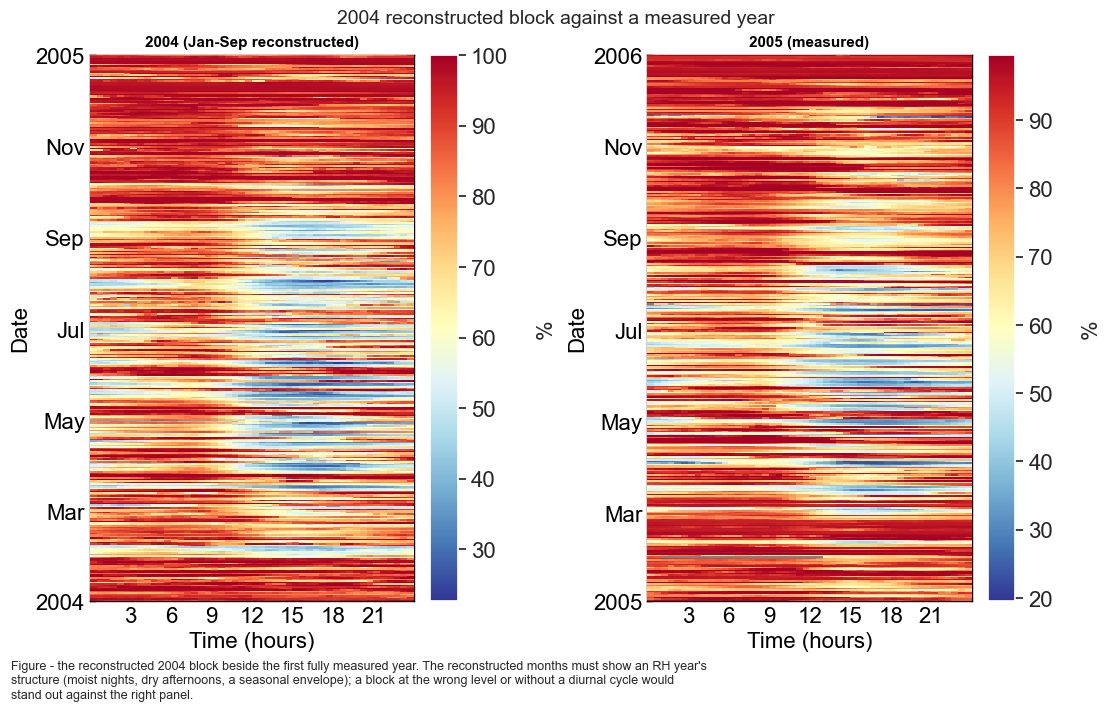

In [67]:
fig, axs = plt.subplots(ncols=2, figsize=(11, 7), dpi=100, layout="constrained")
fig.suptitle('2004 reconstructed block against a measured year', fontsize=14)
dv.plotting.HeatmapDateTime(series=rh_2004_2026.loc['2004', TARGET]).plot(
    ax=axs[0], cb_digits_after_comma=0, zlabel='%',
    format_style=dv.plotting.FormatStyle(title='2004 (Jan-Sep reconstructed)', title_fontsize=11))
dv.plotting.HeatmapDateTime(series=rh_2004_2026.loc['2005', TARGET]).plot(
    ax=axs[1], cb_digits_after_comma=0, zlabel='%',
    format_style=dv.plotting.FormatStyle(title='2005 (measured)', title_fontsize=11))
figcap(fig, "the reconstructed 2004 block beside the first fully measured year. The "
            "reconstructed months must show an RH year's structure (moist nights, dry afternoons, "
            "a seasonal envelope); a block at the wrong level or without a diurnal cycle would "
            "stand out against the right panel.")


## 🟩 Second reconstruction pass: MeteoSwiss Lägern

NABEL ends in 2018. The gaps it leaves, almost all after 2018 and counted below, are filled from
MeteoSwiss Lägern (`RH_LAE_MS`, 2.5 km, 845 m, 2004-2026) in the same way: a per-month offset
fitted on the tower-Lägern overlap **within each sensor era and probe state**, added to the Lägern
value. There are five: the MP101A, the normal CS215, its two states of 2024-2025 and the HygroVUE10,
each fitted on its own overlap. Each probe half-hour is reconstructed with the offset of the era
before it.

Lägern is a weaker reference than NABEL. It correlates with tower `RH` at `r = 0.94` (alignment
guard above), and its offset varies seasonally, steps at the probe replacement and includes a real
altitude effect, which the monthly offset absorbs. Its fills carry flag `4`, distinct from NABEL's
`3`.

### Fit the offset and reconstruct

`reconstruct_from_reference` fills only the records still missing after the NABEL pass, clips to
`[0, 100]` and leaves every existing value untouched.


In [68]:
# Measured tower RH only: the NABEL-reconstructed records are excluded so the offset fit below
# never sees a value that is itself a transfer from another instrument.
measured_rh = rh_2004_2026[TARGET].where(~reconstructed)
_still_missing = rh_2004_2026[TARGET].isna()
print(f"Laegern covers {int((lae.notna() & _still_missing).sum()):,} of "
      f"{int(_still_missing.sum()):,} records still missing after the NABEL pass")

OFFSETS_LAE = monthly_offset_table(measured_rh, lae, era=ERA_FIT)

_overlap_n = int(pd.concat([measured_rh, lae], axis=1).dropna().shape[0])
print(f"Laegern offsets fitted on {_overlap_n:,} overlapping measured records "
      f"(+/-{OFFSET_WINDOW_YEARS} years, min {OFFSET_MIN_SAMPLES} samples per month), "
      f"split at each probe change like the NABEL pass.")
print(f"Fitted monthly offset range: {OFFSETS_LAE.min():+.2f} .. {OFFSETS_LAE.max():+.2f} % RH")

_before_recon_lae = rh_2004_2026[TARGET].copy()
rh_2004_2026[TARGET], reconstructed_lae = reconstruct_from_reference(
    rh_2004_2026[TARGET], lae, OFFSETS_LAE, era=ERA_FIT)

print(f"\nReconstructed {int(reconstructed_lae.sum()):,} records from {REFCOL}")
print(f"  previously never measured: {int((reconstructed_lae & never_measured).sum()):,}")
print(f"  previously removed here:   {int((reconstructed_lae & removed_here).sum()):,}")

# The Laegern pass may only fill records that were still missing: it must not overwrite a measured
# or a NABEL-reconstructed value, and must not overlap the NABEL mask.
assert rh_2004_2026.loc[_before_recon_lae.notna(), TARGET].equals(_before_recon_lae.dropna()), \
    "Laegern reconstruction overwrote an existing value"
assert int((reconstructed_lae & reconstructed).sum()) == 0, "Laegern overlaps the NABEL reconstruction"
print("Existing measured and NABEL-reconstructed records untouched by the Laegern pass.")

# No record is reconstructed with another probe era's offset. Each CS215 state of 2024-2025 and the
# HygroVUE10 have offsets fitted on their own records; each probe half-hour is reconstructed here
# with the offset of the era before it.
_idx = rh_2004_2026.index
for _e, _sel in [('analog', _idx < BREAK), ('cs215', (_idx >= BREAK) & (_idx < EXCESS_START)),
                 ('cs215_heated', (_idx >= EXCESS_START) & (_idx < RESET_START)),
                 ('cs215_2025', (_idx >= RESET_START) & (_idx < HV_START)), ('hygrovue10', _idx >= HV_START)]:
    assert (ERA_FIT[reconstructed_lae & _sel] == _e).all(), (
        f"a record of the {_e} era was reconstructed with another era's Laegern offset")
    print(f"  {_e} era: {int((reconstructed_lae & _sel).sum()):,} records reconstructed")
assert reconstructed_lae.loc[PROBE_HALF_HOURS].all() and ERA_FIT.loc[HANDLING_RECORD] == 'cs215_heated' \
       and ERA_FIT.loc[SWAP_RECORD] == 'cs215_2025', (
    "a probe half-hour was not reconstructed from Laegern with the offset of the era before it")
_hv_overlap = pd.concat([measured_rh[_idx >= HV_START], lae[_idx >= HV_START]], axis=1).dropna()
print(f"HygroVUE10-era offsets fitted on {len(_hv_overlap):,} records of its own, "
      f"{_hv_overlap.index.min():%d %b} -> {_hv_overlap.index.max():%d %b %Y}")

# Reconstructed values must respect the physical bounds.
_rec_lae = rh_2004_2026.loc[reconstructed_lae, TARGET]
print(f"Laegern-reconstructed range: {_rec_lae.min():.2f} - {_rec_lae.max():.2f} %")
assert _rec_lae.between(0, 100).all(), "Laegern reconstruction produced out-of-range RH"

# Both passes together must leave no gap.
_residual = int(rh_2004_2026[TARGET].isna().sum())
print(f"\nStill missing after both passes: {_residual}")
assert _residual == 0, "product still has gaps after the Laegern pass"
print("Product is complete: every record carries a value.")


Laegern covers 922 of 922 records still missing after the NABEL pass
Laegern offsets fitted on 381,915 overlapping measured records (+/-2 years, min 500 samples per month), split at each probe change like the NABEL pass.
Fitted monthly offset range: -4.92 .. +8.08 % RH

Reconstructed 922 records from RH_LAE_MS
  previously never measured: 920
  previously removed here:   2
Existing measured and NABEL-reconstructed records untouched by the Laegern pass.
  analog era: 40 records reconstructed
  cs215 era: 879 records reconstructed
  cs215_heated era: 2 records reconstructed
  cs215_2025 era: 1 records reconstructed
  hygrovue10 era: 0 records reconstructed
HygroVUE10-era offsets fitted on 5,641 records of its own, 05 Jun -> 30 Sep 2026
Laegern-reconstructed range: 39.82 - 100.00 %

Still missing after both passes: 0
Product is complete: every record carries a value.


***

## ➡️ Prepare dataframe for export

The provenance flag combines `never_measured` (taken before any removal), `removed_here` (the
2012 windows and the two probe half-hours of 2025 and 2026), `reconstructed` (NABEL) and
`reconstructed_lae` (Lägern). The reconstruction masks are applied last, so a record removed and
then reconstructed reads `3` or `4`. Codes `1` and `2` would remain only where neither reference
has a value, which does not occur.

The **sensor-era flag** describes the timestamp, not the value, so it is defined for every record:
a NABEL reconstruction in January 2016 still falls in the changeover outage and reads `2`.

The **homogenised column** is assigned by timestamp, the rule notebook `02` uses. Every record
before `BREAK` (source codes `1`, `2` and `3`) is raised by the 2016 transfer of step 🔟, because
the reconstruction offsets of all three are fitted on the MP101A era and so put them on its level.
Every record from `HV_START` (code `4`) gets the vapour pressure transfer of step 1️⃣2️⃣, with its
`e` from `02`'s complete `TA_T1_47_1_gfXG` and the conversion back with `02`'s homogenised `TA`.
The CS215 in all its states and both probe half-hours (codes `0`, `5`, `6`, `7`) are copied
unchanged. Measured and reconstructed records of one era get the same transfer.


### 📋 Table: the exported frame

In [69]:
VALCOL = TARGET
HOMCOL = f"{TARGET}_HOMOGENIZED"
FLAGCOL = f"FLAG_{TARGET}_MISSING"
SRCCOL = f"FLAG_{TARGET}_SOURCE"

flag = pd.Series(0, index=rh_2004_2026.index, dtype=int, name=FLAGCOL)
flag[never_measured] = 1
flag[removed_here] = 2
flag[reconstructed] = 3       # NABEL pass
flag[reconstructed_lae] = 4   # Laegern pass; both reconstruction masks are applied after 1/2, so a
                              # reconstructed record reads 3 or 4, never 1 or 2

# The homogenised column on the CS215 level, by timestamp as in notebook 02: before BREAK the 2016
# transfer (step 10); from HV_START the vapour pressure transfer (step 12), with the HygroVUE10's
# own TA from 02 (complete) for e and 02's homogenised TA for the conversion back; the CS215 in all
# its states (codes 0, 6, 7) and both probe half-hours unchanged (step 11).
_before_break = rh_2004_2026.index < BREAK
_hv_era = rh_2004_2026.index >= HV_START
homogenized = rh_2004_2026[VALCOL].copy().rename(HOMCOL)
homogenized[_before_break] = mp101a_to_cs215(rh_2004_2026.loc[_before_break, VALCOL])
homogenized[_hv_era] = hv_to_cs215_rh(rh_2004_2026.loc[_hv_era, VALCOL], ta02.loc[_hv_era, TA_COL],
                                      ta02.loc[_hv_era, TA_HOMCOL])

export_df = pd.concat([rh_2004_2026[VALCOL], flag, homogenized, source.rename(SRCCOL)], axis=1)
tabcap("the exported frame: the value column, where it came from, the same on the CS215 level, "
       "and which probe generation stands behind the timestamp")
export_df


Table - the exported frame: the value column, where it came from, the same on the CS215 level, and
which probe generation stands behind the timestamp



,RH_T1_47_1,FLAG_RH_T1_47_1_MISSING,RH_T1_47_1_HOMOGENIZED,FLAG_RH_T1_47_1_SOURCE
TIMESTAMP_MIDDLE,,,,
2004-01-01 00:15:00,97.718962,3,97.844442,3
2004-01-01 00:45:00,96.918962,3,97.181388,3
2004-01-01 01:15:00,93.552296,3,94.929131,3
2004-01-01 01:45:00,92.652296,3,94.392545,3
2004-01-01 02:15:00,93.985629,3,95.187488,3
...,...,...,...,...
2026-09-30 21:45:00,54.148075,0,58.653792,4
2026-09-30 22:15:00,55.498410,0,60.100209,4
2026-09-30 22:45:00,56.956725,0,61.649410,4


Sanity check. The series is **complete**, so the checks match notebooks `01`-`03`:

- continuous 30MIN index without duplicates, both flags on every record, no missing value, last
  record at `PERIOD_END`
- a value is present if and only if the provenance flag is in `PRESENT_FLAGS` (`0`, `3`, `4`)
- `RH` within `[0, 100]`, both ends asserted, in both value columns
- the **sensor-era flag** partitions the record, never labels a measured record as changeover,
  pre-record or probe half-hour, and the eras follow one another at `BREAK`, `EXCESS_START`,
  `RESET_START` and `HV_START`, with a probe half-hour before each of the last two
- the **homogenised column** equals the value column on source codes `0`, `5`, `6` and `7`,
  equals the 2016 transfer of the value on codes `1`, `2` and `3` and the vapour pressure transfer
  on code `4`, reconstructed records included; the 2016 transfer never lowers a value, and both
  corrections take many distinct values, as humidity-dependent transfers must


### 📋 Table: what the homogenised column adds

In [70]:
print(f"Records:         {len(export_df):,}")
print(f"Values present:  {export_df[VALCOL].notna().sum():,}")
print(f"Missing values:  {export_df[VALCOL].isnull().sum():,}")
print(f"Missing flags:   {export_df[FLAGCOL].isnull().sum()} / {export_df[SRCCOL].isnull().sum()}")
print(f"Duplicate index: {export_df.index.duplicated().sum()}")
print(f"Index gaps:      {(export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum()}")
print(f"Min / max:       {export_df[VALCOL].min():.2f} / {export_df[VALCOL].max():.2f} %")

# The flag has to describe the value column exactly, otherwise a downstream consumer would be
# working from a wrong provenance.
_agree = (export_df[VALCOL].notna() == export_df[FLAGCOL].isin(PRESENT_FLAGS)).all()
print(f"\nFlag agrees with values: {bool(_agree)}")
assert _agree, "flag and value column disagree about which records carry a value"

# RH is bounded. The correction clips the upper end, reconstruction clips both; nothing else does.
assert export_df[VALCOL].min() >= 0, "RH below 0%"
assert export_df[VALCOL].max() <= 100, "RH above 100%"
print("Bounds [0, 100] hold.")

# The product is complete: both reconstruction passes together leave no gap.
assert export_df[VALCOL].isna().sum() == 0, "product is not complete"
print("Complete: no missing values.")

# The source flag partitions the record; a measured record labelled 2, 3 or 5 would mean the
# changeover dates and the data disagree.
assert export_df[SRCCOL].isin(SOURCE_LEGEND).all(), "a record carries an unknown source code"
_measured = export_df[FLAGCOL] == 0
assert export_df.loc[_measured, SRCCOL].isin([0, 1, 4, 6, 7]).all(), (
    "a measured record is labelled as belonging to the changeover, to the period before the "
    "record begins or to a probe half-hour, so the sensor-era dates no longer describe the data")
assert export_df.loc[PROBE_HALF_HOURS, FLAGCOL].eq(4).all(), (
    "a probe half-hour is no longer reconstructed from Laegern")
_first = lambda c: export_df.index[export_df[SRCCOL] == c].min()
_last = lambda c: export_df.index[export_df[SRCCOL] == c].max()
assert _last(1) < BREAK <= _first(0), "the analog and CS215 eras now overlap in time"
assert _last(0) < EXCESS_START == _first(7) and _last(7) < HANDLING_RECORD < RESET_START == _first(6), (
    "the CS215 states of 2024-2025 no longer follow one another at EXCESS_START and the handling")
assert _last(6) < SWAP_RECORD < HV_START == _first(4), (
    "the CS215 and HygroVUE10 eras are no longer separated by the swap half-hour alone")
print("Source flag partitions the record and agrees with the measurement dates.")

# The homogenised column. On the CS215 in all its states and on the probe half-hours it is the
# value column; before BREAK it is the 2016 transfer of the value and from HV_START the vapour
# pressure transfer, measured and reconstructed records alike, each varying with the humidity.
_src = export_df[SRCCOL]
_cs = _src.isin([0, 5, 6, 7])
_mp = export_df.index < BREAK
_hv = export_df.index >= HV_START
assert (_cs | _mp | _hv).all() and not (_cs & (_mp | _hv)).any(), "the homogenisation eras do not tile the record"
assert _src[_mp].isin([1, 2, 3]).all() and _src[_hv].eq(4).all(), "an era of the homogenisation disagrees with the source flag"
assert export_df.loc[_cs, HOMCOL].equals(export_df.loc[_cs, VALCOL]), (
    "the homogenised column differs from the value column on the CS215, the reference level")
assert np.array_equal(export_df.loc[_mp, HOMCOL].values, mp101a_to_cs215(export_df.loc[_mp, VALCOL]).values), (
    "the homogenised column is not the 2016 transfer of the value before BREAK")
assert np.array_equal(export_df.loc[_hv, HOMCOL].values,
                      hv_to_cs215_rh(export_df.loc[_hv, VALCOL], ta02.loc[_hv, TA_COL],
                                     ta02.loc[_hv, TA_HOMCOL]).values), (
    "the homogenised column is not the vapour pressure transfer of the value from HV_START")
_lift = export_df[HOMCOL] - export_df[VALCOL]
assert (_lift[_mp] >= 0).all(), "the 2016 transfer lowered a value"
assert (_lift[_mp & (export_df[VALCOL] < 100)] > 0).all(), "the 2016 transfer left an unsaturated MP101A-era value unraised"
assert _lift[_mp].round(3).nunique() > 100 and _lift[_hv].round(3).nunique() > 100, (
    "a transfer behaves like a constant, not like a function of the humidity")
assert export_df[HOMCOL].notna().all() and export_df[HOMCOL].between(0, 100).all(), (
    "the homogenised column has a gap or leaves [0, 100]")
tabcap("what the homogenised column adds to the value column, per source code and provenance, in % RH")
display(pd.DataFrame({'records': _lift.groupby([_src, export_df[FLAGCOL]]).size(),
                      'mean added': _lift.groupby([_src, export_df[FLAGCOL]]).mean().round(2),
                      'min added': _lift.groupby([_src, export_df[FLAGCOL]]).min().round(2),
                      'max added': _lift.groupby([_src, export_df[FLAGCOL]]).max().round(2)}))
print("Homogenised column: the CS215 unchanged, the other eras moved by their transfers, "
      "reconstructed records included.")

assert export_df.index[-1] == pd.Timestamp(PERIOD_END), (
    f"the export ends at {export_df.index[-1]}, not at PERIOD_END ({PERIOD_END})")
print(f"Export ends at PERIOD_END ({PERIOD_END}).")

Records:         398,832
Values present:  398,832
Missing values:  0
Missing flags:   0 / 0
Duplicate index: 0
Index gaps:      0
Min / max:       16.99 / 100.00 %

Flag agrees with values: True
Bounds [0, 100] hold.
Complete: no missing values.
Source flag partitions the record and agrees with the measurement dates.
Table - what the homogenised column adds to the value column, per source code and provenance, in %
RH



records  mean added  min added  max added
FLAG_RH_T1_47_1_SOURCE FLAG_RH_T1_47_1_MISSING                                           
0                      0                         152546        0.00       0.00       0.00
                       3                              3        0.00       0.00       0.00
                       4                            879        0.00       0.00       0.00
1                      0                         195606        2.98       0.00       5.51
                       3                           2099        3.49       0.00       5.51
                       4                             34        2.84       0.09       4.56
2                      3                            988        1.54       0.00       5.50
3                      3                          12639        3.43       0.00       5.51
                       4                              6        4.49       3.75       5.50
4                      0                           5641        3.92       0.00       8.21
5                      4                              2        0.00       0.00       0.00
6                      0                          18482        0.00       0.00       0.00
7                      0                           9906        0.00       0.00       0.00
                       4                              1        0.00       0.00       0.00

Homogenised column: the CS215 unchanged, the other eras moved by their transfers, reconstructed records included.
Export ends at PERIOD_END (2026-09-30 23:45:00).


### 📋 Table: records per provenance code and sensor era

In [71]:
print("\nProvenance:")
tabcap("how many records each provenance code and each sensor era accounts for")
_counts = export_df[FLAGCOL].value_counts().sort_index()
display(pd.DataFrame({'count': _counts}).rename(index=FLAG_LEGEND))
_srccounts = export_df[SRCCOL].value_counts().sort_index()
display(pd.DataFrame({'count': _srccounts}).rename(index=SOURCE_LEGEND))


Provenance:
Table - how many records each provenance code and each sensor era accounts for



,count
FLAG_RH_T1_47_1_MISSING,
0 = measured at 47 m (corrected),382181
3 = reconstructed from NABEL at 49 m,15729
4 = reconstructed from MeteoSwiss Lägern at 2.5 km,922


,count
FLAG_RH_T1_47_1_SOURCE,
"0 = Campbell CS215 on SDI-12, normal state",153428
"1 = Rotronic MP101A, single-ended analog",197739
"2 = acquisition changeover, sensor era undetermined",988
3 = before the tower record begins,12645
4 = Campbell HygroVUE10 on SDI-12,5641
"5 = probe handling or swap half-hour, removed and reconstructed with the period before it",2
"6 = Campbell CS215 after the change of 16 May 2025, reads high in sun",18482
"7 = Campbell CS215 with excess daytime heating, reads low in sun",9907


### 📋 Table: summary statistics of the export

In [72]:
tabcap("the distribution of the exported columns")
export_df.describe()


Table - the distribution of the exported columns



,RH_T1_47_1,FLAG_RH_T1_47_1_MISSING,RH_T1_47_1_HOMOGENIZED,FLAG_RH_T1_47_1_SOURCE
count,398832.000000,398832.000000,398832.000000,398832.000000
mean,78.986843,0.127560,80.636347,1.104387
std,19.058127,0.612908,18.425440,1.638055
min,16.990002,0.000000,17.068316,0.000000
25%,64.916438,0.000000,67.482670,0.000000
50%,82.514122,0.000000,85.465505,1.000000
75%,97.900002,0.000000,97.994490,1.000000
max,100.000000,4.000000,100.000000,7.000000


### 📊 📋 Plot and table: reconstructed records per year

Records per year by provenance; 2026 is a partial year (January to September).

- `RH_T1_47_1` was **not measured before 20 September 2004**, so most of 2004 is reconstructed.
- The reconstruction source changes at the end of **2018**: NABEL (flag `3`) before, MeteoSwiss
  Lägern (flag `4`) after.
- Code `2` does not appear: NABEL covers all three 2012 windows, so those 1,215 records read `3`,
  and the two probe half-hours of 2025 and 2026 are reconstructed from Lägern and read `4`. The
  distinction is kept in `removed_here`.
- 2016 is heavily reconstructed, all of it the changeover outage.


Table - records per year and provenance code. Every record carries a code and a value, so the rows
sum to the half-hours in each year; 2026 is partial and ends in September



,records,0 = measured at 47 m (corrected),3 = reconstructed from NABEL at 49 m,4 = reconstructed from MeteoSwiss Lägern at 2.5 km
year,,,,
2004,17568,4922,12640,6
2005,17520,17486,10,24
2006,17520,17493,27,0
2007,17520,17507,13,0
2008,17568,17548,20,0
2009,17520,17034,486,0
2010,17520,17351,169,0
2011,17520,17499,11,10
2012,17568,16308,1260,0


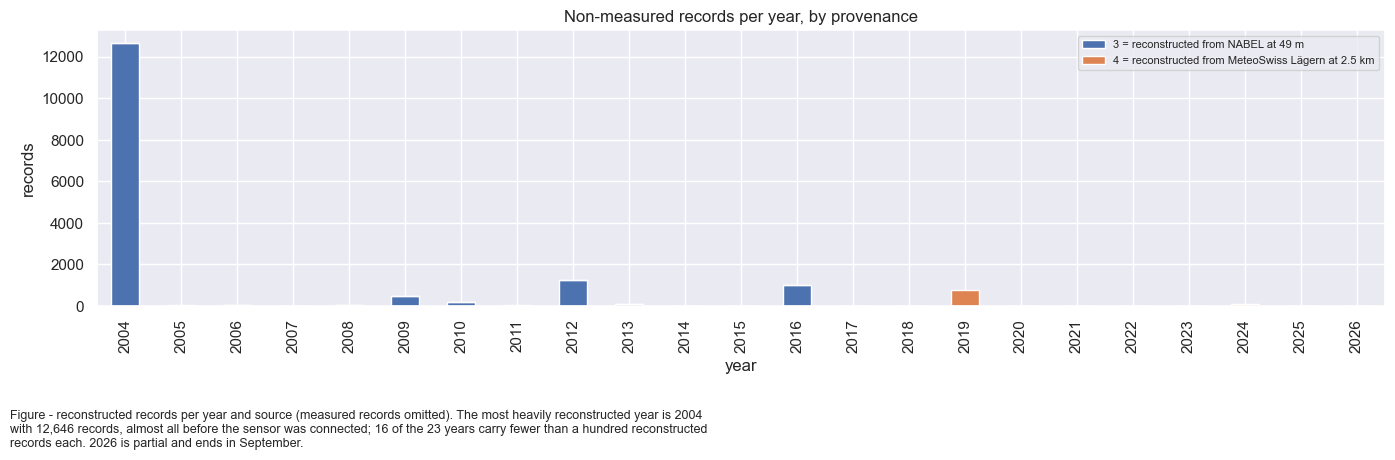

In [73]:
coverage_stats_by_year(export_df[VALCOL], export_df[FLAGCOL])

### Plots

#### 📊 Plot: heatmaps of value, measured records and provenance

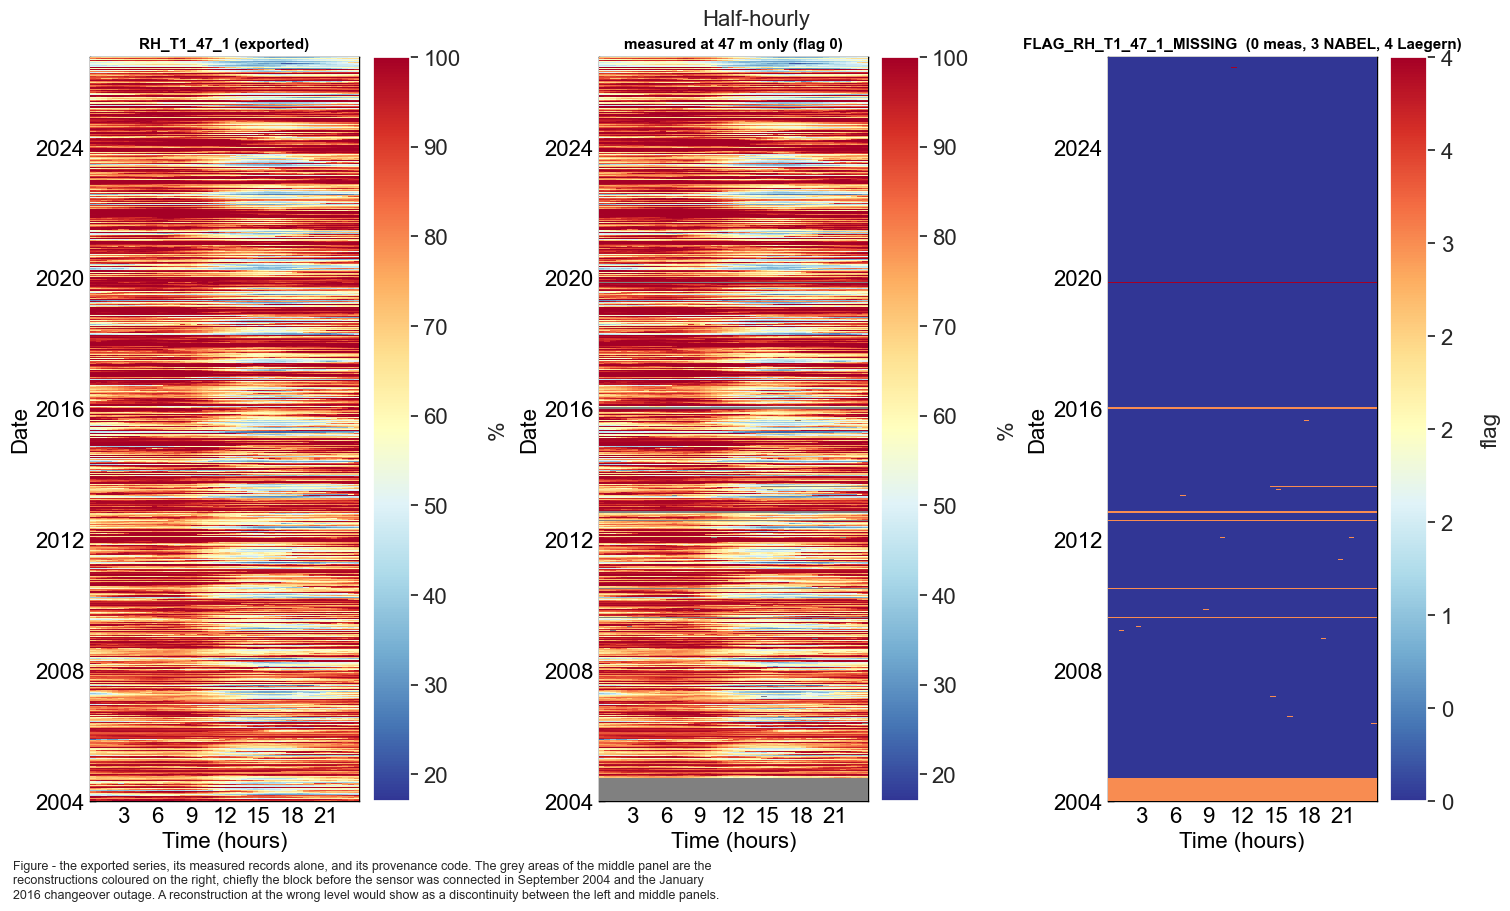

In [74]:
fig, axs = plt.subplots(ncols=3, figsize=(15, 9), dpi=100, layout="constrained")
fig.suptitle('Half-hourly', fontsize=16)
dv.plotting.HeatmapDateTime(series=export_df[VALCOL]).plot(
    ax=axs[0], cb_digits_after_comma=0, zlabel='%',
    format_style=dv.plotting.FormatStyle(title=f'{VALCOL} (exported)', title_fontsize=11))
dv.plotting.HeatmapDateTime(series=export_df[VALCOL].where(export_df[FLAGCOL] == 0)).plot(
    ax=axs[1], cb_digits_after_comma=0, zlabel='%',
    format_style=dv.plotting.FormatStyle(title='measured at 47 m only (flag 0)', title_fontsize=11))
dv.plotting.HeatmapDateTime(series=export_df[FLAGCOL].astype(float)).plot(
    ax=axs[2], cb_digits_after_comma=0, zlabel='flag',
    format_style=dv.plotting.FormatStyle(title=f'{FLAGCOL}  (0 meas, 3 NABEL, 4 Laegern)',
                                         title_fontsize=11))
figcap(fig, "the exported series, its measured records alone, and its provenance code. The grey "
            "areas of the middle panel are the reconstructions coloured on the right, chiefly "
            "the block before the sensor was connected in September 2004 and the January 2016 "
            "changeover outage. A reconstruction at the wrong level would show as a "
            "discontinuity between the left and middle panels.")


#### 📊 Plot: values by provenance class

array([<Axes: xlabel='TIMESTAMP_MIDDLE', ylabel='RH (%)'>,
       <Axes: xlabel='TIMESTAMP_MIDDLE', ylabel='RH (%)'>,
       <Axes: xlabel='TIMESTAMP_MIDDLE', ylabel='RH (%)'>,
       <Axes: xlabel='TIMESTAMP_MIDDLE', ylabel='RH (%)'>,
       <Axes: xlabel='TIMESTAMP_MIDDLE', ylabel='flag'>], dtype=object)

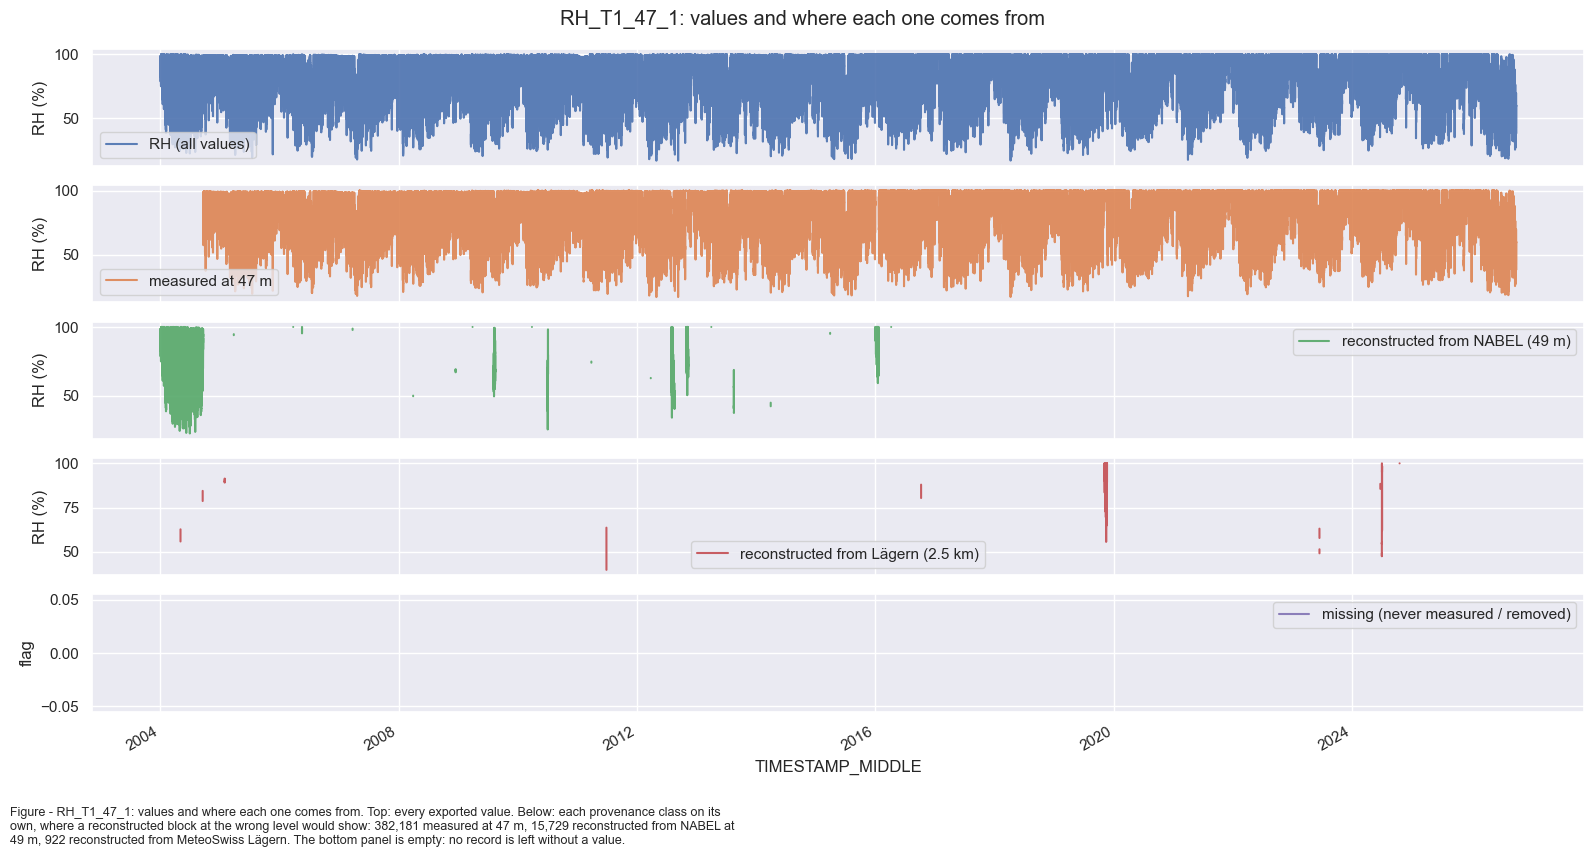

In [75]:
plot_presence_panels(export_df[VALCOL], export_df[FLAGCOL],
                     title=f'{VALCOL}: values and where each one comes from')

***

## 💾 Save to file

In [76]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\04_METEO_RH_CORRECTED_2004-2026.09.parquet (0.073 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\04_METEO_RH_CORRECTED_2004-2026.09.parquet


Read the written file back and compare it with the frame in memory. Reading the parquet is what
the downstream notebooks do.

In [77]:
_check = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))
print(f"Columns:      {list(_check.columns)}")
print(f"Records:      {len(_check):,}")
print(f"Range:        {_check.index[0]} -> {_check.index[-1]}")
print(f"Index name:   {_check.index.name}")
print(f"Missing:      {_check[VALCOL].isna().sum():,}")
print(f"Min / max:    {_check[VALCOL].min():.2f} / {_check[VALCOL].max():.2f} %")
print(f"Flag counts:  {_check[FLAGCOL].value_counts().sort_index().to_dict()}")
print(f"Source codes: {_check[SRCCOL].value_counts().sort_index().to_dict()}")

assert list(_check.columns) == list(export_df.columns), "the written columns differ"
assert _check[VALCOL].equals(export_df[VALCOL]), "values differ from what was written"
assert _check[HOMCOL].equals(export_df[HOMCOL]), "homogenised values differ from what was written"
assert _check[FLAGCOL].equals(export_df[FLAGCOL]), "flags differ from what was written"
assert _check[SRCCOL].equals(export_df[SRCCOL]), "source flags differ from what was written"
assert (_check[VALCOL].notna() == _check[FLAGCOL].isin(PRESENT_FLAGS)).all(), "flag/value disagreement in written file"
print("\nWritten file matches the exported dataframe.")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\04_METEO_RH_CORRECTED_2004-2026.09.parquet (0.014 seconds).

Columns:      ['RH_T1_47_1', 'FLAG_RH_T1_47_1_MISSING', 'RH_T1_47_1_HOMOGENIZED', 'FLAG_RH_T1_47_1_SOURCE']
Records:      398,832
Range:        2004-01-01 00:15:00 -> 2026-09-30 23:45:00
Index name:   TIMESTAMP_MIDDLE
Missing:      0
Min / max:    16.99 / 100.00 %
Flag counts:  {0: 382181, 3: 15729, 4: 922}
Source codes: {0: 153428, 1: 197739, 2: 988, 3: 12645, 4: 5641, 5: 2, 6: 18482, 7: 9907}

Written file matches the exported dataframe.


***

## ⚠️ Note for downstream notebooks

This product is **complete**. `FLAG_RH_T1_47_1_MISSING`:

- `0`: measured at 47 m and corrected, the only genuine measurements of this sensor.
- `3`: reconstructed from NABEL at 49 m on the same tower, about **3 % RH** uncertainty.
- `4`: reconstructed from MeteoSwiss Lägern, same method, larger uncertainty; almost all after
  2018.
- `1` / `2`: in the legend, but do not occur.

For uncertainty estimates, or fits with `RH` as the independent variable, consider excluding `3`
and `4`.

**Which value column to use.**

- Within one sensor era: `RH_T1_47_1`, the values the probe reported.
- Across **21 January 2016** or **5 June 2026**: `RH_T1_47_1_HOMOGENIZED`, on the CS215 level.
  `RH_T1_47_1` steps upwards by 2 to 4 percentage points at the first date and becomes drier,
  increasingly so with the humidity, at the second. The difference between the two columns is not
  a constant: it depends on the humidity, is zero on the CS215, and is small at saturation before
  2016.
- For trends over many years, neither column is sufficient on its own: the drift within each era
  (step 🔟) is not corrected, so a long trend carries sensor movement.
- The 2016 correction is fitted against NABEL and scored against Lägern. Fitted against Lägern it
  would be larger by several tenths of a percentage point on average and by up to about two just
  below saturation (step 🔟); treat that as its uncertainty, largest in humid conditions.
- **Codes `7` and `6`** (22 October 2024 to 5 June 2026) are left as measured in both columns. In
  sun code `7` reads low and code `6` higher than the normal CS215, both from the probe's
  temperature (step 1️⃣1️⃣); exclude them, or use daily means with care, wherever the sun-dependent
  part of `RH` matters.
- From 5 June 2026 the homogenised `RH` is relative to `02`'s homogenised temperature (step
  1️⃣2️⃣), so it lies above what the CS215 read in sun and agrees with it at night. VPD computed
  from it with `02`'s homogenised `TA` is consistent.

`FLAG_RH_T1_47_1_SOURCE` carries `02`'s codes and is asserted to agree with
`FLAG_TA_T1_47_1_SOURCE` once `02` writes codes `6` and `7`. The HygroVUE10 transfer is fitted on
June to September 2026 and applied unchanged to later months. Its month hold-out residuals follow
the season (negative in June and July, positive in September, step 1️⃣2️⃣), so monthly means of the
homogenised HygroVUE10 era carry a seasonal error of a few tenths of a hPa in vapour pressure.

::: {.callout-important title="What notebook 07 has to know"}
`07` computes VPD from `TA` and `RH` and reads `FLAG_RH_T1_47_1_MISSING`. Fitting the
reconstruction offsets per sensor era moved **609 exported values** in 2014-2016, by at most 1.8 %
RH; re-run `07`, then `99`. `TA` and `RH` now both have a homogenised column, and VPD across 2016
or June 2026 should be computed from the two homogenised columns together; `FLAG_RH_T1_47_1_SOURCE`
is not yet propagated. The Lägern offsets are now fitted per probe state, which can move
Lägern-reconstructed CS215 records of 2022 to 2026; re-run `07` and `99` for this as well. This
notebook now reads `02`'s product, so the order is `02`, `04`, `07`.
:::

`TA` (notebook `02`) and `RH` arrive complete, so the VPD of `07` inherits no gaps from `RH`.


## End of notebook.


In [78]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-22 17:43:46
Finished: 2026-10-22 17:44:38
Runtime:  00:00:52 (hh:mm:ss)
